# Beyond the Pixels: Satellite-Based Land-Cover Classification Using Machine Learning

**Dataset:** Statlog (Landsat Satellite), UCI Machine Learning Repository
**Task:** Multiclass supervised classification of land cover from multispectral pixel neighbourhoods
**Environment:** Google Colab (the notebook downloads the data itself, so it runs top to bottom with *Runtime > Run all*)

---

## 1. Project Overview

### 1.1 Introduction

Satellite remote sensing enables the observation of the Earth's surface by measuring electromagnetic energy reflected or emitted by different materials. Different land-cover types, such as forests, water bodies, agricultural areas, and urban regions, exhibit different spectral characteristics.

Machine learning can use these spectral measurements to identify patterns and classify land-cover types automatically. This project investigates the use of supervised machine learning algorithms to classify satellite observations into predefined land-cover categories.

### 1.2 Problem Statement

Manually interpreting satellite imagery can be time-consuming, particularly when large amounts of geographical data must be analysed. Automated classification can help identify land-cover patterns more efficiently. However, different land-cover categories may have similar spectral characteristics, making accurate classification challenging.

The problem addressed in this project is to develop and evaluate machine learning models that classify land-cover categories using numerical spectral measurements from satellite data.

### 1.3 Project Objectives

1. Understand and document the satellite land-cover dataset.
2. Perform exploratory data analysis to investigate data quality, feature distributions, and relationships between variables.
3. Prepare the dataset for supervised machine learning (scaling, validation protocol, feature engineering).
4. Train and compare a broad family of classification algorithms, from trivial baselines to ensembles.
5. Evaluate model performance using appropriate classification metrics, statistical tests and error analysis.
6. Investigate whether incorporating spectral information from neighbouring pixels improves classification performance compared with using only the central pixel's spectral measurements.

### 1.4 Research Questions

- **RQ1.** Can machine learning accurately classify land-cover types using satellite spectral measurements?
- **RQ2.** Does incorporating information from neighbouring pixels improve classification performance?
- **RQ3.** Which model family (nearest neighbour, probabilistic, linear, tree, ensemble) suits this data best, and why?

### 1.5 Project Scope

This project focuses on multiclass classification using an existing, publicly available dataset. It evaluates model performance on labelled satellite observations and investigates the contribution of neighbourhood information. The results are specific to this dataset and do not automatically establish how well the models will perform on every geographical region or satellite sensor.

### 1.6 Syllabus Coverage Map

The notebook is organised so that every syllabus topic has its own section with theory, code, visualisations and interpretation.

| Syllabus topic | Where it is covered |
|---|---|
| Supervised learning, classification problems | Sections 1, 7, 8 |
| Good and bad classifiers | Section 8 (baselines, metrics, under/overfitting) and Section 16 (calibration, significance tests) |
| Decision boundaries | Section 9 (12 classifiers drawn in the same 2D space), Sections 10 and 12 |
| Nearest neighbour methods | Section 10 |
| Probability and classification, Bayes' rule | Section 11 |
| Bayes optimal decisions (incl. cost-sensitive decisions) | Section 11.5 |
| Gaussian class-conditional distributions (LDA, QDA, from scratch) | Section 11.2 to 11.4 |
| Naive Bayes model | Section 11.6 |
| Linear classifiers | Section 12 |
| Decision trees | Section 13 |
| Ensemble methods: bagging, random forests, boosting | Section 14 |
| **Beyond the syllabus:** SVM, neural network, XGBoost, LightGBM, stacking, feature engineering, calibration, McNemar test, bootstrap confidence intervals, error analysis | Sections 15 to 18 |

## 2. Dataset Description

### 2.1 Dataset Source

This project uses the Statlog (Landsat Satellite) dataset from the UCI Machine Learning Repository.

**Official source:** https://archive.ics.uci.edu/dataset/146/statlog+landsat+satellite

The data was generated from Landsat Multi-Spectral Scanner (MSS) imagery of a small 82 x 100 pixel area in Australia. Every pixel was labelled on the basis of an actual site visit, so the labels are ground truth rather than another algorithm's output.

### 2.2 Dataset Files

- `sat.trn`: 4,435 training observations.
- `sat.tst`: 2,000 test observations.
- `sat.doc`: documentation describing the dataset and its features.
- `Index`: repository metadata file.

### 2.3 Features and Target Variable

One Landsat MSS frame has **four spectral bands**: two in the visible region (approximately **green** and **red**) and two in the **near infra-red (NIR)**. Each pixel value is an 8-bit integer (0 = black, 255 = white) and covers roughly 80 m x 80 m on the ground.

Each row describes a **3 x 3 neighbourhood** of pixels, giving 9 pixels x 4 bands = **36 numerical features**, read left to right and top to bottom. Attributes 17 to 20 are the four bands of the **central pixel**, and the label is the land-cover class of that central pixel.

| Code | Class | Notes |
|---|---|---|
| 1 | Red soil | |
| 2 | Cotton crop | the only vegetated class, so it should be bright in NIR |
| 3 | Grey soil | |
| 4 | Damp grey soil | expected to be confused with 3 and 7 |
| 5 | Soil with vegetation stubble | |
| 6 | Mixture class | **no examples in this dataset** |
| 7 | Very damp grey soil | |

### 2.4 An Important Note from the Dataset Authors

The documentation states: *do not use cross-validation with this dataset; train and test only once with the supplied training and test sets.* The reason is that neighbouring 3 x 3 windows **overlap** (two adjacent windows share 6 of their 9 pixels). Randomly re-splitting the rows therefore places near-duplicate rows on both sides of the split, which inflates scores. We respect this:

- The supplied **test set is touched only for the final evaluation** of each model.
- Hyperparameters are chosen on **one stratified hold-out validation split** carved out of the training file (Section 7.4). We keep in mind that this validation estimate can be slightly optimistic for the same reason, so the test set remains the honest judge.

## 3. Environment Setup

All libraries below are pre-installed on Google Colab. XGBoost and LightGBM are optional: if either is missing, the notebook skips it and carries on.

In [1]:
import warnings, time, io, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown

from scipy import stats
from scipy.stats import multivariate_normal

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.preprocessing import StandardScaler, LabelEncoder, PolynomialFeatures, label_binarize
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_selection import f_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, cohen_kappa_score,
                             classification_report, confusion_matrix, log_loss,
                             roc_curve, auc, precision_recall_curve, average_precision_score)

from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression, Perceptron, RidgeClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, VotingClassifier, StackingClassifier)
from sklearn.neural_network import MLPClassifier

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

import sklearn
print("scikit-learn", sklearn.__version__, "| XGBoost available:", HAS_XGB, "| LightGBM available:", HAS_LGBM)

scikit-learn 1.6.1 | XGBoost available: True | LightGBM available: True


In [2]:
# ---- Consistent visual style for every figure in the notebook ----
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelsize": 10,
    "legend.frameon": False, "font.size": 10,
})

CLASS_NAMES = {1: "Red soil", 2: "Cotton crop", 3: "Grey soil",
               4: "Damp grey soil", 5: "Veg. stubble", 7: "Very damp grey soil"}
CLASSES = np.array(sorted(CLASS_NAMES))
# One fixed colour per class, used in every plot (colour follows the class, never its rank)
CLASS_COLORS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a", 4: "#eda100", 5: "#e87ba4", 7: "#6250d6"}
CLASS_CMAP = ListedColormap([CLASS_COLORS[c] for c in CLASSES])
CLASS_LABELS = [f"{c}: {CLASS_NAMES[c]}" for c in CLASSES]

BAND_NAMES = {1: "Green", 2: "Red", 3: "NIR 1", 4: "NIR 2"}
FAMILY_COLORS = {"Baseline": "#9a9a96", "Nearest neighbour": "#2a78d6", "Probabilistic": "#eb6834",
                 "Linear": "#1baf7a", "Decision tree": "#eda100", "Ensemble": "#6250d6",
                 "Kernel / neural": "#e87ba4"}

## 4. Loading and Understanding the Dataset

The dataset is provided in two separate files: `sat.trn` and `sat.tst`. The files do not have a header row, so column names are assigned programmatically. The cell below downloads the official archive from UCI (or reuses a local copy if one already exists next to the notebook).

In [3]:
DATA_DIR = Path("statlog+landsat+satellite")
URL = "https://archive.ics.uci.edu/static/public/146/statlog+landsat+satellite.zip"

if not (DATA_DIR / "sat.trn").exists():
    DATA_DIR.mkdir(exist_ok=True)
    with urllib.request.urlopen(URL) as response:
        zipfile.ZipFile(io.BytesIO(response.read())).extractall(DATA_DIR)
    print("Downloaded dataset from UCI.")
print("Files:", sorted(p.name for p in DATA_DIR.iterdir()))

# Load whitespace-separated data without headers
df_train = pd.read_csv(DATA_DIR / "sat.trn", sep=r"\s+", header=None)
df_test = pd.read_csv(DATA_DIR / "sat.tst", sep=r"\s+", header=None)
print("Training dataset shape:", df_train.shape)
print("Test dataset shape:", df_test.shape)

Downloaded dataset from UCI.
Files: ['Index', 'sat.doc', 'sat.trn', 'sat.tst']
Training dataset shape: (4435, 37)
Test dataset shape: (2000, 37)


In [4]:
# Pixel positions in reading order: left to right, top to bottom
pixel_positions = ["top_left", "top_middle", "top_right",
                   "middle_left", "center", "middle_right",
                   "bottom_left", "bottom_middle", "bottom_right"]

# Each pixel has four spectral-band measurements
feature_names = [f"{position}_band_{band}" for position in pixel_positions for band in range(1, 5)]
TARGET = "land_cover_class"
column_names = feature_names + [TARGET]
df_train.columns = column_names
df_test.columns = column_names

center_features = [f"center_band_{b}" for b in range(1, 5)]
print("Number of input features:", len(feature_names))
print("Central pixel features (attributes 17 to 20):", center_features)
display(df_train.head())

Number of input features: 36
Central pixel features (attributes 17 to 20): ['center_band_1', 'center_band_2', 'center_band_3', 'center_band_4']


,top_left_band_1,top_left_band_2,top_left_band_3,top_left_band_4,top_middle_band_1,top_middle_band_2,top_middle_band_3,top_middle_band_4,top_right_band_1,top_right_band_2,...,bottom_left_band_4,bottom_middle_band_1,bottom_middle_band_2,bottom_middle_band_3,bottom_middle_band_4,bottom_right_band_1,bottom_right_band_2,bottom_right_band_3,bottom_right_band_4,land_cover_class
0,92,115,120,94,84,102,106,79,84,102,...,104,88,121,128,100,84,107,113,87,3
1,84,102,106,79,84,102,102,83,80,102,...,100,84,107,113,87,84,99,104,79,3
2,84,102,102,83,80,102,102,79,84,94,...,87,84,99,104,79,84,99,104,79,3
3,80,102,102,79,84,94,102,79,80,94,...,79,84,99,104,79,84,103,104,79,3
4,84,94,102,79,80,94,98,76,80,102,...,79,84,103,104,79,79,107,109,87,3


### 4.1 Data Quality Checks

Before any modelling we verify the record counts, data types, missing values, duplicates, the valid 0 to 255 range, and whether any row appears in **both** the training and the test file (which would leak test information into training).

In [5]:
quality = pd.DataFrame({
    "rows": [len(df_train), len(df_test)],
    "columns": [df_train.shape[1], df_test.shape[1]],
    "missing values": [df_train.isna().sum().sum(), df_test.isna().sum().sum()],
    "duplicate rows": [df_train.duplicated().sum(), df_test.duplicated().sum()],
    "all integer": [all(pd.api.types.is_integer_dtype(t) for t in df_train.dtypes),
                    all(pd.api.types.is_integer_dtype(t) for t in df_test.dtypes)],
    "min pixel value": [df_train[feature_names].values.min(), df_test[feature_names].values.min()],
    "max pixel value": [df_train[feature_names].values.max(), df_test[feature_names].values.max()],
}, index=["train", "test"])
display(quality)

overlap = df_train.merge(df_test, how="inner", on=column_names)
print("Rows that appear in BOTH train and test:", len(overlap))
print("Class labels in train:", sorted(df_train[TARGET].unique()), "| in test:", sorted(df_test[TARGET].unique()))

,rows,columns,missing values,duplicate rows,all integer,min pixel value,max pixel value
train,4435,37,0,0,True,27,157
test,2000,37,0,0,True,27,157


Rows that appear in BOTH train and test: 0
Class labels in train: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(7)] | in test: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(7)]


**Findings.** There are no missing values, all values are integers inside the valid 8-bit range, and the classes are the six documented ones (class 6 is absent, as the documentation says). Any duplicate or train/test overlapping rows reported above are tiny in number and are consistent with genuinely identical neighbourhoods in a homogeneous field, so they are kept rather than removed. No imputation or cleaning is needed; the preprocessing effort goes into scaling, validation design and feature engineering instead.

In [6]:
display(df_train[feature_names].describe().T.style.background_gradient(cmap="Blues", subset=["mean", "std"]).format("{:.1f}"))

,count,mean,std,min,25%,50%,75%,max
top_left_band_1,4435.0,69.5,13.6,40.0,60.0,68.0,80.0,104.0
top_left_band_2,4435.0,83.9,22.7,27.0,71.0,87.0,103.0,137.0
top_left_band_3,4435.0,99.3,16.7,56.0,85.0,101.0,113.0,140.0
top_left_band_4,4435.0,82.6,18.7,33.0,70.0,83.0,92.0,154.0
top_middle_band_1,4435.0,69.2,13.6,40.0,60.0,68.0,80.0,102.0
top_middle_band_2,4435.0,83.5,22.8,27.0,71.0,85.0,103.0,137.0
top_middle_band_3,4435.0,99.2,16.6,50.0,85.0,101.0,113.0,145.0
top_middle_band_4,4435.0,82.5,18.7,29.0,69.0,81.0,92.0,157.0
top_right_band_1,4435.0,69.0,13.5,40.0,60.0,67.0,79.0,104.0
top_right_band_2,4435.0,83.1,22.8,27.0,71.0,85.0,103.0,130.0


## 5. Automated Profiling (optional)

An automated profile (`ydata-profiling`, formerly pandas-profiling) of the training data was generated earlier in the project and saved as `satellite_profiling_report.html`. Installing the profiler on Colab can conflict with pre-installed packages, so it is switched **off** by default. Set `RUN_PROFILING = True` to regenerate it. All the important findings from the profile are reproduced by hand, with more targeted plots, in Section 6.

In [8]:
RUN_PROFILING = True

if RUN_PROFILING:
    !pip -q install ydata-profiling
    from ydata_profiling import ProfileReport
    profile_df = df_train.copy()
    profile_df[TARGET] = profile_df[TARGET].astype("category")
    profile = ProfileReport(profile_df, title="Satellite Land-Cover: Training Data Profile", minimal=True)
    profile.to_file("satellite_profiling_report.html")
    profile.to_notebook_iframe()
else:
    print("Profiling skipped (set RUN_PROFILING = True to generate the HTML report).")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 75.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 3.1 MB/s eta 0:00:00


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 37/37 [00:00<00:00, 95.94it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

## 6. Exploratory Data Analysis

EDA answers four questions that directly shape the modelling choices:

1. **Is the target balanced?** (affects which metrics are trustworthy)
2. **How separable are the classes spectrally?** (tells us which classes will be confused)
3. **How strongly are the features correlated?** (Naive Bayes assumes independence; linear models suffer from collinearity)
4. **Is the neighbourhood informative?** (the core research question RQ2)

### 6.1 Class Distribution

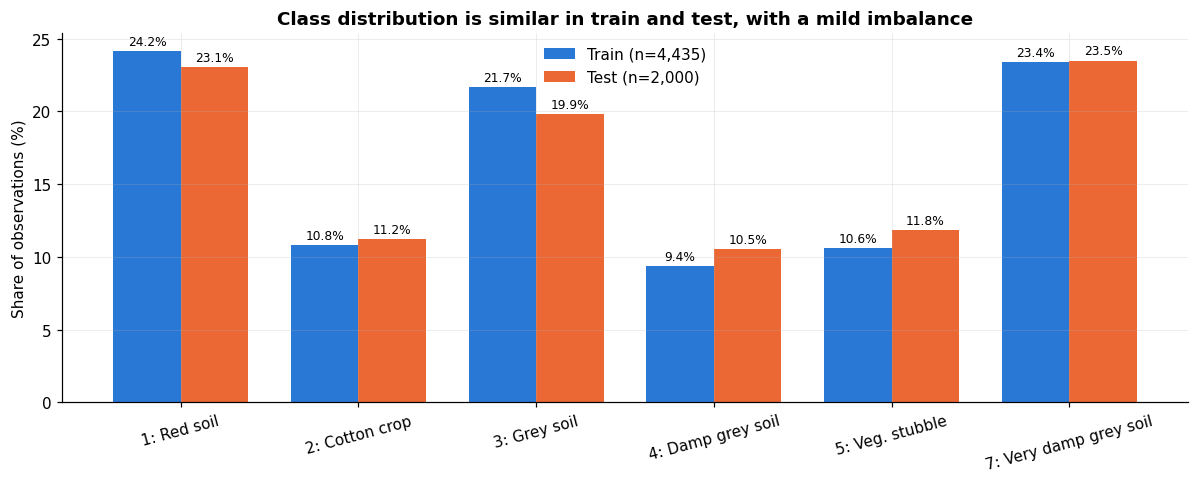

Imbalance ratio (largest / smallest class in train): 2.58


In [9]:
dist = pd.DataFrame({
    "Train": df_train[TARGET].value_counts(normalize=True).sort_index() * 100,
    "Test": df_test[TARGET].value_counts(normalize=True).sort_index() * 100,
})
counts = df_train[TARGET].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(dist)); w = 0.38
b1 = ax.bar(x - w / 2, dist["Train"], w, color="#2a78d6", label="Train (n=4,435)")
b2 = ax.bar(x + w / 2, dist["Test"], w, color="#eb6834", label="Test (n=2,000)")
for bars in (b1, b2):
    ax.bar_label(bars, fmt="%.1f%%", fontsize=8, padding=2)
ax.set_xticks(x, [CLASS_LABELS[i] for i in range(len(CLASSES))], rotation=15)
ax.set_ylabel("Share of observations (%)")
ax.set_title("Class distribution is similar in train and test, with a mild imbalance")
ax.legend()
plt.tight_layout(); plt.savefig("fig_class_distribution.png", bbox_inches="tight"); plt.show()

print(f"Imbalance ratio (largest / smallest class in train): {counts.max() / counts.min():.2f}")

**Interpretation.** The largest class (red soil) is about 2.6 times the smallest (damp grey soil). This is a *mild* imbalance: no resampling is required, but plain accuracy can hide poor performance on the small classes, so we also report **balanced accuracy** and **macro F1**, which weight each class equally. Train and test have nearly identical class proportions, so the test set is representative.

### 6.2 Spectral Signatures of Each Class

A spectral signature is the mean reflectance of a material across the bands. If two classes have very similar signatures, no classifier will separate them easily.

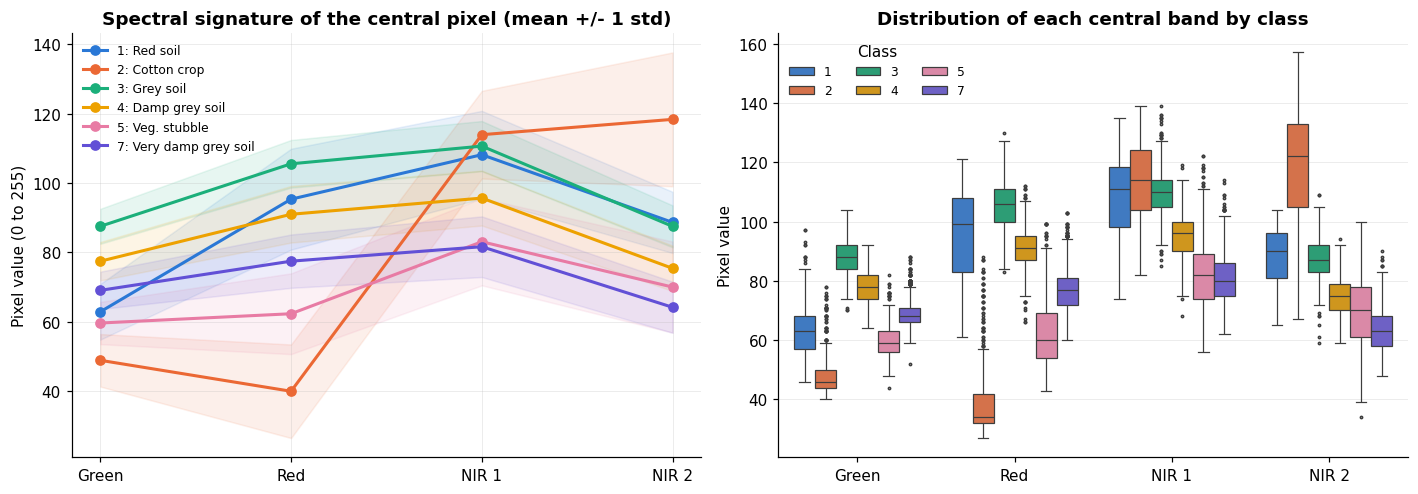

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
bands = list(BAND_NAMES.values())
for c in CLASSES:
    sub = df_train.loc[df_train[TARGET] == c, center_features]
    m, s = sub.mean().values, sub.std().values
    axes[0].plot(bands, m, marker="o", lw=2, color=CLASS_COLORS[c], label=CLASS_LABELS[list(CLASSES).index(c)])
    axes[0].fill_between(bands, m - s, m + s, color=CLASS_COLORS[c], alpha=0.10)
axes[0].set_title("Spectral signature of the central pixel (mean +/- 1 std)")
axes[0].set_ylabel("Pixel value (0 to 255)")
axes[0].legend(fontsize=8, loc="upper left")

melted = df_train.melt(id_vars=TARGET, value_vars=center_features, var_name="band", value_name="value")
melted["band"] = melted["band"].map(lambda s: BAND_NAMES[int(s[-1])])
sns.boxplot(data=melted, x="band", y="value", hue=TARGET, palette=CLASS_COLORS, ax=axes[1],
            fliersize=1.5, linewidth=0.8)
axes[1].set_title("Distribution of each central band by class")
axes[1].set_xlabel(""); axes[1].set_ylabel("Pixel value")
axes[1].legend(title="Class", fontsize=8, ncol=3)
plt.tight_layout(); plt.savefig("fig_spectral_signatures.png", bbox_inches="tight"); plt.show()

**Interpretation.**

- **Cotton crop (class 2)** has the lowest red value and a high NIR value. That is the classic signature of healthy vegetation (chlorophyll absorbs red light, leaf structure reflects NIR), so it should be the easiest class to recognise.
- **Red soil (class 1)** is bright in the visible bands and is also well separated.
- **Grey soil (3), damp grey soil (4) and very damp grey soil (7)** follow the *same shape* and differ mainly in overall brightness: moisture darkens soil. Their boxes overlap strongly in every band, so we already expect most classification errors to occur between these three classes, and especially for class 4, which sits between 3 and 7.

### 6.3 Pairwise Relationships Between the Central Bands

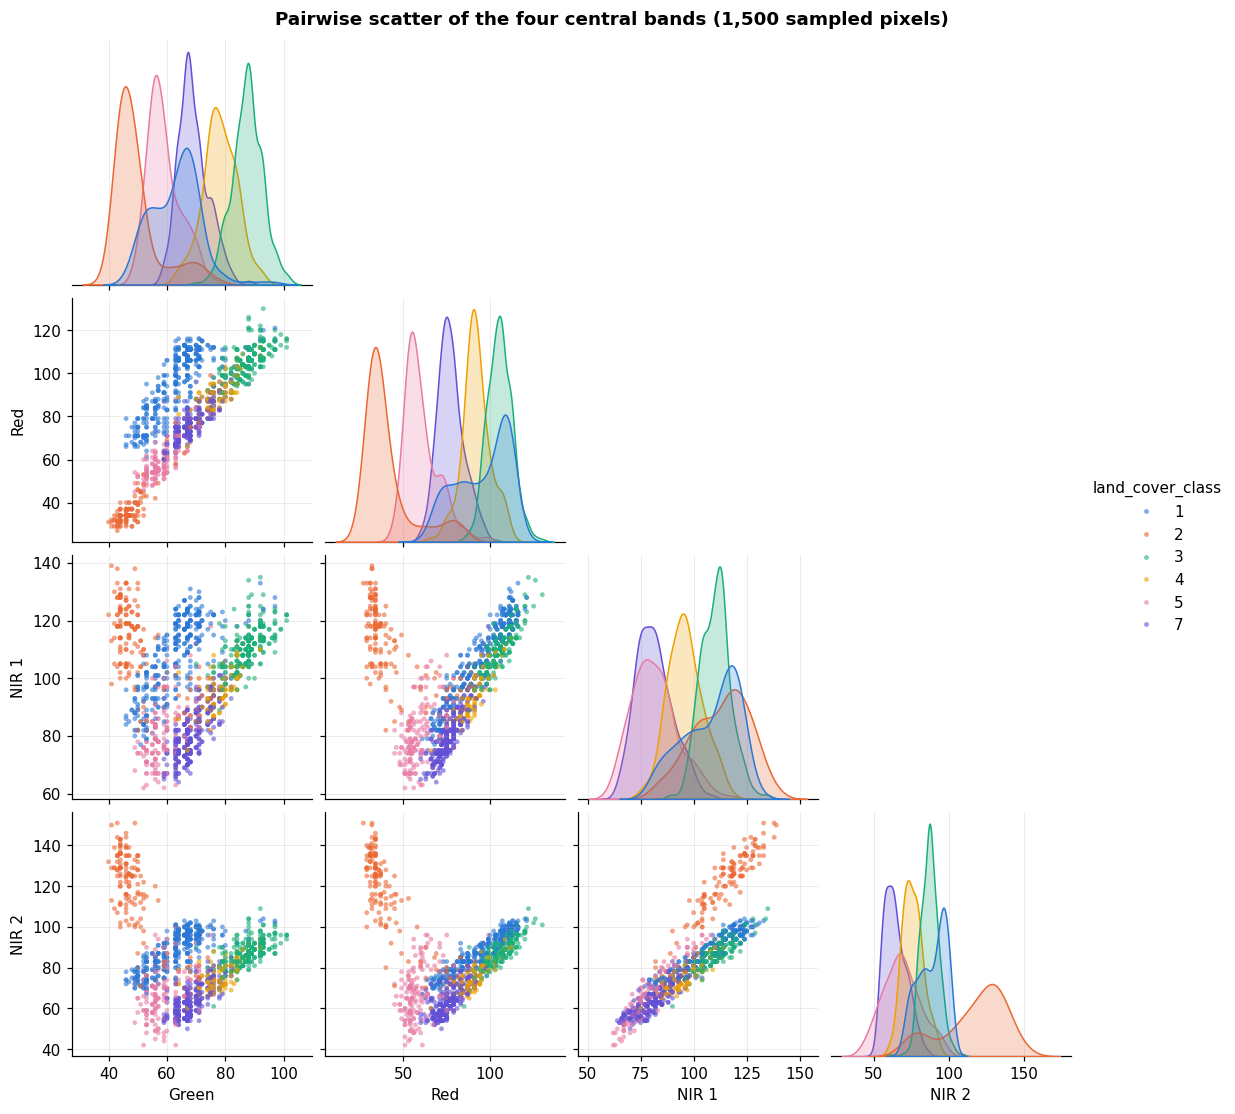

In [11]:
sample = df_train.sample(1500, random_state=SEED)
pp = sample[center_features + [TARGET]].rename(columns={f"center_band_{b}": BAND_NAMES[b] for b in range(1, 5)})
g = sns.pairplot(pp, hue=TARGET, palette=CLASS_COLORS, corner=True, plot_kws=dict(s=10, alpha=0.6, linewidth=0),
                 diag_kws=dict(common_norm=False))
g.figure.suptitle("Pairwise scatter of the four central bands (1,500 sampled pixels)", y=1.01, fontweight="bold")
plt.show()

**Interpretation.** The two visible bands (Green and Red) are almost perfectly correlated with each other, and so are the two NIR bands. The useful information is therefore close to **two-dimensional** (visible brightness versus NIR brightness). In the Red versus NIR panels, the clusters form a curved "soil line" from very damp grey soil (dark) to red soil (bright), with cotton crop pulled away from it. The clusters are roughly elliptical, which supports trying **Gaussian class-conditional models** (Section 11).

### 6.4 Correlation Structure of All 36 Features

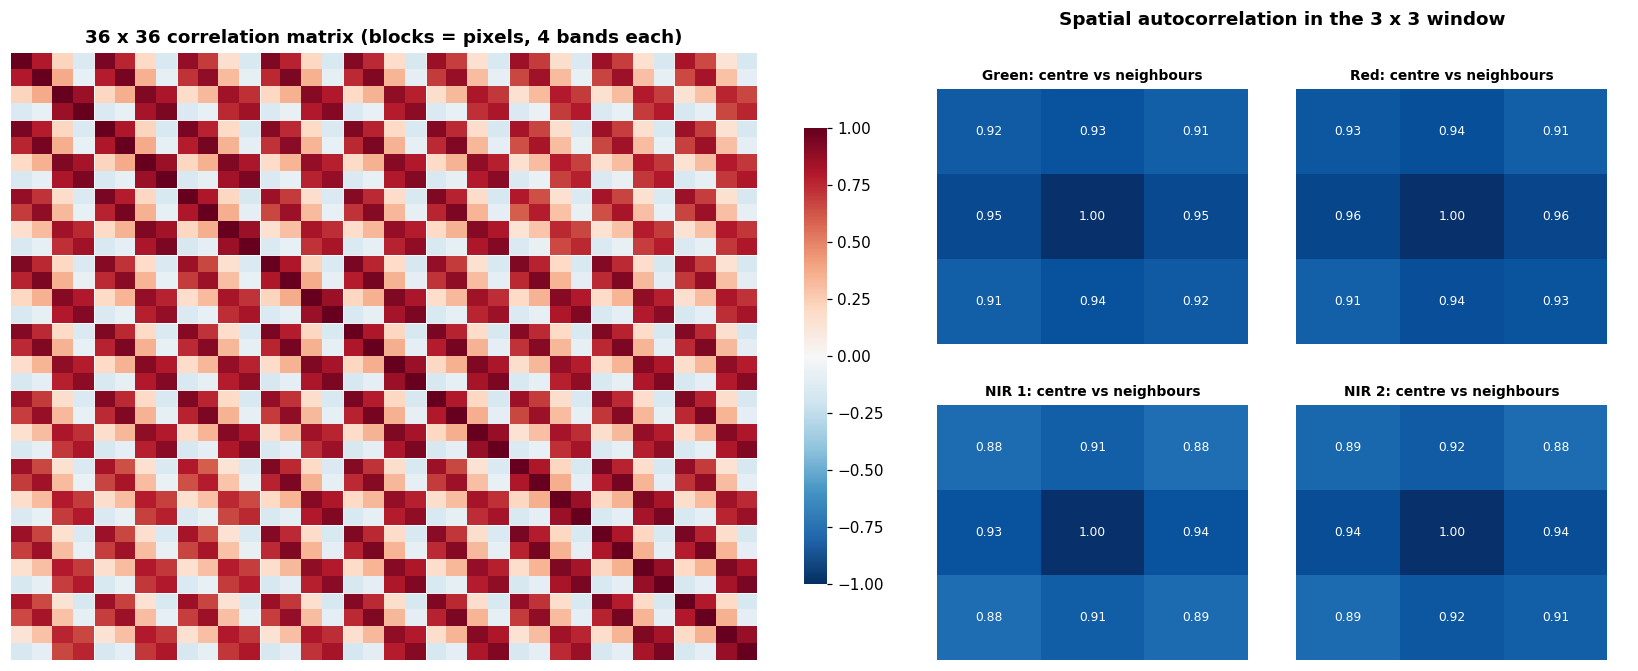

Mean absolute pairwise correlation: 0.493
Share of feature pairs with |r| > 0.8: 26.8%


In [12]:
corr = df_train[feature_names].corr()
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.35, 1]})
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=axes[0], cbar_kws={"shrink": 0.75},
            xticklabels=False, yticklabels=False)
for k in range(1, 9):
    axes[0].axhline(4 * k, color="white", lw=0.6); axes[0].axvline(4 * k, color="white", lw=0.6)
axes[0].set_title("36 x 36 correlation matrix (blocks = pixels, 4 bands each)")

# Correlation between the centre pixel and each neighbour, per band, laid out as the 3 x 3 window
grid = np.zeros((4, 3, 3))
for b in range(1, 5):
    for i, pos in enumerate(pixel_positions):
        grid[b - 1, i // 3, i % 3] = df_train[f"center_band_{b}"].corr(df_train[f"{pos}_band_{b}"])
axes[1].axis("off")
for b in range(4):
    ax = axes[1].inset_axes([(b % 2) * 0.52, 0.52 - (b // 2) * 0.52, 0.45, 0.42])
    sns.heatmap(grid[b], annot=True, fmt=".2f", cmap="Blues", vmin=0.5, vmax=1, cbar=False, ax=ax,
                xticklabels=False, yticklabels=False, annot_kws={"size": 8})
    ax.set_title(f"{BAND_NAMES[b + 1]}: centre vs neighbours", fontsize=9)
axes[1].set_title("Spatial autocorrelation in the 3 x 3 window", pad=18)
plt.tight_layout(); plt.savefig("fig_correlation.png", bbox_inches="tight"); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print(f"Mean absolute pairwise correlation: {upper.abs().mean():.3f}")
print(f"Share of feature pairs with |r| > 0.8: {(upper.abs() > 0.8).mean():.1%}")

**Interpretation.**

- The heatmap shows a strong repeating **4 x 4 block pattern**: within every pixel, visible bands correlate with visible bands and NIR with NIR, and the same pattern repeats between every pair of pixels.
- Neighbouring pixels are strongly correlated with the centre (spatial autocorrelation): land cover is spatially smooth, so neighbours usually share the centre's class. This is why neighbourhood features are expected to help (RQ2): they act like **eight extra noisy measurements of the same surface**, and averaging them reduces sensor noise.
- **Consequence for Naive Bayes:** its core assumption, that features are independent given the class, is heavily violated here. Naive Bayes will count the same evidence many times and become overconfident (examined in Section 11.6).
- **Consequence for linear models:** strong collinearity makes individual coefficients unstable, so regularisation matters.

### 6.5 Neighbourhood Homogeneity and a Vegetation Index

Two derived quantities help explain the data:

- **Neighbourhood standard deviation** per band: low means the 3 x 3 window is uniform (inside a field), high means it straddles a boundary between land covers.
- **NDVI** (Normalised Difference Vegetation Index) $= \dfrac{NIR - Red}{NIR + Red}$, the standard remote-sensing vegetation indicator.

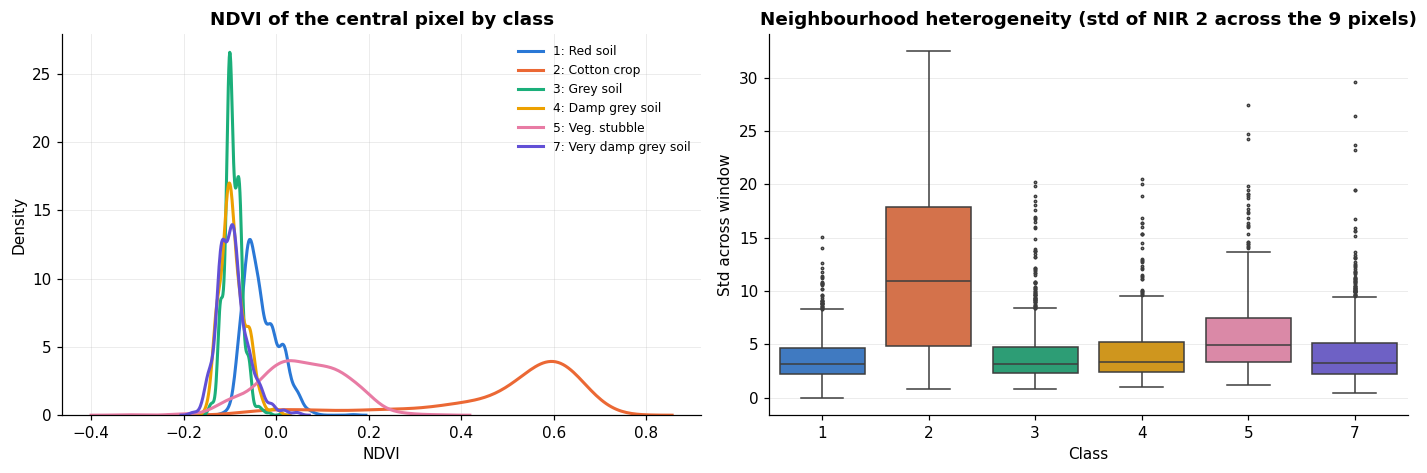

In [13]:
tmp = df_train.copy()
tmp["nbhd_std_NIR2"] = df_train[[f"{p}_band_4" for p in pixel_positions]].std(axis=1)
tmp["NDVI"] = (df_train["center_band_4"] - df_train["center_band_2"]) / (df_train["center_band_4"] + df_train["center_band_2"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for c in CLASSES:
    sns.kdeplot(tmp.loc[tmp[TARGET] == c, "NDVI"], ax=axes[0], color=CLASS_COLORS[c], lw=2,
                label=CLASS_LABELS[list(CLASSES).index(c)], common_norm=False)
axes[0].set_title("NDVI of the central pixel by class"); axes[0].legend(fontsize=8)
sns.boxplot(data=tmp, x=TARGET, y="nbhd_std_NIR2", palette=CLASS_COLORS, ax=axes[1], fliersize=1.5, hue=TARGET, legend=False)
axes[1].set_title("Neighbourhood heterogeneity (std of NIR 2 across the 9 pixels)")
axes[1].set_xlabel("Class"); axes[1].set_ylabel("Std across window")
plt.tight_layout(); plt.savefig("fig_ndvi_homogeneity.png", bbox_inches="tight"); plt.show()

**Interpretation.** NDVI isolates cotton crop almost perfectly, confirming that a physically meaningful engineered feature can carry a lot of signal in a single number. The heterogeneity plot shows that some classes (cotton crop, vegetation stubble) occur in less uniform windows, which is consistent with them lying in smaller or irregular fields. High heterogeneity marks **mixed pixels at field boundaries**, which we expect to be a major source of errors (checked in Section 18).

### 6.6 Outliers

In [14]:
z = np.abs(stats.zscore(df_train[feature_names]))
iqr_out = ((df_train[feature_names] < df_train[feature_names].quantile(0.25) - 1.5 * (df_train[feature_names].quantile(0.75) - df_train[feature_names].quantile(0.25))) |
           (df_train[feature_names] > df_train[feature_names].quantile(0.75) + 1.5 * (df_train[feature_names].quantile(0.75) - df_train[feature_names].quantile(0.25))))
print(f"Rows with any |z| > 3: {(z > 3).any(axis=1).sum()} of {len(df_train)} ({(z > 3).any(axis=1).mean():.1%})")
print(f"Rows with any IQR outlier: {iqr_out.any(axis=1).sum()} ({iqr_out.any(axis=1).mean():.1%})")
print("\nIQR outliers by class (share of rows in that class):")
display((iqr_out.any(axis=1).groupby(df_train[TARGET]).mean() * 100).round(1).rename("% rows").to_frame().T)

Rows with any |z| > 3: 135 of 4435 (3.0%)
Rows with any IQR outlier: 380 (8.6%)

IQR outliers by class (share of rows in that class):


land_cover_class,1,2,3,4,5,7
% rows,0.0,74.1,0.2,0.2,4.3,0.2


**Decision: outliers are kept.** Pixel values are physically bounded (0 to 255) and every value lies well inside that range, so extreme values are not measurement errors. They are concentrated in specific classes (for example bright red soil or vegetated pixels), which means they are *real, class-informative* observations. Removing them would delete exactly the cases that make some classes recognisable. Models that are sensitive to scale (KNN, SVM, linear models, neural nets) get standardised inputs instead.

### 6.7 Low-Dimensional Views: PCA, LDA and t-SNE

Projecting the 36-dimensional data to 2D lets us *see* class separability.

- **PCA** (unsupervised) finds directions of maximum variance.
- **LDA** (supervised) finds directions that maximise between-class versus within-class variance.
- **t-SNE** (non-linear) preserves local neighbourhoods; it shows clusters but distances between clusters are not meaningful.

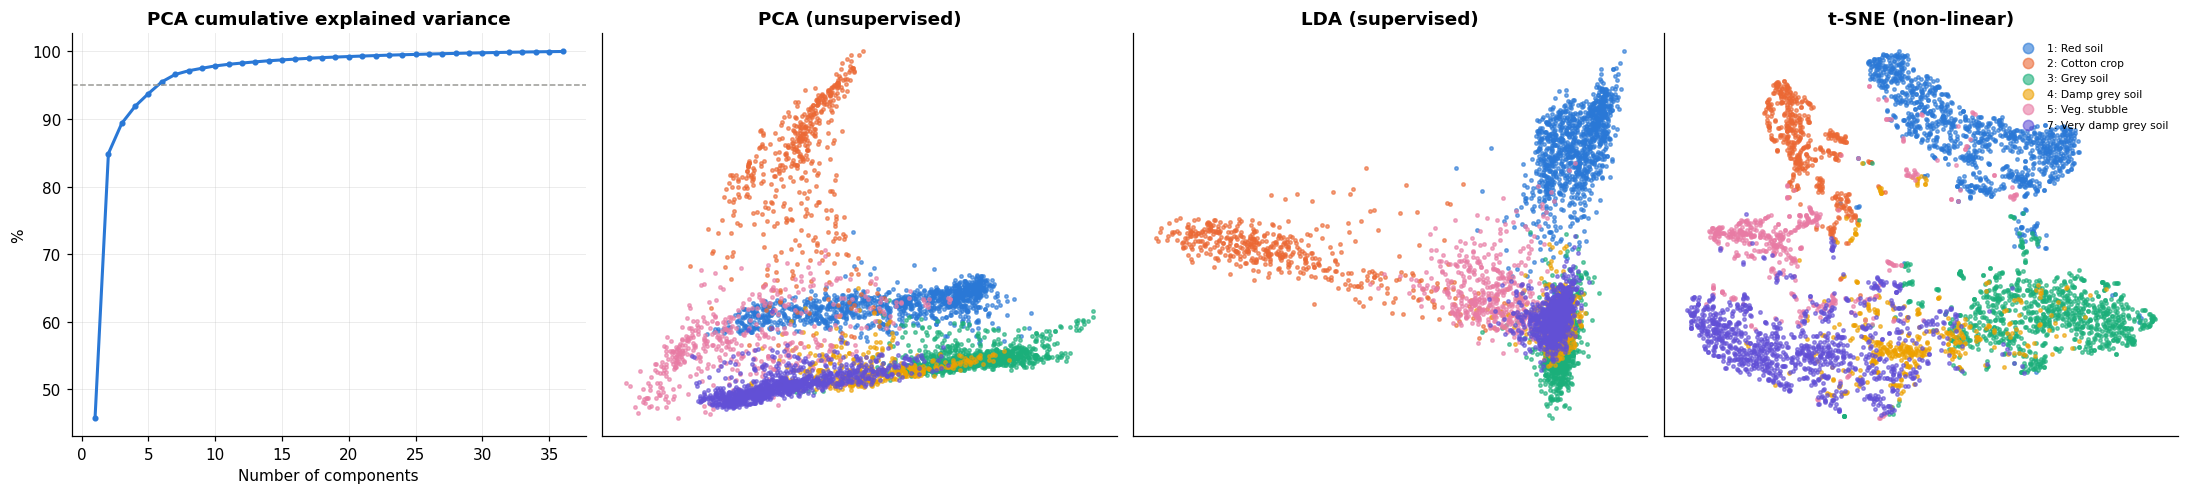

First 1 principal components explain 45.8% of the variance
First 2 principal components explain 84.9% of the variance
First 3 principal components explain 89.4% of the variance
First 5 principal components explain 93.8% of the variance


In [15]:
X_std_all = StandardScaler().fit_transform(df_train[feature_names])
y_all = df_train[TARGET].values

pca_full = PCA().fit(X_std_all)
cum = np.cumsum(pca_full.explained_variance_ratio_)
Z_pca = pca_full.transform(X_std_all)[:, :2]
Z_lda = LinearDiscriminantAnalysis(n_components=2).fit_transform(X_std_all, y_all)
Z_tsne = TSNE(n_components=2, perplexity=40, random_state=SEED, init="pca").fit_transform(X_std_all)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
axes[0].plot(np.arange(1, 37), cum * 100, marker="o", ms=3, color="#2a78d6", lw=2)
axes[0].axhline(95, color="#9a9a96", ls="--", lw=1)
axes[0].set_title("PCA cumulative explained variance"); axes[0].set_xlabel("Number of components"); axes[0].set_ylabel("%")
for ax, Z, title in [(axes[1], Z_pca, "PCA (unsupervised)"), (axes[2], Z_lda, "LDA (supervised)"), (axes[3], Z_tsne, "t-SNE (non-linear)")]:
    for c in CLASSES:
        m = y_all == c
        ax.scatter(Z[m, 0], Z[m, 1], s=5, alpha=0.6, color=CLASS_COLORS[c], label=CLASS_LABELS[list(CLASSES).index(c)])
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
axes[3].legend(fontsize=7, markerscale=3, loc="best")
plt.tight_layout(); plt.savefig("fig_projections.png", bbox_inches="tight"); plt.show()

for k in (1, 2, 3, 5):
    print(f"First {k} principal components explain {cum[k - 1]:.1%} of the variance")

**Interpretation.** Very few principal components explain almost all the variance, which confirms the heavy redundancy seen in the correlation matrix. In all three projections, red soil and cotton crop form clean separate clusters, while grey soil, damp grey soil and very damp grey soil form a **continuum** with damp grey soil in the middle. The t-SNE map shows that the classes are mostly locally coherent, which is good news for nearest-neighbour methods.

### 6.8 Key EDA Findings

| Finding | Modelling consequence |
|---|---|
| No missing values, valid ranges, negligible duplicates | No cleaning required |
| Mild class imbalance (2.6 : 1) | Report balanced accuracy and macro F1, use stratified splits |
| Grey soil classes (3, 4, 7) overlap spectrally | Expect most errors there, especially for class 4 |
| Very strong feature correlation and spatial autocorrelation | Naive Bayes assumption violated; regularise linear models; neighbourhood averaging should reduce noise |
| Roughly elliptical class clusters | Gaussian class-conditional models (LDA/QDA) are reasonable |
| Features on different scales across bands | Standardise for distance- and gradient-based models |

## 7. Data Preparation and Preprocessing

### 7.1 Supervised Learning Set-up

In supervised classification we are given labelled examples $\{(\mathbf{x}_i, y_i)\}_{i=1}^{n}$ with $\mathbf{x}_i \in \mathbb{R}^{d}$ and $y_i \in \{1, \dots, K\}$, and we learn a function $f: \mathbb{R}^d \to \{1,\dots,K\}$ that generalises to **unseen** data. Here $d = 36$ and $K = 6$. The quantity we actually care about is the expected error on new data, which we estimate with data the model has never seen.

### 7.2 Three Feature Sets (for RQ2)

| Feature set | Features | Purpose |
|---|---|---|
| `center` | 4 bands of the central pixel only | Does a single pixel suffice? |
| `full` | all 36 raw values of the 3 x 3 window | Main feature set, as supplied |
| `engineered` | 36 raw values + 18 derived features | Can domain knowledge help further? |

The **engineered** features are computed per row from that row alone (no information from other rows), so they cannot leak information between training and test:

- per band: neighbourhood **mean**, **standard deviation** and **range**, and **centre minus neighbourhood mean** (local contrast);
- **NDVI** of the centre and of the neighbourhood mean, centre **brightness**, and the **NIR / Red ratio**.

In [16]:
def engineer(df):
    out = df[feature_names].astype(float).copy()
    eps = 1e-6
    for b in range(1, 5):
        cols = [f"{p}_band_{b}" for p in pixel_positions]
        out[f"nbhd_mean_b{b}"] = df[cols].mean(axis=1)
        out[f"nbhd_std_b{b}"] = df[cols].std(axis=1)
        out[f"nbhd_range_b{b}"] = df[cols].max(axis=1) - df[cols].min(axis=1)
        out[f"center_minus_mean_b{b}"] = df[f"center_band_{b}"] - out[f"nbhd_mean_b{b}"]
    out["ndvi_center"] = (df["center_band_4"] - df["center_band_2"]) / (df["center_band_4"] + df["center_band_2"] + eps)
    out["ndvi_mean"] = (out["nbhd_mean_b4"] - out["nbhd_mean_b2"]) / (out["nbhd_mean_b4"] + out["nbhd_mean_b2"] + eps)
    out["brightness_center"] = df[center_features].mean(axis=1)
    out["nir_red_ratio_center"] = df["center_band_3"] / (df["center_band_2"] + eps)
    return out

y_train = df_train[TARGET].values
y_test = df_test[TARGET].values

FS_TRAIN = {"center": df_train[center_features].astype(float),
            "full": df_train[feature_names].astype(float),
            "engineered": engineer(df_train)}
FS_TEST = {"center": df_test[center_features].astype(float),
           "full": df_test[feature_names].astype(float),
           "engineered": engineer(df_test)}

for k in FS_TRAIN:
    print(f"{k:>10}: train {FS_TRAIN[k].shape}, test {FS_TEST[k].shape}")

    center: train (4435, 4), test (2000, 4)
      full: train (4435, 36), test (2000, 36)
engineered: train (4435, 56), test (2000, 56)


### 7.3 Feature Scaling

Distance-based (KNN, SVM) and gradient-based (logistic regression, neural network) models are sensitive to feature scale. We standardise each feature to zero mean and unit variance:

$$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

The mean and standard deviation are learned **only from training data**. Every scaled model is built as a scikit-learn `Pipeline(StandardScaler, model)`, so the scaler is automatically re-fitted inside whatever data the model is trained on. This makes leakage impossible by construction. Tree-based models split on thresholds and are scale invariant, so they use raw values.

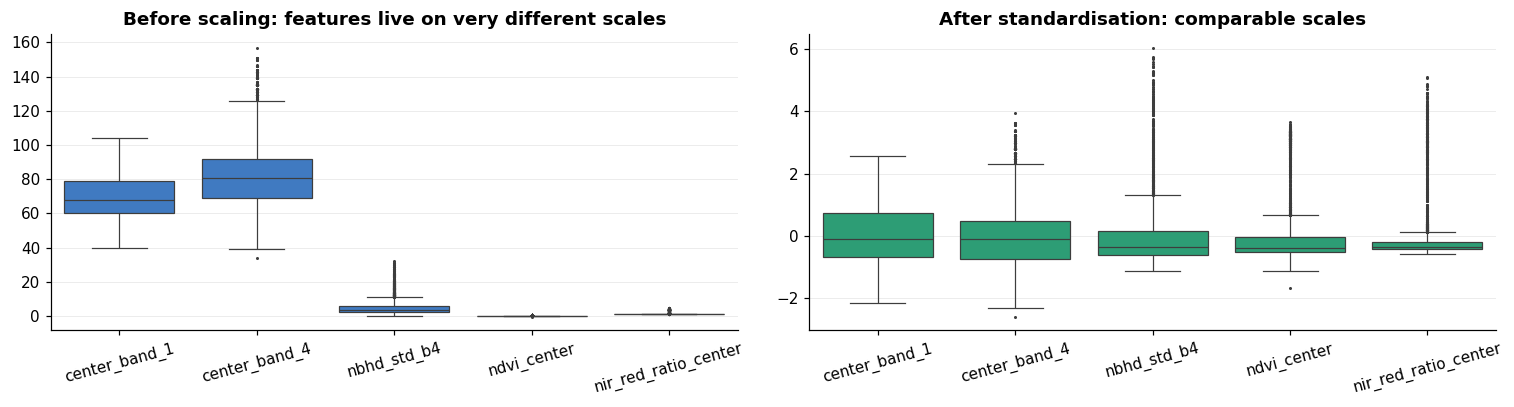

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
raw = FS_TRAIN["engineered"][["center_band_1", "center_band_4", "nbhd_std_b4", "ndvi_center", "nir_red_ratio_center"]]
sns.boxplot(data=raw, ax=axes[0], color="#2a78d6", fliersize=1, linewidth=0.8)
axes[0].set_title("Before scaling: features live on very different scales"); axes[0].tick_params(axis="x", rotation=15)
sns.boxplot(data=pd.DataFrame(StandardScaler().fit_transform(raw), columns=raw.columns), ax=axes[1], color="#1baf7a", fliersize=1, linewidth=0.8)
axes[1].set_title("After standardisation: comparable scales"); axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

### 7.4 Validation Protocol

Because the authors forbid cross-validation, we use a **single stratified 80 / 20 hold-out split of the training file** for every tuning decision:

- `train-part` (80% of `sat.trn`): fit candidate models.
- `validation` (20% of `sat.trn`): compare hyperparameters and pick the best.
- After tuning, the chosen configuration is **re-fitted on the full training file** and evaluated **once** on `sat.tst`.

The model that we finally call the "champion" is also chosen by **validation** score, never by test score, so the reported test score is an unbiased estimate.

In [18]:
idx_tr, idx_val = train_test_split(np.arange(len(df_train)), test_size=0.2, stratify=y_train, random_state=SEED)
y_tr, y_val = y_train[idx_tr], y_train[idx_val]
FS_TR = {k: v.iloc[idx_tr] for k, v in FS_TRAIN.items()}
FS_VAL = {k: v.iloc[idx_val] for k, v in FS_TRAIN.items()}
print(f"train-part: {len(idx_tr)} rows | validation: {len(idx_val)} rows | test: {len(y_test)} rows")

train-part: 3548 rows | validation: 887 rows | test: 2000 rows


### 7.5 Evaluation Toolkit

Helper functions used everywhere below:

- `tune(...)`: tries every combination in a hyperparameter grid on `train-part` and scores it on `validation`.
- `fit_eval(...)`: records the validation score of a configuration, re-fits it on the full training file, evaluates it on the test set and stores everything in a results table.
- `LabelEncodedClassifier`: a small wrapper so that XGBoost (which requires labels 0 to K-1) works with the original class codes.

**Metrics** reported for every model:

| Metric | Formula / meaning | Why it matters here |
|---|---|---|
| Accuracy | share of correct predictions | headline number, comparable with the literature |
| Balanced accuracy | mean of per-class recall | not inflated by the large classes |
| Macro F1 | unweighted mean of per-class F1 | penalises poor performance on small classes |
| Cohen's kappa | agreement beyond chance | standard in remote sensing |
| Log loss | $-\frac{1}{n}\sum_i \log \hat p(y_i \mid \mathbf{x}_i)$ | quality of the predicted *probabilities* |
| Fit / predict time | seconds | practical cost |

In [19]:
class LabelEncodedClassifier(ClassifierMixin, BaseEstimator):
    # Wraps a classifier that needs labels 0..K-1 (e.g. XGBoost) so it accepts the original class codes.
    def __init__(self, estimator=None):
        self.estimator = estimator
    def fit(self, X, y):
        self.le_ = LabelEncoder().fit(y)
        self.classes_ = self.le_.classes_
        self.est_ = clone(self.estimator).fit(X, self.le_.transform(y))
        return self
    def predict(self, X):
        return self.le_.inverse_transform(np.asarray(self.est_.predict(X)).astype(int).ravel())
    def predict_proba(self, X):
        return self.est_.predict_proba(X)


def tune(make_model, grid, fs="full", verbose=True, top=5):
    rows, combos = [], list(ParameterGrid(grid))
    for i, params in enumerate(combos):
        m = make_model(**params).fit(FS_TR[fs], y_tr)
        rows.append({**params, "train_acc": accuracy_score(y_tr, m.predict(FS_TR[fs])),
                     "val_acc": accuracy_score(y_val, m.predict(FS_VAL[fs])), "_i": i})
    res = pd.DataFrame(rows).sort_values("val_acc", ascending=False, kind="stable").reset_index(drop=True)
    best = combos[int(res.loc[0, "_i"])]          # exact original values (keeps None / int types intact)
    res = res.drop(columns="_i")
    if verbose:
        display(res.head(top).style.format({"train_acc": "{:.4f}", "val_acc": "{:.4f}"}).set_caption("Top configurations on validation"))
        print("Best parameters:", best)
    return best, res


RESULTS, MODELS, PREDS, PROBAS = [], {}, {}, {}

def fit_eval(name, model, fs="full", family="", verbose=True):
    # validation score (fit on train-part)
    val_model = clone(model).fit(FS_TR[fs], y_tr)
    val_acc = accuracy_score(y_val, val_model.predict(FS_VAL[fs]))
    # final fit on the full training file, single evaluation on the test file
    t0 = time.perf_counter(); model.fit(FS_TRAIN[fs], y_train); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = model.predict(FS_TEST[fs]); pred_s = time.perf_counter() - t0
    proba = model.predict_proba(FS_TEST[fs]) if hasattr(model, "predict_proba") else None
    row = {"model": name, "family": family, "features": fs,
           "val_acc": val_acc,
           "train_acc": accuracy_score(y_train, model.predict(FS_TRAIN[fs])),
           "test_acc": accuracy_score(y_test, pred),
           "balanced_acc": balanced_accuracy_score(y_test, pred),
           "macro_f1": f1_score(y_test, pred, average="macro"),
           "kappa": cohen_kappa_score(y_test, pred),
           "log_loss": log_loss(y_test, np.clip(proba, 1e-15, 1), labels=CLASSES) if proba is not None else np.nan,
           "fit_s": fit_s, "predict_s": pred_s}
    RESULTS[:] = [r for r in RESULTS if r["model"] != name] + [row]
    MODELS[name], PREDS[name] = (model, fs), pred
    if proba is not None:
        PROBAS[name] = proba
    if verbose:
        print(f"{name:<45} val acc {val_acc:.4f} | TEST acc {row['test_acc']:.4f} | "
              f"bal acc {row['balanced_acc']:.4f} | macro F1 {row['macro_f1']:.4f} | kappa {row['kappa']:.4f}")
    return model, pred


def plot_cm(y_true, y_pred, title, ax=None, normalize=True):
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    show = cm / cm.sum(axis=1, keepdims=True) if normalize else cm
    if ax is None:
        _, ax = plt.subplots(figsize=(6.2, 5))
    sns.heatmap(show, annot=True, fmt=".2f" if normalize else "d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=[CLASS_NAMES[c] for c in CLASSES], yticklabels=[CLASS_NAMES[c] for c in CLASSES],
                vmin=0, vmax=1 if normalize else None, annot_kws={"size": 9})
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    ax.tick_params(axis="x", rotation=35); ax.tick_params(axis="y", rotation=0)
    return ax


def results_table():
    return pd.DataFrame(RESULTS).sort_values("test_acc", ascending=False).reset_index(drop=True)

## 8. Good and Bad Classifiers

### 8.1 What Makes a Classifier "Good"?

A classifier is not good just because it has a high number on one metric. We judge it on:

1. **Better than trivial.** It must clearly beat baselines that ignore the input.
2. **Generalisation.** Small gap between training and unseen-data performance (no overfitting), while training performance is itself high (no underfitting).
3. **Balanced performance.** Good recall on *every* class, not only the large ones.
4. **Trustworthy probabilities.** When it says 90% confident, it should be right about 90% of the time (calibration, Section 16.5).
5. **Practicality.** Training and prediction cost, interpretability.

### 8.2 "Bad" Classifiers: Baselines That Ignore the Input

Dummy classifiers set the floor. Any real model must beat them by a wide margin.

- **Most frequent:** always predicts the majority class.
- **Stratified:** guesses randomly according to the class proportions.
- **Uniform:** guesses each class with equal probability.

In [20]:
for strategy in ["most_frequent", "stratified", "uniform"]:
    fit_eval(f"Dummy ({strategy})", DummyClassifier(strategy=strategy, random_state=SEED), "full", "Baseline")

Dummy (most_frequent)                         val acc 0.2413 | TEST acc 0.2305 | bal acc 0.1667 | macro F1 0.0624 | kappa 0.0000
Dummy (stratified)                            val acc 0.1939 | TEST acc 0.1735 | bal acc 0.1519 | macro F1 0.1516 | kappa -0.0174
Dummy (uniform)                               val acc 0.1590 | TEST acc 0.1630 | bal acc 0.1615 | macro F1 0.1574 | kappa -0.0051


**Interpretation.** Always predicting the majority class gives about 23% accuracy but a balanced accuracy of only 1/6 (about 16.7%), and its kappa is exactly 0: it has learnt nothing. This illustrates why accuracy alone can be misleading and why we also report balanced accuracy, macro F1 and kappa.

### 8.3 Underfitting and Overfitting: the Bias-Variance Trade-off

A model can also be bad by being **too simple** (high bias, underfitting: poor on training *and* validation) or **too flexible** (high variance, overfitting: near-perfect on training, worse on validation). We show both regimes using two complexity knobs: the depth of a decision tree and the number of neighbours $k$ in KNN (small $k$ = flexible).

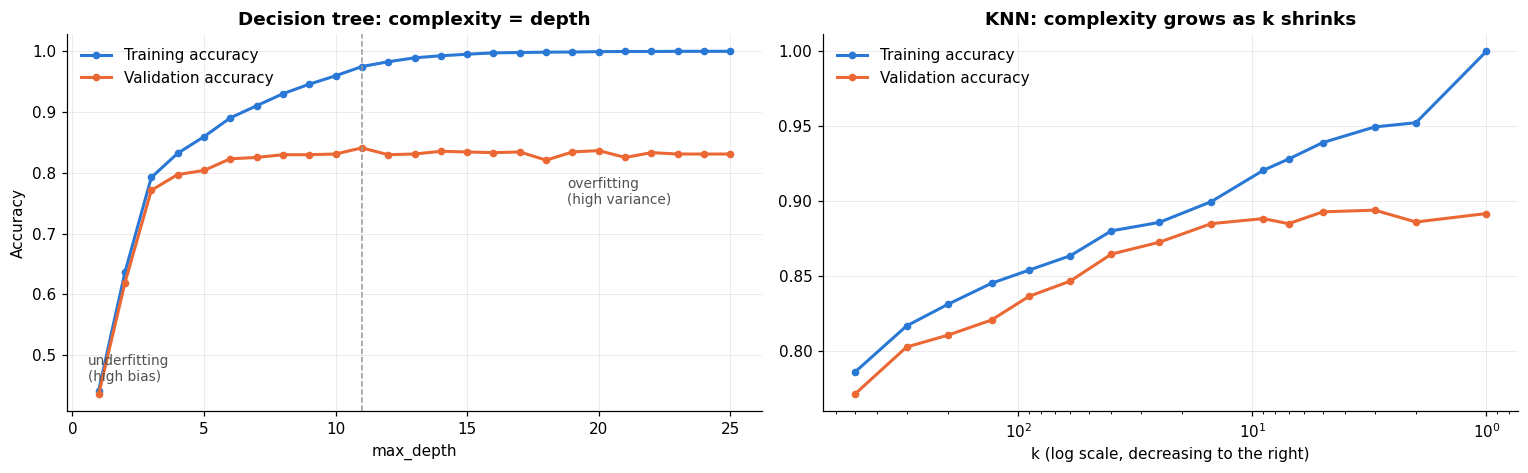

Best tree depth on validation: 11 (val acc 0.8410)
1-NN training accuracy = 1.0000  (it memorises the training set)


In [21]:
depths = list(range(1, 26))
_, dt_curve = tune(lambda max_depth: DecisionTreeClassifier(max_depth=max_depth, random_state=SEED),
                   {"max_depth": depths}, verbose=False)
dt_curve = dt_curve.sort_values("max_depth")
ks = [1, 2, 3, 5, 7, 9, 15, 25, 40, 60, 90, 130, 200, 300, 500]
_, knn_curve = tune(lambda n_neighbors: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=n_neighbors)),
                    {"n_neighbors": ks}, verbose=False)
knn_curve = knn_curve.sort_values("n_neighbors")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
axes[0].plot(dt_curve.max_depth, dt_curve.train_acc, marker="o", ms=4, lw=2, color="#2a78d6", label="Training accuracy")
axes[0].plot(dt_curve.max_depth, dt_curve.val_acc, marker="o", ms=4, lw=2, color="#eb6834", label="Validation accuracy")
best_d = dt_curve.loc[dt_curve.val_acc.idxmax()]
axes[0].axvline(best_d.max_depth, color="#9a9a96", ls="--", lw=1)
axes[0].text(0.03, 0.08, "underfitting\n(high bias)", transform=axes[0].transAxes, fontsize=9, color="#52514e")
axes[0].text(0.72, 0.55, "overfitting\n(high variance)", transform=axes[0].transAxes, fontsize=9, color="#52514e")
axes[0].set_title("Decision tree: complexity = depth"); axes[0].set_xlabel("max_depth"); axes[0].set_ylabel("Accuracy"); axes[0].legend()

axes[1].plot(knn_curve.n_neighbors, knn_curve.train_acc, marker="o", ms=4, lw=2, color="#2a78d6", label="Training accuracy")
axes[1].plot(knn_curve.n_neighbors, knn_curve.val_acc, marker="o", ms=4, lw=2, color="#eb6834", label="Validation accuracy")
axes[1].set_xscale("log"); axes[1].invert_xaxis()
axes[1].set_title("KNN: complexity grows as k shrinks"); axes[1].set_xlabel("k (log scale, decreasing to the right)"); axes[1].legend()
plt.tight_layout(); plt.savefig("fig_bias_variance.png", bbox_inches="tight"); plt.show()

print(f"Best tree depth on validation: {int(best_d.max_depth)} (val acc {best_d.val_acc:.4f})")
print(f"1-NN training accuracy = {knn_curve.loc[knn_curve.n_neighbors == 1, 'train_acc'].item():.4f}  (it memorises the training set)")

**Interpretation.** Both curves show the textbook U-shape of the bias-variance trade-off. A depth-1 tree ("decision stump") and KNN with hundreds of neighbours are *underfit*: both training and validation accuracy are low. A fully grown tree and 1-NN reach 100% training accuracy because they memorise the data, yet their validation accuracy is lower than at moderate complexity. **The training score alone cannot tell a good classifier from a bad one**, which is why every decision in this notebook is made on held-out data.

## 9. Decision Boundaries

A **decision boundary** is the surface in feature space where the classifier's prediction switches from one class to another. Its *shape* reveals the model's inductive bias:

| Model | Boundary shape |
|---|---|
| Logistic regression, LDA, linear SVM | straight lines (hyperplanes) |
| QDA, Gaussian Naive Bayes | quadratic curves (ellipses, parabolas) |
| KNN | irregular, follows the data; very jagged for small $k$ |
| Decision tree | axis-aligned rectangles (staircase) |
| Random forest, boosting | many small axis-aligned regions averaged together |
| RBF-kernel SVM | smooth arbitrary curves |

We cannot draw boundaries in 36 dimensions, so we project the standardised data onto its **first two principal components** and train every model on those two numbers. The accuracies in this section therefore refer to the 2D problem only and are lower than the full models later; the purpose is to *visualise* behaviour.

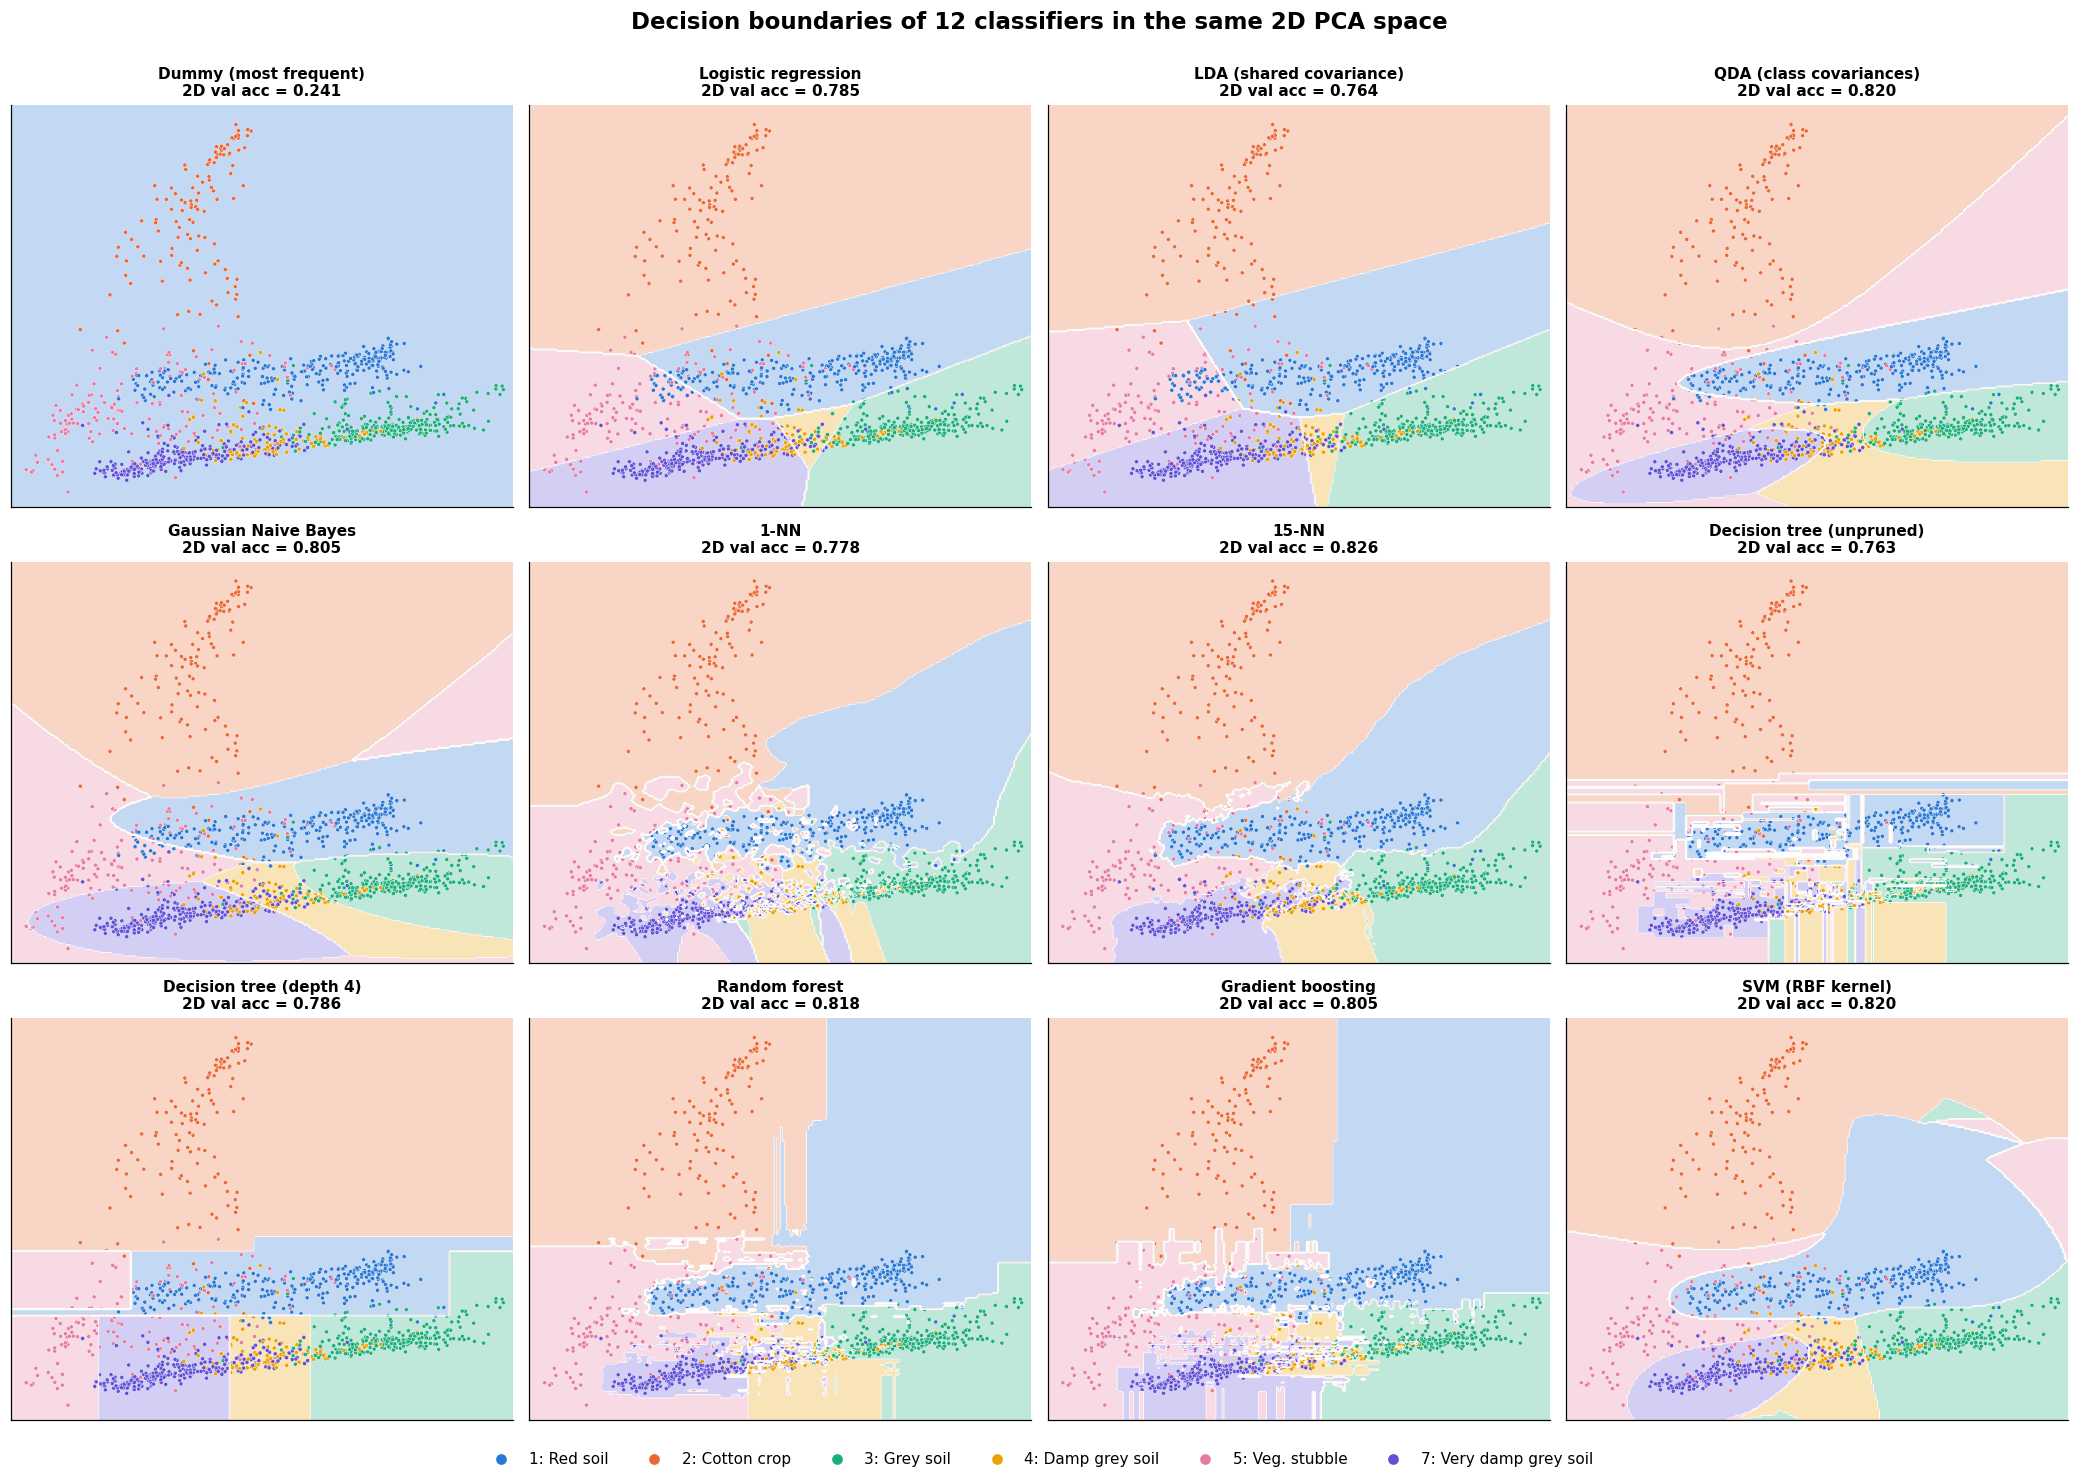

In [22]:
pca2 = make_pipeline(StandardScaler(), PCA(n_components=2)).fit(FS_TR["full"])
X2_tr, X2_val = pca2.transform(FS_TR["full"]), pca2.transform(FS_VAL["full"])

def plot_boundary(model, X2, y, ax, title, h=250, n_points=1200):
    x0, x1 = np.percentile(X2[:, 0], [0.5, 99.5]); y0, y1 = np.percentile(X2[:, 1], [0.5, 99.5])
    pad_x, pad_y = (x1 - x0) * 0.08, (y1 - y0) * 0.08
    xx, yy = np.meshgrid(np.linspace(x0 - pad_x, x1 + pad_x, h), np.linspace(y0 - pad_y, y1 + pad_y, h))
    Z = np.searchsorted(CLASSES, model.predict(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.arange(len(CLASSES) + 1) - 0.5, cmap=CLASS_CMAP, alpha=0.28)
    ax.contour(xx, yy, Z, levels=np.arange(len(CLASSES)) + 0.5, colors="white", linewidths=0.6)
    rng = np.random.RandomState(SEED); sel = rng.choice(len(X2), min(n_points, len(X2)), replace=False)
    ax.scatter(X2[sel, 0], X2[sel, 1], c=np.searchsorted(CLASSES, y[sel]), cmap=CLASS_CMAP, vmin=-0.5,
               vmax=len(CLASSES) - 0.5, s=7, edgecolor="white", linewidth=0.25)
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlim(x0 - pad_x, x1 + pad_x); ax.set_ylim(y0 - pad_y, y1 + pad_y)

boundary_models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=2000),
    "LDA (shared covariance)": LinearDiscriminantAnalysis(),
    "QDA (class covariances)": QuadraticDiscriminantAnalysis(),
    "Gaussian Naive Bayes": GaussianNB(),
    "1-NN": KNeighborsClassifier(1),
    "15-NN": KNeighborsClassifier(15),
    "Decision tree (unpruned)": DecisionTreeClassifier(random_state=SEED),
    "Decision tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Random forest": RandomForestClassifier(300, random_state=SEED, n_jobs=-1),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=SEED),
    "SVM (RBF kernel)": SVC(C=10, gamma="scale"),
}
fig, axes = plt.subplots(3, 4, figsize=(19, 13.5))
for ax, (name, m) in zip(axes.ravel(), boundary_models.items()):
    m.fit(X2_tr, y_tr)
    plot_boundary(m, X2_tr, y_tr, ax, f"{name}\n2D val acc = {accuracy_score(y_val, m.predict(X2_val)):.3f}")
handles = [plt.Line2D([], [], marker="o", ls="", color=CLASS_COLORS[c], label=CLASS_LABELS[i]) for i, c in enumerate(CLASSES)]
fig.legend(handles=handles, loc="lower center", ncol=6, fontsize=10, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Decision boundaries of 12 classifiers in the same 2D PCA space", fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0, 0.02, 1, 0.98]); plt.savefig("fig_decision_boundaries.png", bbox_inches="tight"); plt.show()

**Interpretation.**

- The **dummy** model paints the whole plane with one colour: a "bad" classifier made visible.
- **Logistic regression and LDA** carve the plane with straight lines, which cannot follow the curved shape of the soil continuum.
- **QDA and Gaussian Naive Bayes** draw curved (quadratic) regions, adapting to the elliptical clusters.
- **1-NN** produces a fragmented, noisy map with small islands around individual training points: overfitting you can *see*. With **15 neighbours** the regions become smooth while still following the data.
- The **unpruned tree** shows many thin axis-aligned slivers (overfitting). The **depth-4 tree** is a coarse staircase (underfitting at the edges).
- **Random forest and gradient boosting** average many trees, which smooths the staircase. The **RBF SVM** draws smooth, flexible curves.

The grey-soil classes overlap even in this 2D view, so every boundary there is a compromise. That overlap sets a floor on the achievable error (the *Bayes error*, Section 11).

## 10. Nearest Neighbour Methods

### 10.1 Theory

The **k-nearest neighbour (KNN)** classifier stores the training set and predicts the majority class among the $k$ training points closest to the query point:

$$\hat y(\mathbf{x}) = \arg\max_{c} \sum_{i \in N_k(\mathbf{x})} w_i \, \mathbb{1}[y_i = c]$$

where $N_k(\mathbf{x})$ is the set of the $k$ nearest neighbours and $w_i = 1$ (uniform) or $w_i = 1 / d(\mathbf{x}, \mathbf{x}_i)$ (distance weighting).

- **KNN as a probability estimate.** The share of neighbours in class $c$ estimates the posterior $P(c \mid \mathbf{x})$, so KNN approximates the Bayes classifier non-parametrically.
- **Cover and Hart (1967):** as $n \to \infty$, the error of 1-NN is at most **twice the Bayes error**.
- **Choice of $k$:** small $k$ means low bias but high variance; large $k$ means the reverse (Section 8.3).
- **Distance metric:** Euclidean ($L_2$), Manhattan ($L_1$) or Chebyshev ($L_\infty$). All require **feature scaling**, otherwise the feature with the largest range dominates.
- **Curse of dimensionality:** in high dimensions all points become nearly equidistant. Here the data is effectively low-dimensional (Section 6.7), so KNN should work well.

### 10.2 Friend's Original Baseline: KNN with k = 5

This is the model from the earlier version of the project (all 36 features, standardised, $k = 5$), re-run here inside the shared evaluation framework.

In [23]:
knn_base, y_pred_knn = fit_eval("KNN k=5 (baseline)", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
                                "full", "Nearest neighbour")
print()
print(classification_report(y_test, y_pred_knn, target_names=[CLASS_NAMES[c] for c in CLASSES], digits=3))

KNN k=5 (baseline)                            val acc 0.8929 | TEST acc 0.9045 | bal acc 0.8886 | macro F1 0.8916 | kappa 0.8826

                     precision    recall  f1-score   support

           Red soil      0.979     0.993     0.986       461
        Cotton crop      0.977     0.969     0.973       224
          Grey soil      0.889     0.932     0.910       397
     Damp grey soil      0.729     0.687     0.707       211
       Veg. stubble      0.920     0.873     0.896       237
Very damp grey soil      0.877     0.877     0.877       470

           accuracy                          0.904      2000
          macro avg      0.895     0.889     0.892      2000
       weighted avg      0.903     0.904     0.904      2000



The baseline reaches about 90.5% test accuracy. Per class, red soil and cotton crop are almost perfect while **damp grey soil** has an F1 of only about 0.71, exactly as the EDA predicted.

### 10.3 Tuning k, the Weighting Scheme, and the Effect of Scaling

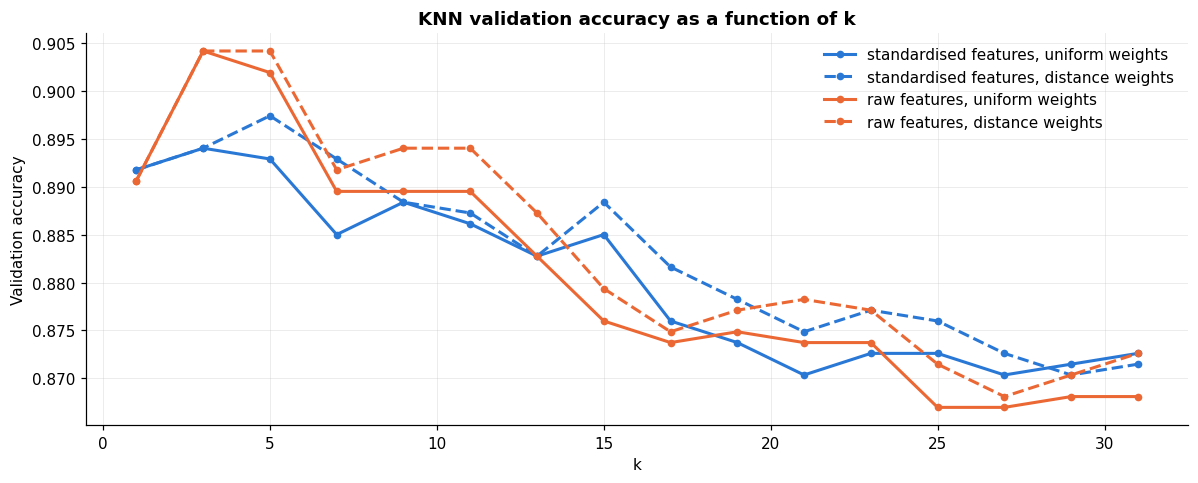

In [24]:
ks = list(range(1, 32, 2))
curves = {}
for scaled in (True, False):
    for weights in ("uniform", "distance"):
        mk = (lambda n_neighbors, w=weights, s=scaled:
              make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=n_neighbors, weights=w)) if s
              else KNeighborsClassifier(n_neighbors=n_neighbors, weights=w))
        _, r = tune(mk, {"n_neighbors": ks}, verbose=False)
        curves[(scaled, weights)] = r.sort_values("n_neighbors")

fig, ax = plt.subplots(figsize=(11, 4.5))
style = {(True, "uniform"): ("#2a78d6", "-"), (True, "distance"): ("#2a78d6", "--"),
         (False, "uniform"): ("#eb6834", "-"), (False, "distance"): ("#eb6834", "--")}
for (scaled, weights), r in curves.items():
    col, ls = style[(scaled, weights)]
    ax.plot(r.n_neighbors, r.val_acc, color=col, ls=ls, marker="o", ms=4, lw=2,
            label=f"{'standardised' if scaled else 'raw'} features, {weights} weights")
ax.set_xlabel("k"); ax.set_ylabel("Validation accuracy"); ax.set_title("KNN validation accuracy as a function of k")
ax.legend(); plt.tight_layout(); plt.show()

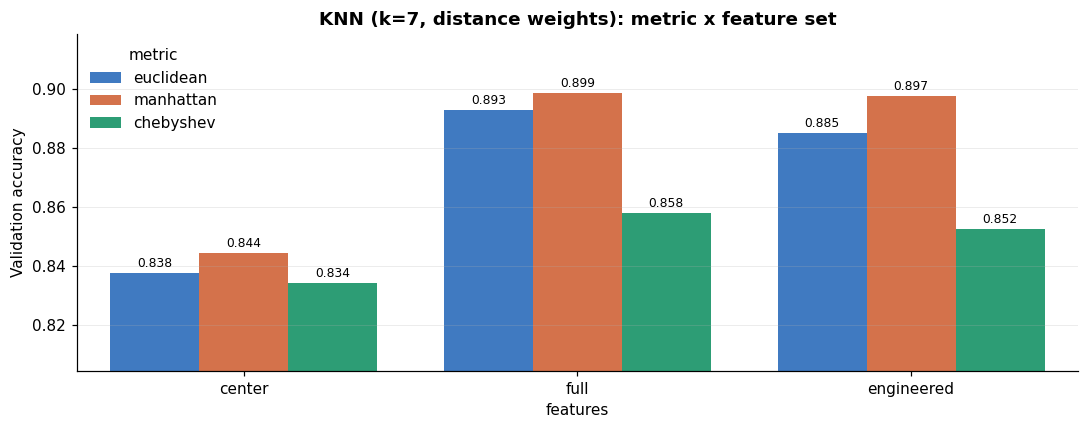

In [25]:
# Distance metric and feature-set comparison at a fixed sensible k
rows = []
for fs in ("center", "full", "engineered"):
    for metric in ("euclidean", "manhattan", "chebyshev"):
        m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, weights="distance", metric=metric)).fit(FS_TR[fs], y_tr)
        rows.append({"features": fs, "metric": metric, "val_acc": accuracy_score(y_val, m.predict(FS_VAL[fs]))})
mf = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=mf, x="features", y="val_acc", hue="metric", palette=["#2a78d6", "#eb6834", "#1baf7a"], ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)
ax.set_ylim(mf.val_acc.min() - 0.03, mf.val_acc.max() + 0.02)
ax.set_title("KNN (k=7, distance weights): metric x feature set"); ax.set_ylabel("Validation accuracy")
plt.tight_layout(); plt.show()

,metric,n_neighbors,weights,train_acc,val_acc
0,manhattan,3,uniform,0.9524,0.9098
1,manhattan,3,distance,1.0000,0.9030
2,manhattan,7,distance,1.0000,0.8985
3,euclidean,5,distance,1.0000,0.8974
4,manhattan,7,uniform,0.9284,0.8952


Best parameters: {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'uniform'}
KNN (tuned)                                   val acc 0.9098 | TEST acc 0.9080 | bal acc 0.8932 | macro F1 0.8963 | kappa 0.8869


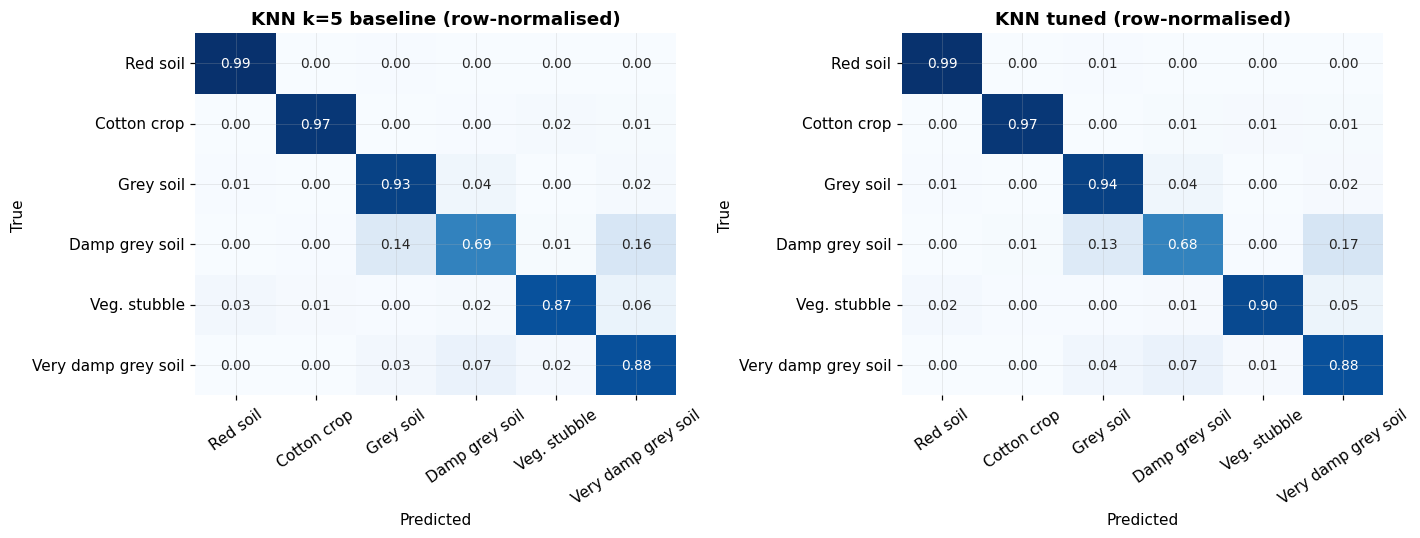

In [26]:
best_knn, knn_grid = tune(lambda n_neighbors, weights, metric: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=n_neighbors, weights=weights, metric=metric)),
                          {"n_neighbors": [3, 5, 7, 9, 11, 15], "weights": ["uniform", "distance"], "metric": ["euclidean", "manhattan"]})
knn_final, y_pred_knn_t = fit_eval("KNN (tuned)", make_pipeline(StandardScaler(), KNeighborsClassifier(**best_knn)), "full", "Nearest neighbour")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_cm(y_test, y_pred_knn, "KNN k=5 baseline (row-normalised)", axes[0])
plot_cm(y_test, y_pred_knn_t, "KNN tuned (row-normalised)", axes[1])
plt.tight_layout(); plt.show()

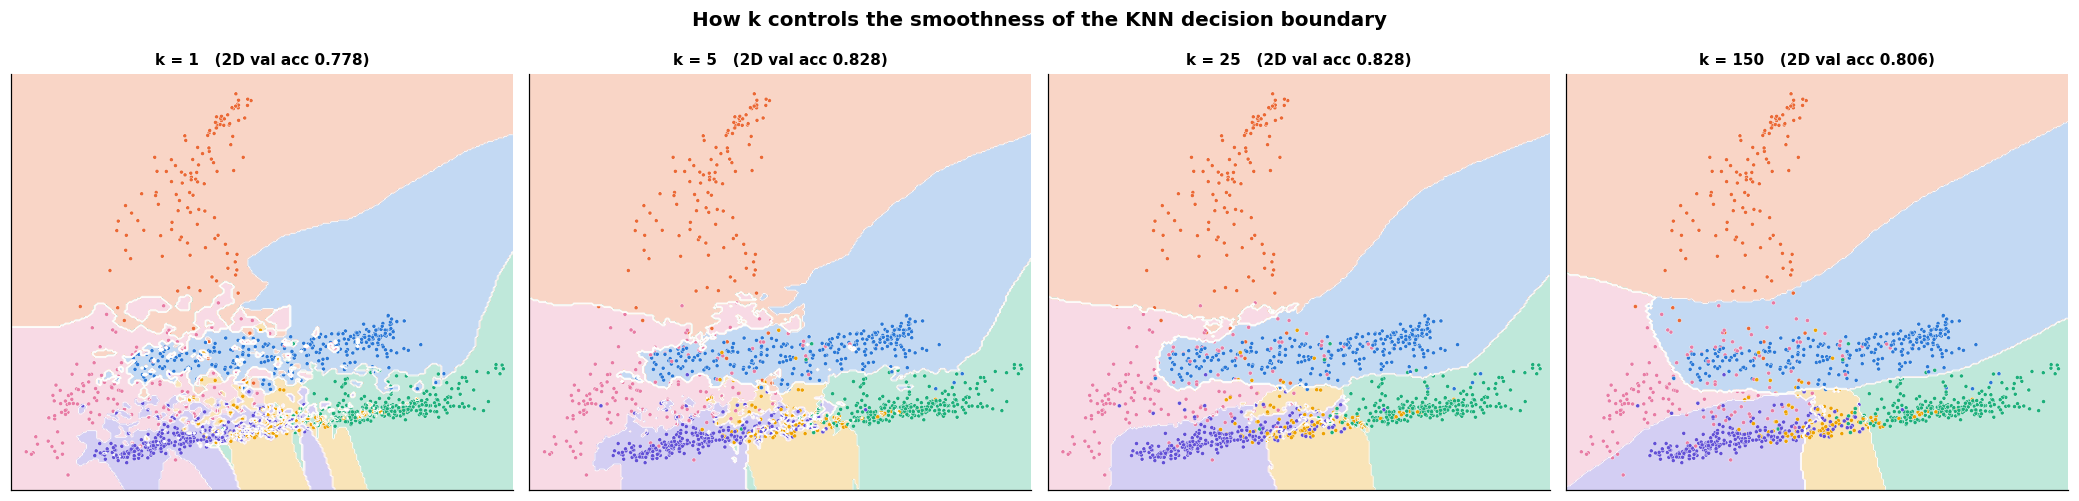

In [27]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
for ax, k in zip(axes, [1, 5, 25, 150]):
    m = KNeighborsClassifier(k).fit(X2_tr, y_tr)
    plot_boundary(m, X2_tr, y_tr, ax, f"k = {k}   (2D val acc {accuracy_score(y_val, m.predict(X2_val)):.3f})")
fig.suptitle("How k controls the smoothness of the KNN decision boundary", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretation.**

- **Scaling matters a little here** because all 36 raw features share the same 0 to 255 unit; it matters far more for the engineered set, whose features have very different ranges.
- **Distance weighting** helps slightly at larger $k$ because closer neighbours are more likely to be inside the same field.
- **Manhattan distance** is often slightly better than Euclidean in higher dimensions because it is less dominated by a single large difference.
- **Neighbourhood information helps KNN substantially**: compare the `center` bars with the `full` bars. This is the first piece of evidence for RQ2.
- The boundary plots show the progression from a fragmented, overfitted map ($k=1$) to an over-smoothed one ($k=150$) where small classes start losing territory.

## 11. Probability and Classification

### 11.1 Bayes' Rule

Probabilistic classifiers model uncertainty explicitly. **Bayes' rule** links the quantity we want, the posterior probability of a class given the observation, to quantities we can estimate from data:

$$\underbrace{P(c \mid \mathbf{x})}_{\text{posterior}} = \frac{\overbrace{p(\mathbf{x} \mid c)}^{\text{class-conditional likelihood}} \; \overbrace{P(c)}^{\text{prior}}}{\underbrace{p(\mathbf{x})}_{\text{evidence}} = \sum_{c'} p(\mathbf{x} \mid c') P(c')}$$

- **Prior** $P(c)$: how common class $c$ is before looking at the pixel (estimated by class frequencies).
- **Likelihood** $p(\mathbf{x} \mid c)$: how typical the observed reflectances are for class $c$.
- **Evidence** $p(\mathbf{x})$: a normalising constant, identical for all classes.

**Generative vs discriminative.** *Generative* classifiers (LDA, QDA, Naive Bayes) model $p(\mathbf{x} \mid c)$ and $P(c)$ and apply Bayes' rule. *Discriminative* classifiers (logistic regression, SVM, trees) model $P(c \mid \mathbf{x})$ or the boundary directly.

### 11.2 Gaussian Class-Conditional Distributions

A common modelling choice is a multivariate Gaussian per class:

$$p(\mathbf{x} \mid c) = \mathcal{N}(\mathbf{x}; \boldsymbol\mu_c, \boldsymbol\Sigma_c) = \frac{1}{(2\pi)^{d/2} |\boldsymbol\Sigma_c|^{1/2}} \exp\!\Big(-\tfrac12 (\mathbf{x}-\boldsymbol\mu_c)^\top \boldsymbol\Sigma_c^{-1} (\mathbf{x}-\boldsymbol\mu_c)\Big)$$

Three special cases give three classic classifiers:

| Covariance assumption | Classifier | Boundary |
|---|---|---|
| Separate full $\boldsymbol\Sigma_c$ per class | **QDA** (Quadratic Discriminant Analysis) | quadratic |
| One shared full $\boldsymbol\Sigma$ | **LDA** (Linear Discriminant Analysis) | linear |
| Diagonal $\boldsymbol\Sigma_c$ (features independent given class) | **Gaussian Naive Bayes** | quadratic, axis-aligned |

First we visualise the idea in one dimension, using the single central-pixel band with the highest ANOVA F-score.

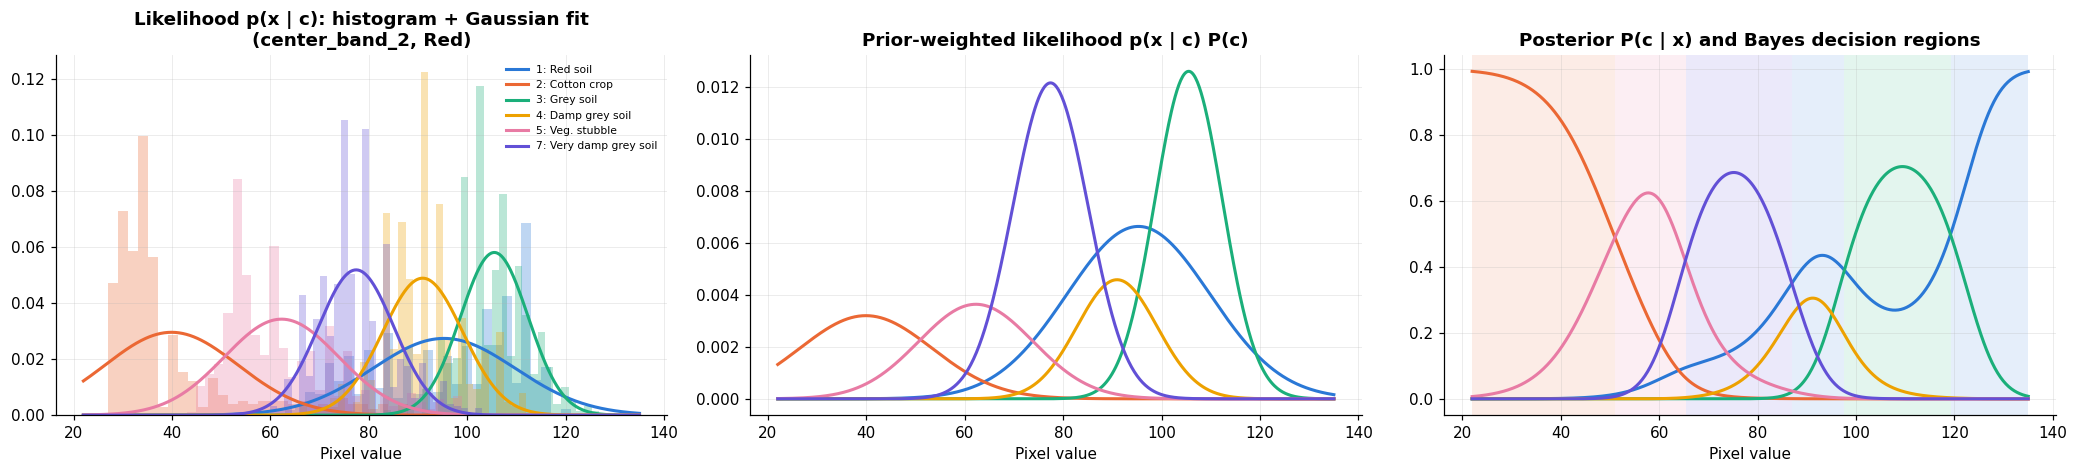

Bayes classifier using ONE Gaussian feature (center_band_2): test accuracy 0.5580


In [28]:
F, _ = f_classif(FS_TRAIN["center"], y_train)
feat = center_features[int(np.argmax(F))]
xv = FS_TRAIN["center"][feat].values
grid1d = np.linspace(xv.min() - 5, xv.max() + 5, 600)
priors = np.array([(y_train == c).mean() for c in CLASSES])
lik = np.array([stats.norm(xv[y_train == c].mean(), xv[y_train == c].std()).pdf(grid1d) for c in CLASSES])
joint = lik * priors[:, None]
post = joint / joint.sum(axis=0)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.4))
for i, c in enumerate(CLASSES):
    axes[0].hist(xv[y_train == c], bins=30, density=True, alpha=0.30, color=CLASS_COLORS[c])
    axes[0].plot(grid1d, lik[i], color=CLASS_COLORS[c], lw=2, label=CLASS_LABELS[i])
    axes[1].plot(grid1d, joint[i], color=CLASS_COLORS[c], lw=2)
    axes[2].plot(grid1d, post[i], color=CLASS_COLORS[c], lw=2)
axes[0].set_title(f"Likelihood p(x | c): histogram + Gaussian fit\n({feat}, {BAND_NAMES[int(feat[-1])]})")
axes[1].set_title("Prior-weighted likelihood p(x | c) P(c)")
axes[2].set_title("Posterior P(c | x) and Bayes decision regions")
decision = np.argmax(post, axis=0)
for i in range(len(grid1d) - 1):
    axes[2].axvspan(grid1d[i], grid1d[i + 1], color=CLASS_COLORS[CLASSES[decision[i]]], alpha=0.12, lw=0)
axes[0].legend(fontsize=7)
for ax in axes: ax.set_xlabel("Pixel value")
plt.tight_layout(); plt.savefig("fig_bayes_1d.png", bbox_inches="tight"); plt.show()

acc_1d = accuracy_score(y_test, CLASSES[np.argmax(np.array([stats.norm(xv[y_train == c].mean(), xv[y_train == c].std()).logpdf(FS_TEST['center'][feat].values) for c in CLASSES]) + np.log(priors)[:, None], axis=0)])
print(f"Bayes classifier using ONE Gaussian feature ({feat}): test accuracy {acc_1d:.4f}")

**Interpretation.** The left panel shows that one band is roughly Gaussian within each class. The middle panel shows the curves after weighting by the priors: wherever one curve is highest, Bayes' rule picks that class. The right panel turns this into **posterior probabilities**, and the shaded background shows the resulting **decision regions**. Classes whose curves overlap (the grey soils) have posteriors well below 1 even at their peak: this is irreducible uncertainty with this single feature. A single band already gets a respectable accuracy; the rest of the section adds dimensions.

### 11.3 A Gaussian Bayes Classifier Implemented from Scratch

To show exactly what LDA, QDA and Gaussian Naive Bayes compute, we implement all three in about 30 lines of NumPy and check that they match scikit-learn. Prediction uses the log of Bayes' rule (the evidence term is dropped because it is the same for every class):

$$\hat y = \arg\max_c \Big[ \log \mathcal{N}(\mathbf{x}; \hat{\boldsymbol\mu}_c, \hat{\boldsymbol\Sigma}_c) + \log \hat P(c) \Big]$$

In [29]:
class GaussianBayesClassifier(ClassifierMixin, BaseEstimator):
    # covariance = "full" (QDA), "shared" (LDA) or "diag" (Gaussian Naive Bayes)
    def __init__(self, covariance="full", priors=None, reg=1e-6):
        self.covariance, self.priors, self.reg = covariance, priors, reg

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y)
        self.classes_ = np.unique(y)
        d, K = X.shape[1], len(self.classes_)
        self.means_ = np.array([X[y == c].mean(axis=0) for c in self.classes_])
        covs = [np.cov(X[y == c], rowvar=False) for c in self.classes_]
        if self.covariance == "shared":
            pooled = sum((np.sum(y == c) - 1) * S for c, S in zip(self.classes_, covs)) / (len(y) - K)
            covs = [pooled] * K
        elif self.covariance == "diag":
            covs = [np.diag(np.diag(S)) for S in covs]
        self.covs_ = [S + self.reg * np.eye(d) for S in covs]
        self.priors_ = (np.array([np.mean(y == c) for c in self.classes_]) if self.priors is None
                        else np.asarray(self.priors, float))
        return self

    def joint_log_likelihood(self, X):
        X = np.asarray(X, float)
        return np.column_stack([multivariate_normal(m, S, allow_singular=True).logpdf(X) + np.log(p)
                                for m, S, p in zip(self.means_, self.covs_, self.priors_)])

    def predict_proba(self, X):
        L = self.joint_log_likelihood(X)
        L -= L.max(axis=1, keepdims=True)          # log-sum-exp trick for numerical stability
        P = np.exp(L)
        return P / P.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[np.argmax(self.joint_log_likelihood(X), axis=1)]


rows = []
for cov, sk in [("full", QuadraticDiscriminantAnalysis()), ("shared", LinearDiscriminantAnalysis()), ("diag", GaussianNB(var_smoothing=1e-12))]:
    ours = GaussianBayesClassifier(covariance=cov).fit(FS_TR["full"], y_tr)
    ref = sk.fit(FS_TR["full"], y_tr)
    p_ours, p_ref = ours.predict(FS_VAL["full"]), ref.predict(FS_VAL["full"])
    rows.append({"covariance": cov, "equivalent sklearn model": type(sk).__name__,
                 "val acc (from scratch)": accuracy_score(y_val, p_ours), "val acc (sklearn)": accuracy_score(y_val, p_ref),
                 "prediction agreement": np.mean(p_ours == p_ref)})
display(pd.DataFrame(rows).style.format({c: "{:.4f}" for c in ["val acc (from scratch)", "val acc (sklearn)", "prediction agreement"]}))

,covariance,equivalent sklearn model,val acc (from scratch),val acc (sklearn),prediction agreement
0,full,QuadraticDiscriminantAnalysis,0.8501,0.8501,1.0000
1,shared,LinearDiscriminantAnalysis,0.8219,0.8219,1.0000
2,diag,GaussianNB,0.7734,0.7745,0.9989


**Interpretation.** The from-scratch implementation agrees with scikit-learn on essentially every validation prediction. This confirms the theory: **LDA, QDA and Gaussian Naive Bayes are all the same Bayes classifier with different assumptions about the class covariance matrices.** QDA (the most flexible) usually wins because the classes really do have different spreads and orientations; Naive Bayes is clearly the weakest because ignoring covariances is a bad assumption on this highly correlated data.

### 11.4 Tuning and Testing the Gaussian Generative Models

QDA estimates $6 \times (36 \times 37 / 2) = 3{,}996$ covariance parameters, so it benefits from **regularisation** (shrinking each class covariance towards the identity, `reg_param`). LDA can use **shrinkage** of the shared covariance.

In [30]:
best_qda, _ = tune(lambda reg_param: make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis(reg_param=reg_param)),
                   {"reg_param": [0.0, 0.001, 0.01, 0.03, 0.1, 0.3, 0.6]})
best_lda, _ = tune(lambda shrinkage: LinearDiscriminantAnalysis(solver="lsqr", shrinkage=shrinkage),
                   {"shrinkage": [None, 0.001, 0.01, 0.05, 0.1, 0.3]}, top=3)
best_gnb, _ = tune(lambda var_smoothing: GaussianNB(var_smoothing=var_smoothing),
                   {"var_smoothing": list(np.logspace(-12, 0, 13))}, top=3)

fit_eval("LDA", LinearDiscriminantAnalysis(solver="lsqr", **best_lda), "full", "Probabilistic")
fit_eval("QDA (regularised)", make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis(**best_qda)), "full", "Probabilistic")
fit_eval("Gaussian Bayes from scratch (full cov)", GaussianBayesClassifier("full", reg=1e-3), "full", "Probabilistic")
fit_eval("Gaussian Naive Bayes", GaussianNB(**best_gnb), "full", "Probabilistic");

,reg_param,train_acc,val_acc
0,0.100000,0.8799,0.8579
1,0.030000,0.8839,0.8557
2,0.300000,0.8763,0.8557
3,0.000000,0.9014,0.8501
4,0.010000,0.8892,0.8501


Best parameters: {'reg_param': 0.1}


,shrinkage,train_acc,val_acc
0,0.050000,0.8532,0.8275
1,0.300000,0.8512,0.8253
2,0.100000,0.8523,0.8241


Best parameters: {'shrinkage': 0.05}


,var_smoothing,train_acc,val_acc
0,0.000000,0.8007,0.7745
1,0.000000,0.8007,0.7745
2,0.000000,0.8007,0.7745


Best parameters: {'var_smoothing': np.float64(1e-12)}
LDA                                           val acc 0.8275 | TEST acc 0.8255 | bal acc 0.7728 | macro F1 0.7803 | kappa 0.7836
QDA (regularised)                             val acc 0.8579 | TEST acc 0.8530 | bal acc 0.8037 | macro F1 0.8013 | kappa 0.8175
Gaussian Bayes from scratch (full cov)        val acc 0.8501 | TEST acc 0.8480 | bal acc 0.8010 | macro F1 0.7879 | kappa 0.8116
Gaussian Naive Bayes                          val acc 0.7745 | TEST acc 0.7965 | bal acc 0.7877 | macro F1 0.7833 | kappa 0.7518


### 11.5 Bayes Optimal Decisions

The **Bayes optimal decision rule** chooses the action that minimises the **expected loss (conditional risk)** given the observation. With a loss matrix $L(c, a)$ = the cost of predicting $a$ when the truth is $c$:

$$R(a \mid \mathbf{x}) = \sum_{c} L(c, a)\, P(c \mid \mathbf{x}), \qquad a^*(\mathbf{x}) = \arg\min_a R(a \mid \mathbf{x})$$

- With **0-1 loss** (every mistake costs 1), $R(a \mid \mathbf{x}) = 1 - P(a \mid \mathbf{x})$, so the optimal rule is simply **pick the class with the highest posterior (MAP rule)**. Its error rate, the **Bayes error**, is the lowest error *any* classifier can achieve; no amount of modelling can beat it.
- When mistakes have **different costs**, the optimal decision shifts away from the MAP class.

**Scenario.** Suppose the map is used to plan irrigation and drainage, and missing **damp grey soil** (class 4) is $\lambda$ times more costly than any other error. We keep the probabilistic model fixed (regularised QDA) and change only the *decision rule*.

,lambda,accuracy,recall class 4,precision class 4,total cost
0,1.000000,0.8530,0.223,0.681,294
1,1.500000,0.8600,0.313,0.673,352
2,2.000000,0.8610,0.398,0.622,405
3,3.000000,0.8645,0.517,0.596,475
4,4.000000,0.8640,0.583,0.572,536
5,6.000000,0.8660,0.687,0.549,598
6,8.000000,0.8655,0.758,0.539,626
7,12.000000,0.8520,0.796,0.491,769


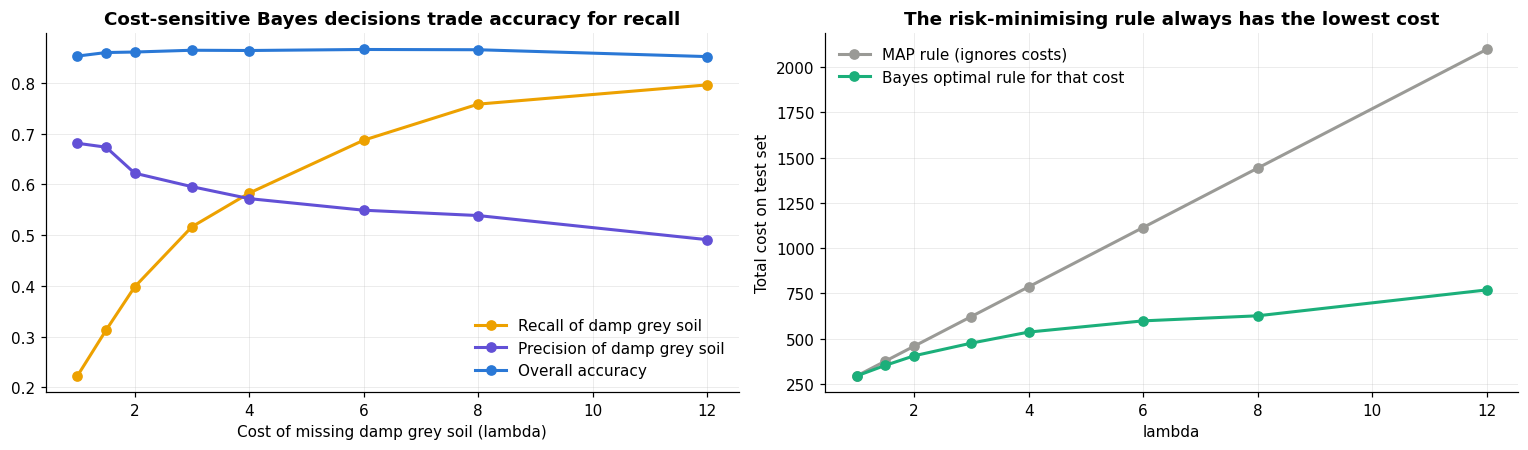

In [31]:
qda_model, _ = MODELS["QDA (regularised)"]
P_test = qda_model.predict_proba(FS_TEST["full"])
i4 = list(CLASSES).index(4)

def bayes_decision(P, lam):
    L = np.ones((len(CLASSES), len(CLASSES))); np.fill_diagonal(L, 0)
    L[i4, :] = lam; L[i4, i4] = 0                  # missing class 4 costs lam
    risk = P @ L                                   # risk[n, a] = sum_c P(c|x_n) L(c, a)
    return CLASSES[risk.argmin(axis=1)], L

rows = []
for lam in [1, 1.5, 2, 3, 4, 6, 8, 12]:
    pred, L = bayes_decision(P_test, lam)
    cm = confusion_matrix(y_test, pred, labels=CLASSES)
    rows.append({"lambda": lam, "accuracy": accuracy_score(y_test, pred),
                 "recall class 4": cm[i4, i4] / cm[i4].sum(), "precision class 4": cm[i4, i4] / max(cm[:, i4].sum(), 1),
                 "total cost": (cm * L).sum()})
cs = pd.DataFrame(rows)
display(cs.style.format({"accuracy": "{:.4f}", "recall class 4": "{:.3f}", "precision class 4": "{:.3f}", "total cost": "{:.0f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(cs["lambda"], cs["recall class 4"], marker="o", lw=2, color="#eda100", label="Recall of damp grey soil")
axes[0].plot(cs["lambda"], cs["precision class 4"], marker="o", lw=2, color="#6250d6", label="Precision of damp grey soil")
axes[0].plot(cs["lambda"], cs["accuracy"], marker="o", lw=2, color="#2a78d6", label="Overall accuracy")
axes[0].set_xlabel("Cost of missing damp grey soil (lambda)"); axes[0].set_title("Cost-sensitive Bayes decisions trade accuracy for recall"); axes[0].legend()

zero_one_cost = [(confusion_matrix(y_test, bayes_decision(P_test, 1)[0], labels=CLASSES) * bayes_decision(P_test, lam)[1]).sum() for lam in cs["lambda"]]
axes[1].plot(cs["lambda"], zero_one_cost, marker="o", lw=2, color="#9a9a96", label="MAP rule (ignores costs)")
axes[1].plot(cs["lambda"], cs["total cost"], marker="o", lw=2, color="#1baf7a", label="Bayes optimal rule for that cost")
axes[1].set_xlabel("lambda"); axes[1].set_ylabel("Total cost on test set"); axes[1].set_title("The risk-minimising rule always has the lowest cost"); axes[1].legend()
plt.tight_layout(); plt.savefig("fig_bayes_cost.png", bbox_inches="tight"); plt.show()

**Interpretation.** At $\lambda = 1$ the rule is the ordinary MAP rule. As the penalty for missing damp grey soil grows, the decision rule becomes more willing to predict class 4 for ambiguous pixels: **recall of class 4 rises** from 0.22 to about 0.69 at $\lambda = 6$ while precision falls from 0.68 to 0.55. Overall accuracy barely moves (it even rises slightly, from 85.3% to 86.6%, because QDA under-predicts class 4 to begin with), and the **total cost is always lower** than if we kept using the MAP rule (about 600 versus 1,110 at $\lambda = 6$). This is the practical value of probabilistic classifiers: the same fitted model supports *different decisions for different costs*, without retraining. A classifier that only outputs labels (for example a plain decision tree vote or a perceptron) cannot be adapted like this.

**Effect of the prior.** The prior $P(c)$ is also a decision lever. Replacing the empirical priors with uniform ones shifts predictions towards small classes, which raises balanced accuracy (here it raises accuracy too, because the empirical priors made QDA neglect damp grey soil):

In [32]:
rows = []
for prior_name, pri in [("empirical (class frequencies)", None), ("uniform (1/6 each)", np.ones(len(CLASSES)) / len(CLASSES))]:
    m = make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis(priors=pri, **best_qda)).fit(FS_TRAIN["full"], y_train)
    p = m.predict(FS_TEST["full"])
    rows.append({"prior": prior_name, "accuracy": accuracy_score(y_test, p), "balanced accuracy": balanced_accuracy_score(y_test, p),
                 "recall damp grey soil": confusion_matrix(y_test, p, labels=CLASSES)[i4, i4] / np.sum(y_test == 4)})
display(pd.DataFrame(rows).style.format({c: "{:.4f}" for c in ["accuracy", "balanced accuracy", "recall damp grey soil"]}))

,prior,accuracy,balanced accuracy,recall damp grey soil
0,empirical (class frequencies),0.8530,0.8037,0.2227
1,uniform (1/6 each),0.8670,0.8368,0.4550


### 11.6 The Naive Bayes Model

**Naive Bayes** assumes the features are **conditionally independent given the class**, so the likelihood factorises into one-dimensional pieces:

$$p(\mathbf{x} \mid c) = \prod_{j=1}^{d} p(x_j \mid c) \quad\Rightarrow\quad \hat y = \arg\max_c \Big[\log P(c) + \sum_{j=1}^{d} \log \mathcal{N}(x_j; \mu_{cj}, \sigma^2_{cj})\Big]$$

**Advantages:** only $2 \times d \times K$ parameters, extremely fast, works with little data, and is often surprisingly accurate *in ranking* even when its probabilities are wrong.
**Weakness:** when features are correlated, the same evidence is counted many times. Here each band is measured nine times (once per pixel) and neighbours are correlated above 0.9, so Naive Bayes effectively multiplies the same likelihood ratio about nine times. That makes its posteriors **overconfident** and can also hurt accuracy.

We test this explanation with three experiments:

1. Naive Bayes on the `center` set (4 features, less redundancy) versus the `full` set (36 highly redundant features).
2. Naive Bayes after **PCA whitening**, which rotates the data so the features are *uncorrelated* overall, making the independence assumption much more reasonable.
3. Comparing the **confidence** of Naive Bayes and QDA.

Gaussian Naive Bayes [center]                 val acc 0.7745 | TEST acc 0.7910 | bal acc 0.7743 | macro F1 0.7751 | kappa 0.7440
Gaussian Naive Bayes + PCA whitening          val acc 0.8207 | TEST acc 0.8200 | bal acc 0.7743 | macro F1 0.7669 | kappa 0.7776

Mean |correlation| between features WITHIN the red soil class: 0.747 (independence would mean 0)


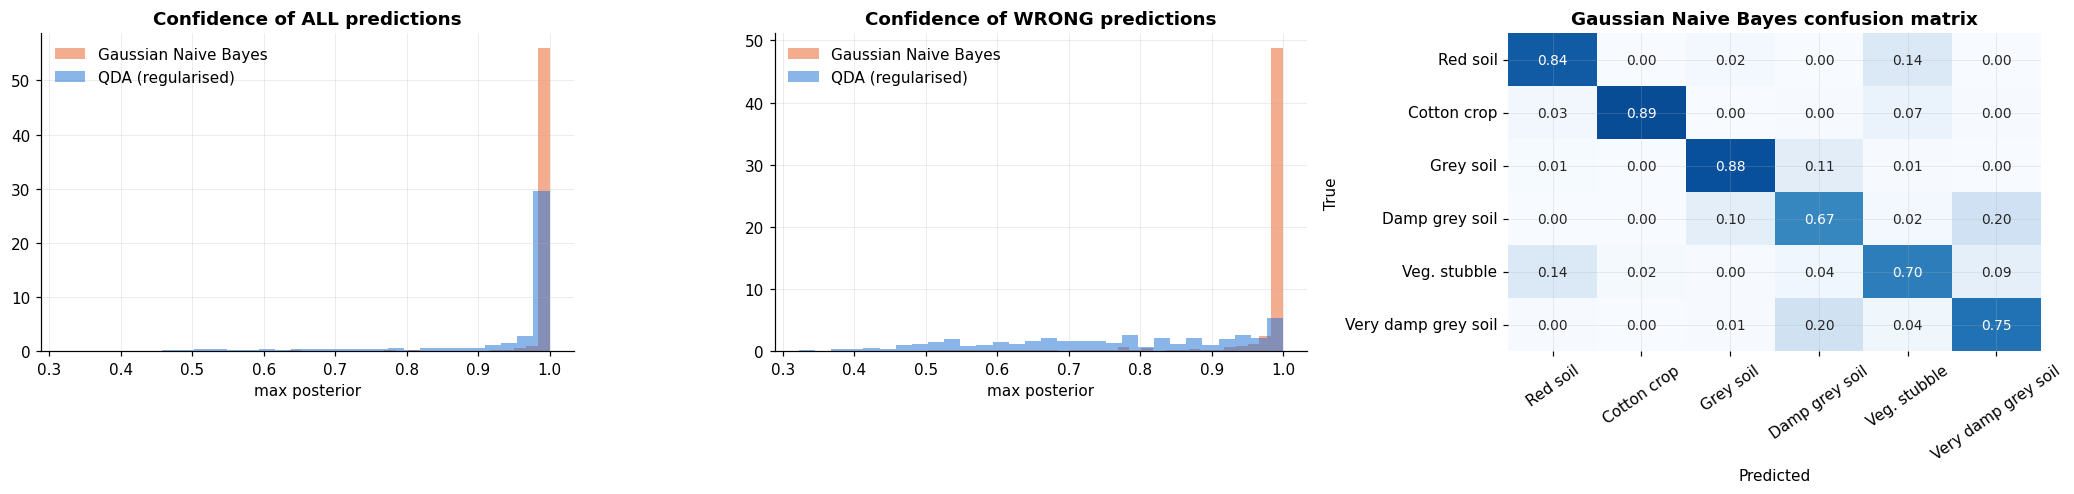

Naive Bayes: 86.7% of its WRONG predictions are made with > 95% confidence
QDA        : 17.7% of its WRONG predictions are made with > 95% confidence


In [33]:
fit_eval("Gaussian Naive Bayes [center]", GaussianNB(), "center", "Probabilistic")
fit_eval("Gaussian Naive Bayes + PCA whitening", make_pipeline(StandardScaler(), PCA(whiten=True, random_state=SEED), GaussianNB()), "full", "Probabilistic")

within = df_train.loc[df_train[TARGET] == 1, feature_names].corr().abs()
print(f"\nMean |correlation| between features WITHIN the red soil class: "
      f"{within.where(np.triu(np.ones(within.shape), 1).astype(bool)).stack().mean():.3f} (independence would mean 0)")

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
for name, col in [("Gaussian Naive Bayes", "#eb6834"), ("QDA (regularised)", "#2a78d6")]:
    conf = PROBAS[name].max(axis=1)
    correct = PREDS[name] == y_test
    axes[0].hist(conf, bins=30, alpha=0.55, color=col, label=name, density=True)
    axes[1].hist(conf[~correct], bins=30, alpha=0.55, color=col, label=name, density=True)
axes[0].set_title("Confidence of ALL predictions"); axes[0].set_xlabel("max posterior"); axes[0].legend()
axes[1].set_title("Confidence of WRONG predictions"); axes[1].set_xlabel("max posterior"); axes[1].legend()
plot_cm(y_test, PREDS["Gaussian Naive Bayes"], "Gaussian Naive Bayes confusion matrix", axes[2])
plt.tight_layout(); plt.savefig("fig_naive_bayes.png", bbox_inches="tight"); plt.show()

wrong_nb = PREDS["Gaussian Naive Bayes"] != y_test
print(f"Naive Bayes: {np.mean(PROBAS['Gaussian Naive Bayes'][wrong_nb].max(axis=1) > 0.95):.1%} of its WRONG predictions are made with > 95% confidence")
wrong_q = PREDS["QDA (regularised)"] != y_test
print(f"QDA        : {np.mean(PROBAS['QDA (regularised)'][wrong_q].max(axis=1) > 0.95):.1%} of its WRONG predictions are made with > 95% confidence")

**Interpretation.** Within a single class, the features are still strongly correlated, so the independence assumption is clearly false. The consequences are visible:

- Naive Bayes is pushed towards **extreme posteriors**: a large share of its *wrong* predictions are made with more than 95% confidence, far more than QDA. Its probabilities are badly calibrated.
- **PCA whitening** removes the overall correlation, and Naive Bayes on whitened features typically improves noticeably, confirming that the correlation (not the Gaussian shape) was the problem.
- Naive Bayes is the weakest probabilistic model on this data. This mirrors the original Statlog study, where Naive Bayes was among the worst performers on this dataset.

### 11.7 Summary of Probabilistic Models

In [34]:
prob_tbl = results_table().query("family == 'Probabilistic'")[["model", "features", "val_acc", "test_acc", "balanced_acc", "macro_f1", "log_loss"]]
display(prob_tbl.style.format({c: "{:.4f}" for c in ["val_acc", "test_acc", "balanced_acc", "macro_f1", "log_loss"]})
        .background_gradient(cmap="Blues", subset=["test_acc"]))

,model,features,val_acc,test_acc,balanced_acc,macro_f1,log_loss
2,QDA (regularised),full,0.8579,0.8530,0.8037,0.8013,0.4900
3,Gaussian Bayes from scratch (full cov),full,0.8501,0.8480,0.8010,0.7879,0.8440
4,LDA,full,0.8275,0.8255,0.7728,0.7803,0.5647
5,Gaussian Naive Bayes + PCA whitening,full,0.8207,0.8200,0.7743,0.7669,0.8173
6,Gaussian Naive Bayes,full,0.7745,0.7965,0.7877,0.7833,3.9110
7,Gaussian Naive Bayes [center],center,0.7745,0.7910,0.7743,0.7751,0.9263


## 12. Linear Classifiers

A linear classifier scores each class with a linear function and picks the highest:

$$g_c(\mathbf{x}) = \mathbf{w}_c^\top \mathbf{x} + b_c, \qquad \hat y = \arg\max_c g_c(\mathbf{x})$$

The boundary between two classes, $g_a(\mathbf{x}) = g_b(\mathbf{x})$, is a **hyperplane**. Different linear classifiers differ only in *how they choose* $\mathbf{w}$ and $b$:

| Model | Learning criterion | Probabilities? |
|---|---|---|
| **Perceptron** | update weights only on mistakes; converges only if data is linearly separable | no |
| **Logistic regression** (softmax) | maximise likelihood of $P(c \mid \mathbf{x}) = \frac{e^{g_c(\mathbf{x})}}{\sum_{c'} e^{g_{c'}(\mathbf{x})}}$, with L2 penalty $\frac{1}{2C}\lVert \mathbf{w} \rVert^2$ | yes |
| **Linear SVM** | maximise the margin (hinge loss) | no |
| **Ridge classifier** | least squares regression on one-hot targets | no |
| **LDA** | Gaussian classes with shared covariance (generative, Section 11) | yes |

Multiclass problems are handled by one-vs-rest (one hyperplane per class against all others) or directly with the softmax.

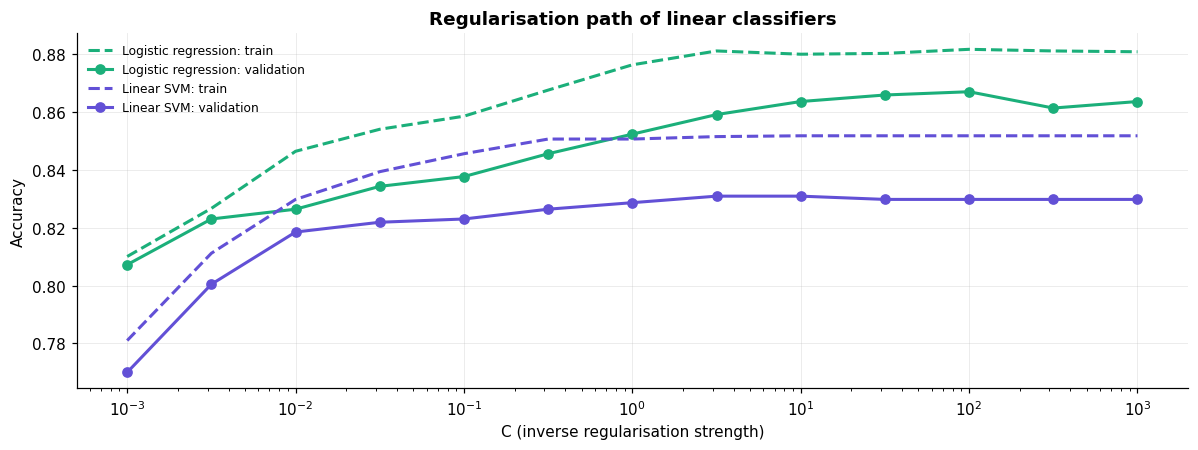

Best: {'LogReg C': {'C': np.float64(100.0)}, 'LinearSVC C': {'C': np.float64(3.1622776601683795)}, 'Ridge alpha': {'alpha': np.float64(0.001)}, 'Perceptron': {'alpha': 1e-05, 'penalty': None}}
Perceptron                                    val acc 0.8388 | TEST acc 0.8140 | bal acc 0.7489 | macro F1 0.7408 | kappa 0.7683
Ridge classifier                              val acc 0.7610 | TEST acc 0.7450 | bal acc 0.6462 | macro F1 0.5923 | kappa 0.6781
Linear SVM                                    val acc 0.8309 | TEST acc 0.8180 | bal acc 0.7506 | macro F1 0.7375 | kappa 0.7729
Logistic regression                           val acc 0.8670 | TEST acc 0.8375 | bal acc 0.7962 | macro F1 0.7981 | kappa 0.7992


In [35]:
Cs = list(np.logspace(-3, 3, 13))
best_lr, lr_curve = tune(lambda C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000)), {"C": Cs}, verbose=False)
best_svm_lin, svm_curve = tune(lambda C: make_pipeline(StandardScaler(), LinearSVC(C=C, max_iter=20000)), {"C": Cs}, verbose=False)
best_ridge, ridge_curve = tune(lambda alpha: make_pipeline(StandardScaler(), RidgeClassifier(alpha=alpha)), {"alpha": list(np.logspace(-3, 3, 13))}, verbose=False)
best_perc, _ = tune(lambda alpha, penalty: make_pipeline(StandardScaler(), Perceptron(alpha=alpha, penalty=penalty, max_iter=2000, random_state=SEED)),
                    {"alpha": [1e-5, 1e-4, 1e-3], "penalty": [None, "l2", "l1"]}, verbose=False)

fig, ax = plt.subplots(figsize=(11, 4.2))
lr_curve, svm_curve = lr_curve.sort_values("C"), svm_curve.sort_values("C")
ax.plot(lr_curve.C, lr_curve.train_acc, color="#1baf7a", ls="--", lw=2, label="Logistic regression: train")
ax.plot(lr_curve.C, lr_curve.val_acc, color="#1baf7a", marker="o", lw=2, label="Logistic regression: validation")
ax.plot(svm_curve.C, svm_curve.train_acc, color="#6250d6", ls="--", lw=2, label="Linear SVM: train")
ax.plot(svm_curve.C, svm_curve.val_acc, color="#6250d6", marker="o", lw=2, label="Linear SVM: validation")
ax.set_xscale("log"); ax.set_xlabel("C (inverse regularisation strength)"); ax.set_ylabel("Accuracy")
ax.set_title("Regularisation path of linear classifiers"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Best:", {"LogReg C": best_lr, "LinearSVC C": best_svm_lin, "Ridge alpha": best_ridge, "Perceptron": best_perc})

fit_eval("Perceptron", make_pipeline(StandardScaler(), Perceptron(max_iter=2000, random_state=SEED, **best_perc)), "full", "Linear")
fit_eval("Ridge classifier", make_pipeline(StandardScaler(), RidgeClassifier(**best_ridge)), "full", "Linear")
fit_eval("Linear SVM", make_pipeline(StandardScaler(), LinearSVC(max_iter=20000, **best_svm_lin)), "full", "Linear")
fit_eval("Logistic regression", make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, **best_lr)), "full", "Linear");

### 12.1 What Did Logistic Regression Learn?

Because inputs are standardised, coefficient magnitudes are comparable. We plot the coefficient of every feature for every class.

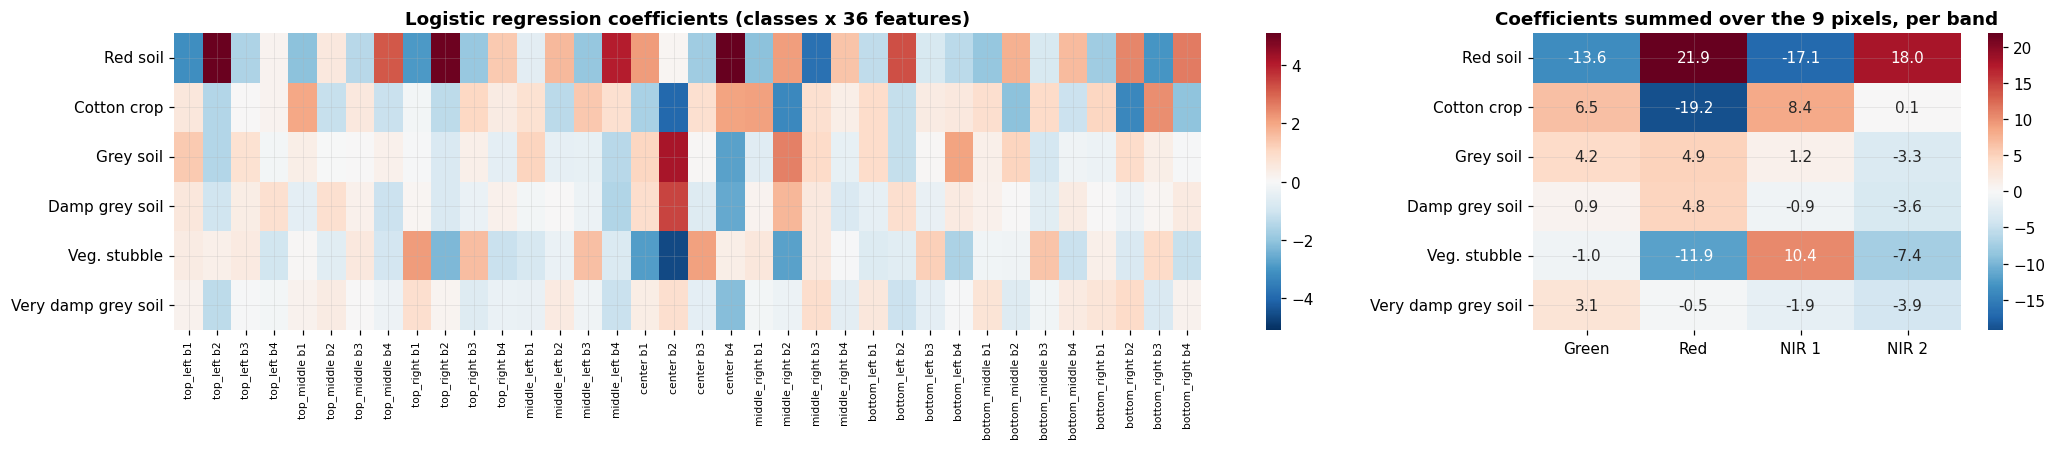

In [36]:
lr_model = MODELS["Logistic regression"][0][-1]
coef = pd.DataFrame(lr_model.coef_, index=[CLASS_NAMES[c] for c in lr_model.classes_], columns=feature_names)
fig, axes = plt.subplots(1, 2, figsize=(19, 4.2), gridspec_kw={"width_ratios": [2.4, 1]})
lim = np.abs(coef.values).max()
sns.heatmap(coef, cmap="RdBu_r", center=0, vmin=-lim, vmax=lim, ax=axes[0], xticklabels=[f.replace("_band_", " b") for f in feature_names])
axes[0].tick_params(axis="x", rotation=90, labelsize=7); axes[0].set_title("Logistic regression coefficients (classes x 36 features)")
band_coef = pd.DataFrame({BAND_NAMES[b]: coef[[f for f in feature_names if f.endswith(f"band_{b}")]].sum(axis=1) for b in range(1, 5)})
sns.heatmap(band_coef, cmap="RdBu_r", center=0, annot=True, fmt=".1f", ax=axes[1])
axes[1].set_title("Coefficients summed over the 9 pixels, per band")
plt.tight_layout(); plt.show()

**Interpretation.** Cotton crop receives large positive weights on NIR and negative weights on Red, which is the NDVI logic learnt automatically. The individual 36 coefficients look noisy, with positive and negative values for neighbouring pixels of the same band: this is the instability caused by **collinearity**. The band-level sums are much easier to interpret.

### 12.2 Making a Linear Classifier Non-linear: Basis Expansion

A linear model in a *transformed* feature space is non-linear in the original space. Adding all degree-2 products of the features (Polynomial features, 702 features in total) gives logistic regression quadratic boundaries, similar in spirit to QDA but trained discriminatively.

In [37]:
best_poly, _ = tune(lambda C: make_pipeline(StandardScaler(), PolynomialFeatures(2), StandardScaler(), LogisticRegression(C=C, max_iter=3000)),
                    {"C": [0.01, 0.1, 1.0]}, top=3)
fit_eval("Logistic regression + degree-2 features", make_pipeline(StandardScaler(), PolynomialFeatures(2), StandardScaler(), LogisticRegression(max_iter=3000, **best_poly)),
         "full", "Linear")

lin_tbl = results_table().query("family == 'Linear'")[["model", "val_acc", "train_acc", "test_acc", "balanced_acc", "macro_f1"]]
display(lin_tbl.style.format({c: "{:.4f}" for c in lin_tbl.columns[1:]}).background_gradient(cmap="Blues", subset=["test_acc"]))

,C,train_acc,val_acc
0,0.100000,0.9298,0.8828
1,1.000000,0.9577,0.8794
2,0.010000,0.8999,0.8771


Best parameters: {'C': 0.1}
Logistic regression + degree-2 features       val acc 0.8828 | TEST acc 0.8860 | bal acc 0.8641 | macro F1 0.8692 | kappa 0.8596


,model,val_acc,train_acc,test_acc,balanced_acc,macro_f1
2,Logistic regression + degree-2 features,0.8828,0.9299,0.8860,0.8641,0.8692
5,Logistic regression,0.8670,0.8796,0.8375,0.7962,0.7981
8,Linear SVM,0.8309,0.8453,0.8180,0.7506,0.7375
9,Perceptron,0.8388,0.8352,0.8140,0.7489,0.7408
12,Ridge classifier,0.7610,0.7682,0.7450,0.6462,0.5923


**Interpretation.** The ridge classifier is the weakest linear model (74.5%): least squares on one-hot targets is a poor surrogate for classification and it almost ignores damp grey soil. The perceptron (81.4%) never converges because the classes are not linearly separable, and it stops at an arbitrary hyperplane. Logistic regression (83.8%), linear SVM (81.8%) and LDA (82.6%) cluster together, which shows that **the hypothesis space (linear boundaries) matters much more than the exact loss function**. Adding quadratic features raises logistic regression to the level of QDA, confirming that the remaining errors of linear models were caused by the boundary shape rather than lack of data.

## 13. Decision Trees

### 13.1 Theory

A decision tree recursively splits the feature space with questions of the form *"is feature $j$ at most threshold $t$?"*. At every node it chooses the split that most reduces **impurity**:

$$\text{Gini}(S) = 1 - \sum_c p_c^2, \qquad \text{Entropy}(S) = -\sum_c p_c \log_2 p_c$$

$$\text{Gain} = I(S) - \frac{|S_L|}{|S|} I(S_L) - \frac{|S_R|}{|S|} I(S_R)$$

Trees are **interpretable**, need **no scaling**, and capture **interactions** automatically, but a fully grown tree memorises noise (high variance). Complexity is controlled by pre-pruning (`max_depth`, `min_samples_leaf`) or by **cost-complexity post-pruning**, which minimises

$$R_\alpha(T) = R(T) + \alpha \, |\text{leaves}(T)|$$

### 13.2 Friend's Original Baseline: Unpruned Decision Tree

In [38]:
dt_base, y_pred_dt = fit_eval("Decision tree (unpruned baseline)", DecisionTreeClassifier(random_state=SEED), "full", "Decision tree")
print(f"Leaves: {dt_base.get_n_leaves()}, depth: {dt_base.get_depth()}")
print(classification_report(y_test, y_pred_dt, target_names=[CLASS_NAMES[c] for c in CLASSES], digits=3))

Decision tree (unpruned baseline)             val acc 0.8309 | TEST acc 0.8490 | bal acc 0.8293 | macro F1 0.8304 | kappa 0.8146
Leaves: 382, depth: 21
                     precision    recall  f1-score   support

           Red soil      0.957     0.963     0.960       461
        Cotton crop      0.973     0.969     0.971       224
          Grey soil      0.865     0.854     0.859       397
     Damp grey soil      0.529     0.555     0.542       211
       Veg. stubble      0.841     0.806     0.823       237
Very damp grey soil      0.825     0.830     0.827       470

           accuracy                          0.849      2000
          macro avg      0.832     0.829     0.830      2000
       weighted avg      0.851     0.849     0.850      2000



### 13.3 Pre-pruning: Depth, Leaf Size and Split Criterion

,criterion,max_depth,min_samples_leaf,train_acc,val_acc
0,entropy,12.000000,2,0.9746,0.8467
1,entropy,15.000000,2,0.9789,0.8455
2,gini,12.000000,2,0.9670,0.8410
3,entropy,15.000000,1,0.9972,0.8410
4,gini,8.000000,5,0.9112,0.8388


Best parameters: {'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 2}


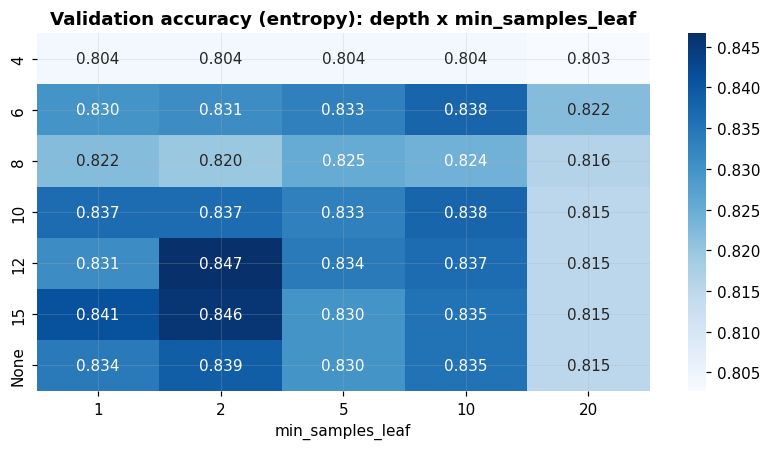

In [39]:
best_dt, dt_grid = tune(lambda criterion, max_depth, min_samples_leaf: DecisionTreeClassifier(criterion=criterion, max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=SEED),
                        {"criterion": ["gini", "entropy"], "max_depth": [4, 6, 8, 10, 12, 15, None], "min_samples_leaf": [1, 2, 5, 10, 20]})
pivot = dt_grid[dt_grid.criterion == best_dt["criterion"]].pivot_table(index="max_depth", columns="min_samples_leaf", values="val_acc", dropna=False)
pivot.index = [str(int(i)) if pd.notna(i) else "None" for i in pivot.index]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="Blues", ax=ax)
ax.set_title(f"Validation accuracy ({best_dt['criterion']}): depth x min_samples_leaf")
plt.tight_layout(); plt.show()

### 13.4 Post-pruning: Minimal Cost-Complexity Pruning

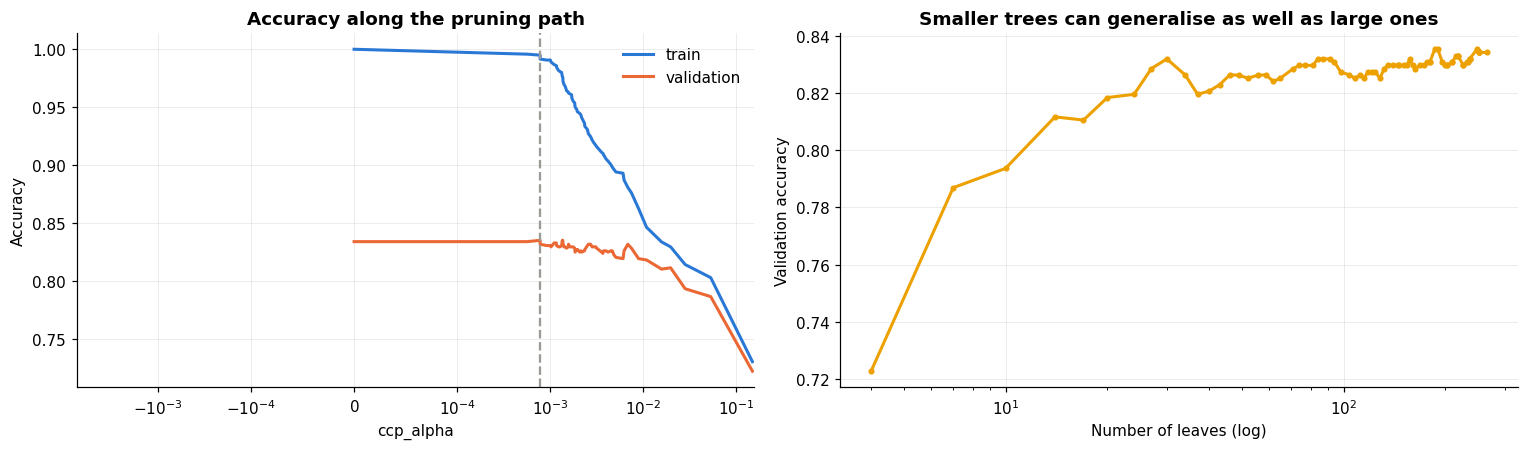

Best ccp_alpha = 0.00078 -> 248 leaves, val acc 0.8354


In [40]:
path = DecisionTreeClassifier(random_state=SEED, criterion=best_dt["criterion"]).cost_complexity_pruning_path(FS_TR["full"], y_tr)
alphas = path.ccp_alphas[:-1][::max(1, len(path.ccp_alphas) // 60)]
rows = []
for a in alphas:
    t = DecisionTreeClassifier(random_state=SEED, criterion=best_dt["criterion"], ccp_alpha=a).fit(FS_TR["full"], y_tr)
    rows.append({"alpha": a, "leaves": t.get_n_leaves(), "train_acc": t.score(FS_TR["full"], y_tr), "val_acc": t.score(FS_VAL["full"], y_val)})
pr = pd.DataFrame(rows)
best_alpha = pr.loc[pr.val_acc.idxmax(), "alpha"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(pr.alpha, pr.train_acc, lw=2, color="#2a78d6", label="train"); axes[0].plot(pr.alpha, pr.val_acc, lw=2, color="#eb6834", label="validation")
axes[0].axvline(best_alpha, color="#9a9a96", ls="--"); axes[0].set_xscale("symlog", linthresh=1e-4)
axes[0].set_xlabel("ccp_alpha"); axes[0].set_ylabel("Accuracy"); axes[0].set_title("Accuracy along the pruning path"); axes[0].legend()
axes[1].plot(pr.leaves, pr.val_acc, lw=2, marker="o", ms=3, color="#eda100")
axes[1].set_xscale("log"); axes[1].set_xlabel("Number of leaves (log)"); axes[1].set_ylabel("Validation accuracy"); axes[1].set_title("Smaller trees can generalise as well as large ones")
plt.tight_layout(); plt.show()
print(f"Best ccp_alpha = {best_alpha:.5f} -> {int(pr.loc[pr.val_acc.idxmax(), 'leaves'])} leaves, val acc {pr.val_acc.max():.4f}")

In [41]:
fit_eval("Decision tree (pre-pruned, tuned)", DecisionTreeClassifier(random_state=SEED, **best_dt), "full", "Decision tree")
dt_pruned, _ = fit_eval("Decision tree (cost-complexity pruned)", DecisionTreeClassifier(random_state=SEED, criterion=best_dt["criterion"], ccp_alpha=best_alpha), "full", "Decision tree")
print(f"Pruned tree leaves: {dt_pruned.get_n_leaves()} (unpruned had {dt_base.get_n_leaves()})")

Decision tree (pre-pruned, tuned)             val acc 0.8467 | TEST acc 0.8440 | bal acc 0.8240 | macro F1 0.8237 | kappa 0.8085
Decision tree (cost-complexity pruned)        val acc 0.8354 | TEST acc 0.8405 | bal acc 0.8197 | macro F1 0.8211 | kappa 0.8041
Pruned tree leaves: 285 (unpruned had 382)


### 13.5 Reading the Tree

A shallow (depth 3) tree is shown for interpretability. The colour of each node shows its majority class and purity.

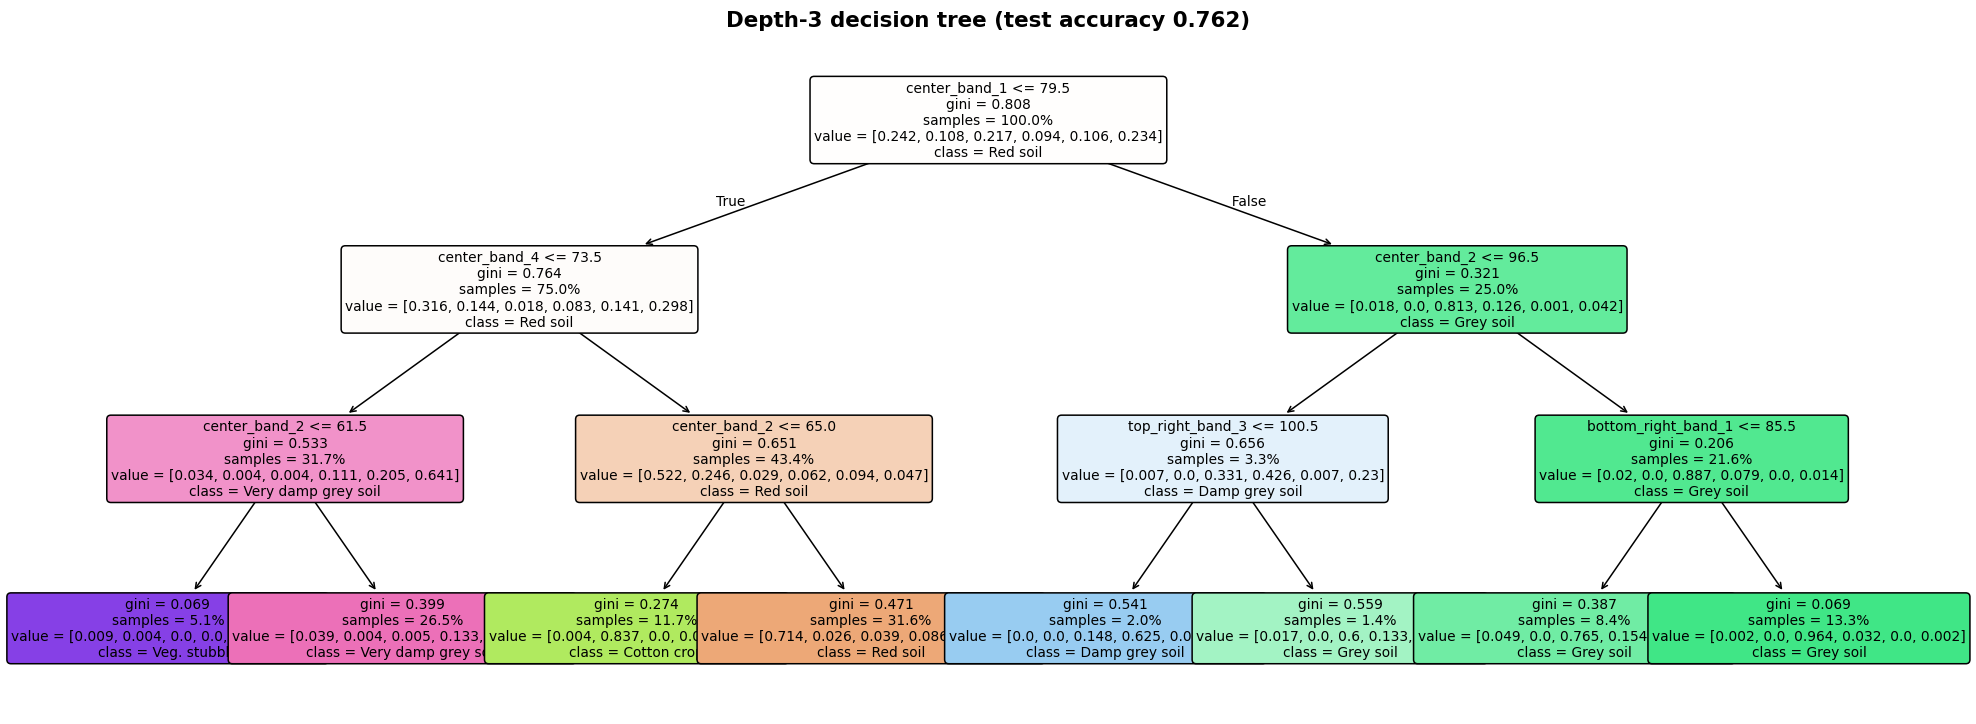

|--- center_band_1 <= 79.50
|   |--- center_band_4 <= 73.50
|   |   |--- center_band_2 <= 61.50
|   |   |   |--- class: 5
|   |   |--- center_band_2 >  61.50
|   |   |   |--- class: 7
|   |--- center_band_4 >  73.50
|   |   |--- center_band_2 <= 65.00
|   |   |   |--- class: 2
|   |   |--- center_band_2 >  65.00
|   |   |   |--- class: 1
|--- center_band_1 >  79.50
|   |--- center_band_2 <= 96.50
|   |   |--- top_right_band_3 <= 100.50
|   |   |   |--- class: 4
|   |   |--- top_right_band_3 >  100.50
|   |   |   |--- class: 3
|   |--- center_band_2 >  96.50
|   |   |--- bottom_right_band_1 <= 85.50
|   |   |   |--- class: 3
|   |   |--- bottom_right_band_1 >  85.50
|   |   |   |--- class: 3



In [42]:
small = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(FS_TRAIN["full"], y_train)
fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(small, feature_names=feature_names, class_names=[CLASS_NAMES[c] for c in small.classes_], filled=True, rounded=True,
          impurity=True, proportion=True, fontsize=9, ax=ax)
ax.set_title(f"Depth-3 decision tree (test accuracy {small.score(FS_TEST['full'], y_test):.3f})", fontsize=14, fontweight="bold")
plt.show()
print(export_text(small, feature_names=feature_names))

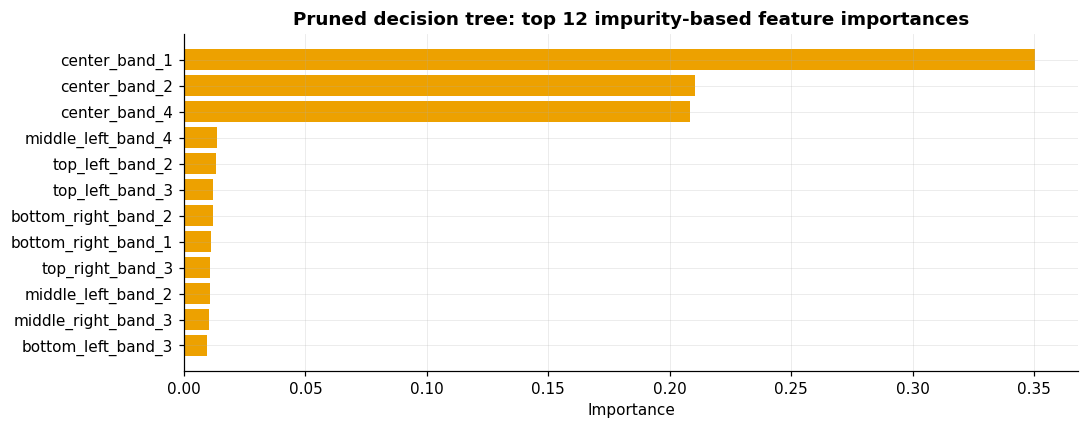

In [43]:
imp = pd.Series(dt_pruned.feature_importances_, index=feature_names).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(imp.index[::-1], imp.values[::-1], color="#eda100")
ax.set_title("Pruned decision tree: top 12 impurity-based feature importances"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

**Interpretation.**

- The root split is on a **NIR band**, which separates the dark wet soils from the bright dry ones. The next levels use Red to pick out cotton crop and red soil, essentially rediscovering the vegetation/soil logic from the EDA.
- The **unpruned tree** has hundreds of leaves and the lowest test accuracy of all trees. Pruning removes most leaves while keeping or improving accuracy: many leaves were memorising noise.
- Single trees remain clearly behind KNN and QDA. Their axis-aligned splits must approximate diagonal class boundaries with staircases, and they are **unstable**: a small change in the data can change the whole tree.

### 13.6 Trees Are High-Variance Learners

To quantify the instability we train 10 unpruned trees, each on a different bootstrap sample (random sample with replacement) of the training data, and check how often they disagree on the test pixels. This motivates the ensembles in the next section.

In [44]:
rng = np.random.RandomState(SEED)
boot_preds = []
for b in range(10):
    idx = rng.choice(len(y_train), len(y_train), replace=True)
    t = DecisionTreeClassifier(random_state=b).fit(FS_TRAIN["full"].iloc[idx], y_train[idx])
    boot_preds.append(t.predict(FS_TEST["full"]))
boot_preds = np.array(boot_preds)
accs = [accuracy_score(y_test, p) for p in boot_preds]
disagree = np.mean([len(set(col)) > 1 for col in boot_preds.T])
vote = np.array([pd.Series(col).mode()[0] for col in boot_preds.T])
print(f"Individual bootstrap-tree test accuracies: min {min(accs):.4f}, mean {np.mean(accs):.4f}, max {max(accs):.4f}")
print(f"Share of test pixels on which at least two trees disagree: {disagree:.1%}")
print(f"Majority vote of the same 10 trees: {accuracy_score(y_test, vote):.4f}   <- already better than any single tree")

Individual bootstrap-tree test accuracies: min 0.8200, mean 0.8308, max 0.8395
Share of test pixels on which at least two trees disagree: 44.5%
Majority vote of the same 10 trees: 0.8870   <- already better than any single tree


## 14. Ensemble Methods

An ensemble combines many models. If $M$ models each have variance $\sigma^2$ and pairwise correlation $\rho$, the variance of their average is

$$\operatorname{Var}\Big(\frac1M \sum_m f_m\Big) = \rho\,\sigma^2 + \frac{1-\rho}{M}\,\sigma^2$$

So averaging reduces variance, and it helps most when the models are **accurate but different** (low $\rho$). There are two main strategies:

| Strategy | Idea | Mainly reduces | Examples |
|---|---|---|---|
| **Bagging** | train models independently on bootstrap samples and average them | variance | Bagging, Random Forest, Extra Trees |
| **Boosting** | train models sequentially, each focusing on the errors of the previous ones | bias (and variance) | AdaBoost, Gradient Boosting, XGBoost, LightGBM |
| **Stacking / voting** | combine *different* model types | both | Voting, Stacking |

### 14.1 Bagging

**Bootstrap aggregating** trains $B$ trees on bootstrap samples and takes a majority vote. Each bootstrap sample leaves out about $1 - (1 - 1/n)^n \approx 36.8\%$ of the rows; these **out-of-bag (OOB)** rows give a free internal accuracy estimate.

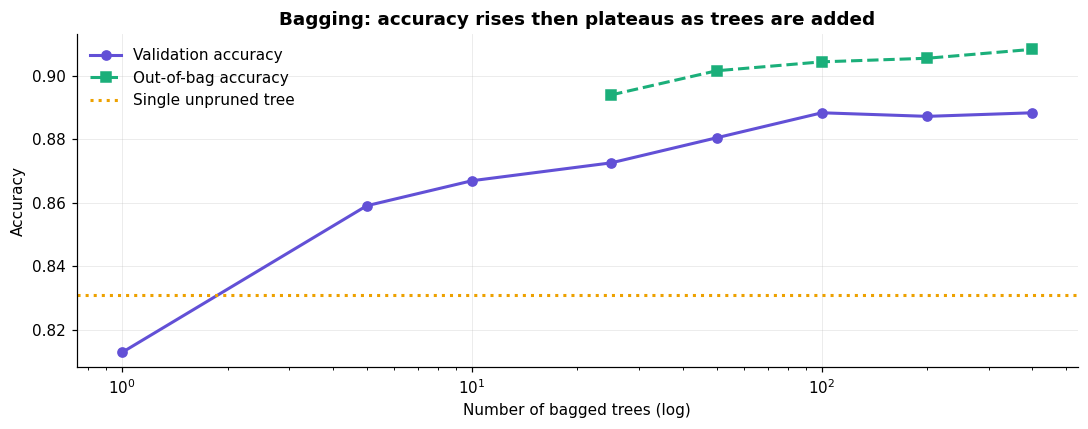

Bagging (200 trees)                           val acc 0.8873 | TEST acc 0.9005 | bal acc 0.8811 | macro F1 0.8854 | kappa 0.8775


In [45]:
n_list = [1, 5, 10, 25, 50, 100, 200, 400]
rows = []
for n in n_list:
    bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=n, oob_score=n >= 25, random_state=SEED, n_jobs=-1).fit(FS_TR["full"], y_tr)
    rows.append({"n_estimators": n, "val_acc": bag.score(FS_VAL["full"], y_val), "oob_acc": bag.oob_score_ if n >= 25 else np.nan})
bag_curve = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(bag_curve.n_estimators, bag_curve.val_acc, marker="o", lw=2, color="#6250d6", label="Validation accuracy")
ax.plot(bag_curve.n_estimators, bag_curve.oob_acc, marker="s", lw=2, color="#1baf7a", ls="--", label="Out-of-bag accuracy")
ax.axhline(accuracy_score(y_val, DecisionTreeClassifier(random_state=SEED).fit(FS_TR["full"], y_tr).predict(FS_VAL["full"])), color="#eda100", ls=":", lw=2, label="Single unpruned tree")
ax.set_xscale("log"); ax.set_xlabel("Number of bagged trees (log)"); ax.set_ylabel("Accuracy"); ax.set_title("Bagging: accuracy rises then plateaus as trees are added"); ax.legend()
plt.tight_layout(); plt.show()

fit_eval("Bagging (200 trees)", BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, random_state=SEED, n_jobs=-1), "full", "Ensemble");

### 14.2 Random Forests

A **random forest** is bagging plus one extra trick: at every split, only a random subset of `max_features` features is considered. This **decorrelates** the trees (lowers $\rho$ in the formula above), which is especially useful here because the 36 features are so redundant: without it, every tree would split on the same few NIR features. **Extra Trees** go further by also choosing split thresholds at random.

,max_features,min_samples_leaf,train_acc,val_acc
0,6,1,1.0000,0.8940
1,6,2,0.9935,0.8906
2,9,2,0.9941,0.8895
3,18,1,1.0000,0.8895
4,2,1,1.0000,0.8884


Best parameters: {'max_features': 6, 'min_samples_leaf': 1}


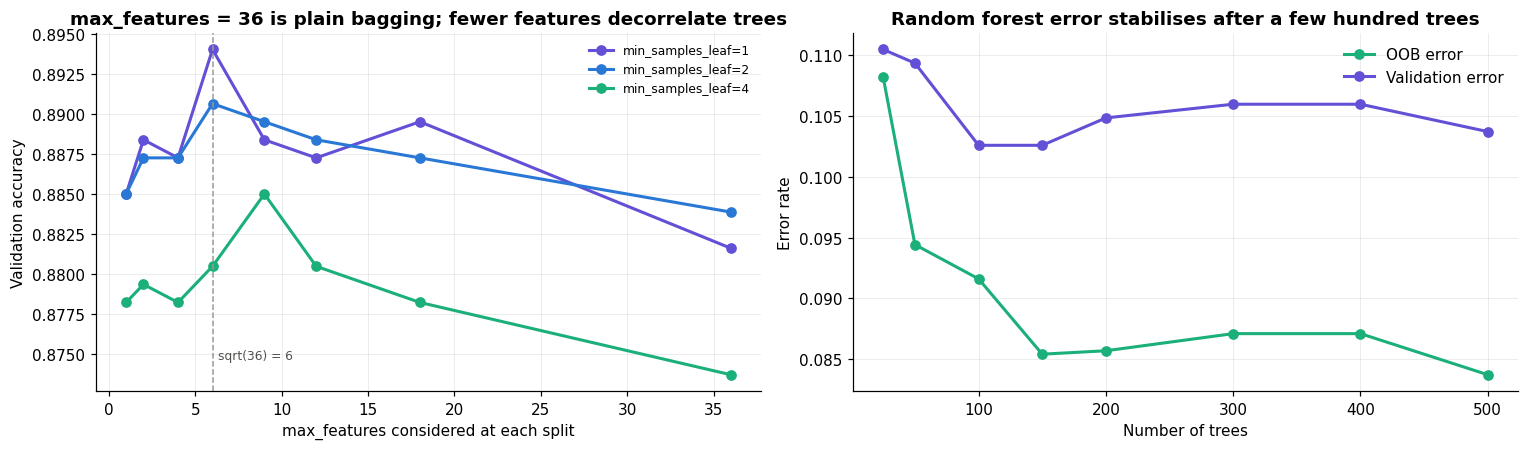

Random forest (tuned)                         val acc 0.8963 | TEST acc 0.9090 | bal acc 0.8885 | macro F1 0.8937 | kappa 0.8879
Extra trees                                   val acc 0.9008 | TEST acc 0.9115 | bal acc 0.8910 | macro F1 0.8974 | kappa 0.8909


In [46]:
best_rf, rf_grid = tune(lambda max_features, min_samples_leaf: RandomForestClassifier(n_estimators=300, max_features=max_features, min_samples_leaf=min_samples_leaf, random_state=SEED, n_jobs=-1),
                        {"max_features": [1, 2, 4, 6, 9, 12, 18, 36], "min_samples_leaf": [1, 2, 4]}, top=5)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for msl, col in zip([1, 2, 4], ["#6250d6", "#2a78d6", "#1baf7a"]):
    r = rf_grid[rf_grid.min_samples_leaf == msl].sort_values("max_features")
    axes[0].plot(r.max_features, r.val_acc, marker="o", lw=2, color=col, label=f"min_samples_leaf={msl}")
axes[0].axvline(6, color="#9a9a96", ls="--", lw=1); axes[0].text(6.3, axes[0].get_ylim()[0] + 0.002, "sqrt(36) = 6", fontsize=8, color="#52514e")
axes[0].set_xlabel("max_features considered at each split"); axes[0].set_ylabel("Validation accuracy")
axes[0].set_title("max_features = 36 is plain bagging; fewer features decorrelate trees"); axes[0].legend(fontsize=8)

rf_oob = RandomForestClassifier(n_estimators=500, warm_start=True, oob_score=True, random_state=SEED, n_jobs=-1,
                                max_features=best_rf["max_features"], min_samples_leaf=best_rf["min_samples_leaf"])
oob_rows = []
for n in [25, 50, 100, 150, 200, 300, 400, 500]:
    rf_oob.set_params(n_estimators=n).fit(FS_TR["full"], y_tr)
    oob_rows.append((n, 1 - rf_oob.oob_score_, 1 - rf_oob.score(FS_VAL["full"], y_val)))
oob_rows = np.array(oob_rows)
axes[1].plot(oob_rows[:, 0], oob_rows[:, 1], marker="o", lw=2, color="#1baf7a", label="OOB error")
axes[1].plot(oob_rows[:, 0], oob_rows[:, 2], marker="o", lw=2, color="#6250d6", label="Validation error")
axes[1].set_xlabel("Number of trees"); axes[1].set_ylabel("Error rate"); axes[1].set_title("Random forest error stabilises after a few hundred trees"); axes[1].legend()
plt.tight_layout(); plt.show()

rf_final, y_pred_rf = fit_eval("Random forest (tuned)", RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1, **best_rf), "full", "Ensemble")
fit_eval("Extra trees", ExtraTreesClassifier(n_estimators=500, random_state=SEED, n_jobs=-1, max_features=best_rf["max_features"]), "full", "Ensemble");

### 14.3 Which Pixels and Bands Matter? (Random Forest Importances)

We aggregate importances back onto the **3 x 3 window**, once with the forest's built-in impurity-based importance (MDI) and once with **permutation importance** (how much test accuracy drops when a feature is randomly shuffled). Permutation importance is more reliable when features are correlated, but it splits credit among correlated features, so we also permute **groups**: all 4 bands of a pixel at once, and each band across all 9 pixels at once.

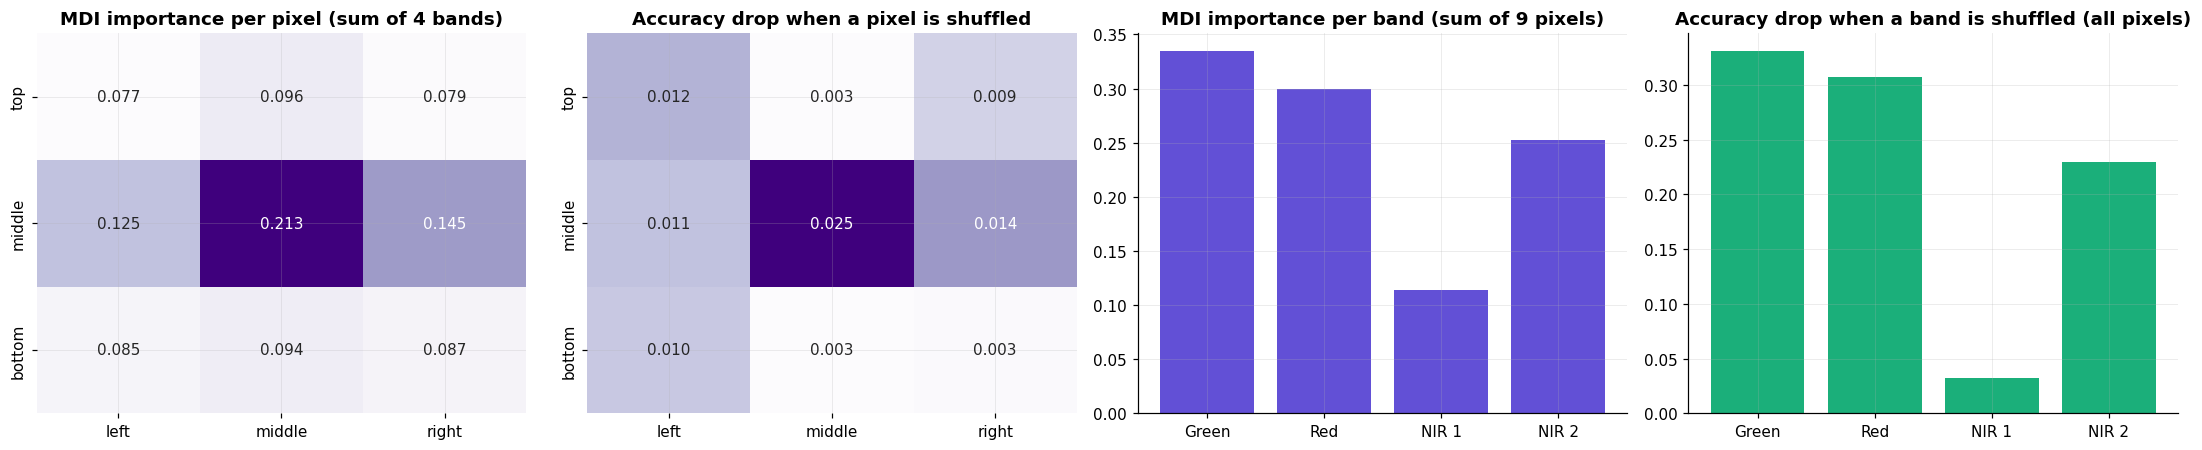

Top 10 individual features by permutation importance:


,center_band_2,top_right_band_2,top_right_band_1,middle_left_band_2,center_band_1,middle_right_band_2,top_left_band_2,center_band_4,top_middle_band_1,bottom_right_band_1
accuracy drop,0.0065,0.0037,0.0032,0.0031,0.0027,0.0027,0.0027,0.0023,0.0022,0.0021


In [47]:
mdi = pd.Series(rf_final.feature_importances_, index=feature_names)
pixel_mdi = np.array([mdi[[f"{p}_band_{b}" for b in range(1, 5)]].sum() for p in pixel_positions]).reshape(3, 3)
band_mdi = pd.Series({BAND_NAMES[b]: mdi[[f for f in feature_names if f.endswith(f"band_{b}")]].sum() for b in range(1, 5)})

def group_permutation(model, X, y, groups, n_repeats=5):
    base = accuracy_score(y, model.predict(X)); rng = np.random.RandomState(SEED); out = {}
    for g, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy(); perm = rng.permutation(len(Xp))
            Xp[cols] = Xp[cols].values[perm]
            drops.append(base - accuracy_score(y, model.predict(Xp)))
        out[g] = np.mean(drops)
    return pd.Series(out)

pix_perm = group_permutation(rf_final, FS_TEST["full"], y_test, {p: [f"{p}_band_{b}" for b in range(1, 5)] for p in pixel_positions})
band_perm = group_permutation(rf_final, FS_TEST["full"], y_test, {BAND_NAMES[b]: [f for f in feature_names if f.endswith(f"band_{b}")] for b in range(1, 5)})

fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
sns.heatmap(pixel_mdi, annot=True, fmt=".3f", cmap="Purples", ax=axes[0], cbar=False, xticklabels=["left", "middle", "right"], yticklabels=["top", "middle", "bottom"])
axes[0].set_title("MDI importance per pixel (sum of 4 bands)")
sns.heatmap(pix_perm.values.reshape(3, 3), annot=True, fmt=".3f", cmap="Purples", ax=axes[1], cbar=False, xticklabels=["left", "middle", "right"], yticklabels=["top", "middle", "bottom"])
axes[1].set_title("Accuracy drop when a pixel is shuffled")
axes[2].bar(band_mdi.index, band_mdi.values, color="#6250d6"); axes[2].set_title("MDI importance per band (sum of 9 pixels)")
axes[3].bar(band_perm.index, band_perm.values, color="#1baf7a"); axes[3].set_title("Accuracy drop when a band is shuffled (all pixels)")
plt.tight_layout(); plt.savefig("fig_rf_importance.png", bbox_inches="tight"); plt.show()

perm = permutation_importance(rf_final, FS_TEST["full"], y_test, n_repeats=5, random_state=SEED, n_jobs=-1)
top_perm = pd.Series(perm.importances_mean, index=feature_names).sort_values(ascending=False).head(10)
print("Top 10 individual features by permutation importance:"); display(top_perm.round(4).to_frame("accuracy drop").T)

**Interpretation.**

- The **central pixel** carries the most importance, as expected because the label belongs to it, but the eight neighbours together carry **more** total importance than the centre alone. The model genuinely uses the neighbourhood (RQ2).
- Shuffling one neighbour barely hurts, because the other neighbours hold almost the same information (redundancy). Shuffling the centre hurts the most.
- Among bands, the **visible bands (Green and Red)** dominate, followed by NIR 2. NIR 1 adds little because it is almost a copy of NIR 2 (the forest can use either, so each gets little credit). Red separates soils from vegetation, and visible brightness separates the dry from the damp grey soils.

### 14.4 Boosting

Boosting builds an **additive model** $F_M(\mathbf{x}) = \sum_{m=1}^{M} \eta\, h_m(\mathbf{x})$ of weak learners added one at a time:

- **AdaBoost** re-weights the training samples after each round, increasing the weights of misclassified samples, so that the next weak learner concentrates on the hard cases. Each learner gets a vote weight $\alpha_m$ that grows with its accuracy.
- **Gradient boosting** fits each new tree to the **negative gradient of the loss** (for log loss, the residuals between true one-hot labels and current predicted probabilities). The learning rate $\eta$ shrinks each step and trades training time for better generalisation.
- **XGBoost / LightGBM / HistGradientBoosting** are fast, regularised implementations of gradient boosting using histogram-binned features.

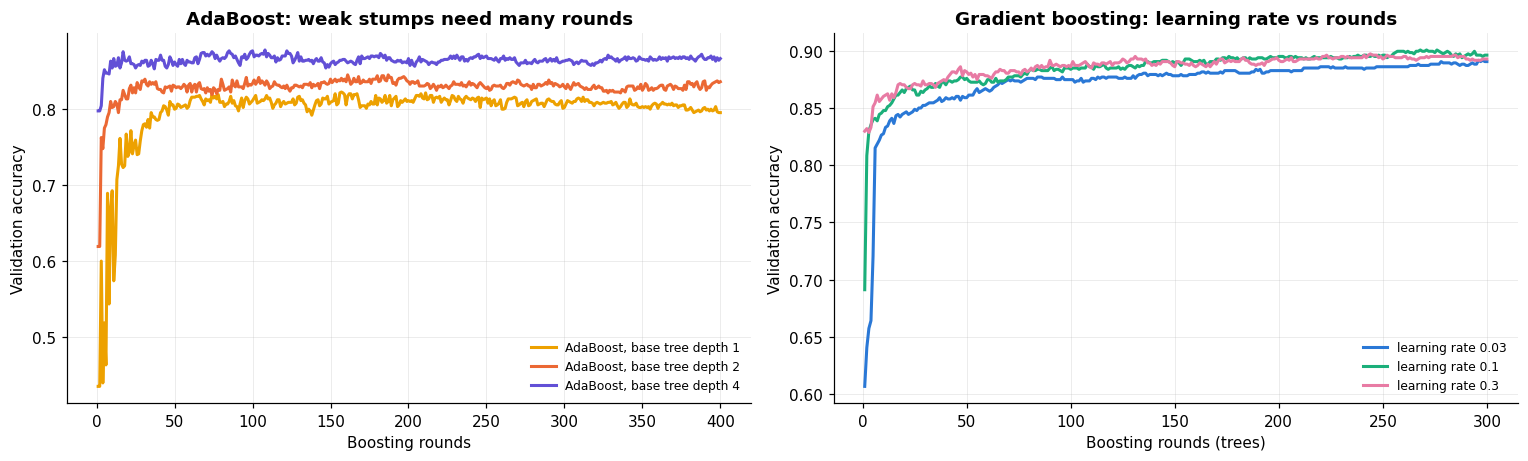

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for depth, col in [(1, "#eda100"), (2, "#eb6834"), (4, "#6250d6")]:
    ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=depth), n_estimators=400, learning_rate=0.5, random_state=SEED).fit(FS_TR["full"], y_tr)
    staged = [accuracy_score(y_val, p) for p in ada.staged_predict(FS_VAL["full"])]
    axes[0].plot(range(1, len(staged) + 1), staged, lw=2, color=col, label=f"AdaBoost, base tree depth {depth}")
axes[0].set_xlabel("Boosting rounds"); axes[0].set_ylabel("Validation accuracy"); axes[0].set_title("AdaBoost: weak stumps need many rounds"); axes[0].legend(fontsize=8)

for lr_, col in [(0.03, "#2a78d6"), (0.1, "#1baf7a"), (0.3, "#e87ba4")]:
    gb = GradientBoostingClassifier(n_estimators=300, learning_rate=lr_, max_depth=3, subsample=0.8, random_state=SEED).fit(FS_TR["full"], y_tr)
    staged = [accuracy_score(y_val, p) for p in gb.staged_predict(FS_VAL["full"])]
    axes[1].plot(range(1, len(staged) + 1), staged, lw=2, color=col, label=f"learning rate {lr_}")
axes[1].set_xlabel("Boosting rounds (trees)"); axes[1].set_ylabel("Validation accuracy"); axes[1].set_title("Gradient boosting: learning rate vs rounds"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_boosting.png", bbox_inches="tight"); plt.show()

In [49]:
best_ada, _ = tune(lambda max_depth, n_estimators, learning_rate: AdaBoostClassifier(DecisionTreeClassifier(max_depth=max_depth), n_estimators=n_estimators, learning_rate=learning_rate, random_state=SEED),
                   {"max_depth": [2, 4, 6], "n_estimators": [200, 400], "learning_rate": [0.3, 1.0]}, top=3)
fit_eval("AdaBoost (tuned)", AdaBoostClassifier(DecisionTreeClassifier(max_depth=best_ada["max_depth"]), n_estimators=best_ada["n_estimators"],
                                                 learning_rate=best_ada["learning_rate"], random_state=SEED), "full", "Ensemble")

fit_eval("Gradient boosting (sklearn)", GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=3, subsample=0.8, random_state=SEED), "full", "Ensemble")

best_hgb, _ = tune(lambda learning_rate, max_leaf_nodes, l2_regularization: HistGradientBoostingClassifier(learning_rate=learning_rate, max_leaf_nodes=max_leaf_nodes, l2_regularization=l2_regularization, max_iter=500, random_state=SEED),
                   {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31, 63], "l2_regularization": [0.0, 1.0]}, top=3)
fit_eval("HistGradientBoosting (tuned)", HistGradientBoostingClassifier(max_iter=500, random_state=SEED, **best_hgb), "full", "Ensemble")

if HAS_XGB:
    make_xgb = lambda n_estimators, max_depth, learning_rate: LabelEncodedClassifier(XGBClassifier(
        n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate, subsample=0.8, colsample_bytree=0.8,
        tree_method="hist", eval_metric="mlogloss", random_state=SEED, n_jobs=-1))
    best_xgb, _ = tune(make_xgb, {"n_estimators": [300, 600], "max_depth": [4, 6], "learning_rate": [0.05, 0.1]}, top=3)
    fit_eval("XGBoost (tuned)", make_xgb(**best_xgb), "full", "Ensemble")
if HAS_LGBM:
    make_lgbm = lambda n_estimators, num_leaves, learning_rate: LGBMClassifier(n_estimators=n_estimators, num_leaves=num_leaves, learning_rate=learning_rate,
                                                                                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1, n_jobs=-1)
    best_lgbm, _ = tune(make_lgbm, {"n_estimators": [300, 600], "num_leaves": [15, 31], "learning_rate": [0.05, 0.1]}, top=3)
    fit_eval("LightGBM (tuned)", make_lgbm(**best_lgbm), "full", "Ensemble");

,learning_rate,max_depth,n_estimators,train_acc,val_acc
0,1.000000,6,400,1.0000,0.9076
1,0.300000,6,400,1.0000,0.9064
2,1.000000,6,200,1.0000,0.9064


Best parameters: {'learning_rate': 1.0, 'max_depth': 6, 'n_estimators': 400}
AdaBoost (tuned)                              val acc 0.9076 | TEST acc 0.9075 | bal acc 0.8892 | macro F1 0.8935 | kappa 0.8862
Gradient boosting (sklearn)                   val acc 0.8963 | TEST acc 0.8990 | bal acc 0.8795 | macro F1 0.8832 | kappa 0.8757


,l2_regularization,learning_rate,max_leaf_nodes,train_acc,val_acc
0,1.000000,0.100000,31,1.0000,0.9132
1,1.000000,0.050000,31,1.0000,0.9098
2,0.000000,0.100000,31,1.0000,0.9087


Best parameters: {'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_leaf_nodes': 31}
HistGradientBoosting (tuned)                  val acc 0.9132 | TEST acc 0.9120 | bal acc 0.8933 | macro F1 0.8977 | kappa 0.8917


,learning_rate,max_depth,n_estimators,train_acc,val_acc
0,0.100000,4,600,1.0000,0.9121
1,0.050000,4,300,0.9980,0.9098
2,0.050000,6,600,1.0000,0.9098


Best parameters: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 600}
XGBoost (tuned)                               val acc 0.9121 | TEST acc 0.9080 | bal acc 0.8895 | macro F1 0.8934 | kappa 0.8868


,learning_rate,n_estimators,num_leaves,train_acc,val_acc
0,0.050000,600,15,1.0000,0.9143
1,0.100000,600,15,1.0000,0.9121
2,0.100000,300,15,1.0000,0.9098


Best parameters: {'learning_rate': 0.05, 'n_estimators': 600, 'num_leaves': 15}
LightGBM (tuned)                              val acc 0.9143 | TEST acc 0.9140 | bal acc 0.8972 | macro F1 0.9019 | kappa 0.8942


**Interpretation.** With decision stumps (depth 1), AdaBoost struggles: a stump uses one feature and one threshold, which is far too weak for six overlapping classes. Slightly deeper base trees fix this, showing that boosting needs a weak learner that is *better than chance on the re-weighted problem*. For gradient boosting, a high learning rate converges in few rounds but plateaus lower or starts to overfit, while a small learning rate needs more rounds but reaches a similar or better level: the classic shrinkage trade-off. All modern gradient-boosting implementations end up close to each other and well above a single tree.

### 14.5 Ensemble Summary: Single Tree vs Bagging vs Random Forest vs Boosting

In [50]:
ens = results_table().query("family in ['Ensemble', 'Decision tree']")[["model", "val_acc", "train_acc", "test_acc", "macro_f1", "fit_s"]]
display(ens.style.format({"val_acc": "{:.4f}", "train_acc": "{:.4f}", "test_acc": "{:.4f}", "macro_f1": "{:.4f}", "fit_s": "{:.2f}"})
        .background_gradient(cmap="Purples", subset=["test_acc"]))

,model,val_acc,train_acc,test_acc,macro_f1,fit_s
0,LightGBM (tuned),0.9143,1.0000,0.9140,0.9019,3.05
1,HistGradientBoosting (tuned),0.9132,1.0000,0.9120,0.8977,10.17
2,Extra trees,0.9008,1.0000,0.9115,0.8974,2.30
3,Random forest (tuned),0.8963,1.0000,0.9090,0.8937,4.30
5,XGBoost (tuned),0.9121,1.0000,0.9080,0.8934,2.94
6,AdaBoost (tuned),0.9076,1.0000,0.9075,0.8935,16.11
8,Bagging (200 trees),0.8873,1.0000,0.9005,0.8854,8.05
9,Gradient boosting (sklearn),0.8963,1.0000,0.8990,0.8832,29.02
12,Decision tree (unpruned baseline),0.8309,1.0000,0.8490,0.8304,0.08
14,"Decision tree (pre-pruned, tuned)",0.8467,0.9678,0.8440,0.8237,0.07


## 15. Beyond the Syllabus: Kernel SVM, Neural Network and Model Stacking

### 15.1 Support Vector Machine with an RBF Kernel

An SVM finds the **maximum-margin** separating hyperplane. The **kernel trick** replaces dot products with a similarity function, here the Gaussian (RBF) kernel $k(\mathbf{x}, \mathbf{x}') = \exp(-\gamma \lVert \mathbf{x} - \mathbf{x}' \rVert^2)$, which corresponds to a linear classifier in an infinite-dimensional feature space. $C$ controls the penalty for margin violations and $\gamma$ the width of the kernel (large $\gamma$ = very local, wiggly boundaries).

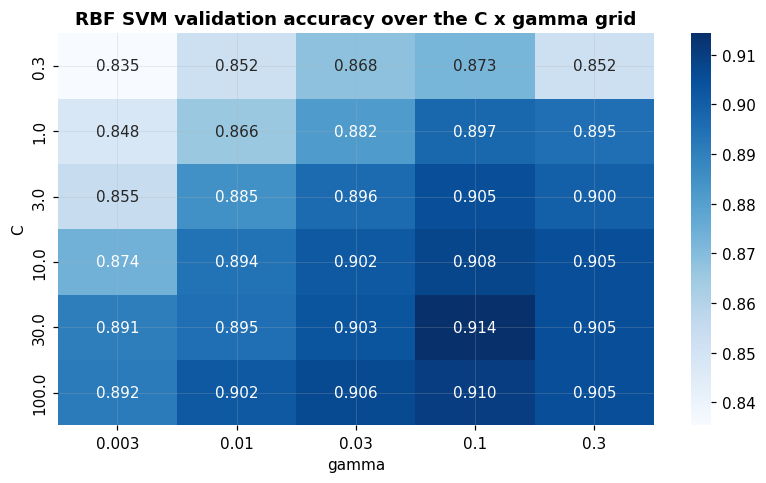

Best: {'C': 30, 'gamma': 0.1}
SVM (RBF kernel, tuned)                       val acc 0.9143 | TEST acc 0.9120 | bal acc 0.8979 | macro F1 0.8997 | kappa 0.8918


In [51]:
best_svm, svm_grid = tune(lambda C, gamma: make_pipeline(StandardScaler(), SVC(C=C, gamma=gamma)),
                          {"C": [0.3, 1, 3, 10, 30, 100], "gamma": [0.003, 0.01, 0.03, 0.1, 0.3]}, verbose=False)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.heatmap(svm_grid.pivot_table(index="C", columns="gamma", values="val_acc"), annot=True, fmt=".3f", cmap="Blues", ax=ax)
ax.set_title("RBF SVM validation accuracy over the C x gamma grid"); plt.tight_layout(); plt.show()
print("Best:", best_svm)
fit_eval("SVM (RBF kernel, tuned)", make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED, **best_svm)), "full", "Kernel / neural");

### 15.2 Multi-Layer Perceptron (Neural Network)

A feed-forward neural network with ReLU hidden layers learns its own non-linear features. We use L2 weight decay (`alpha`) and early stopping to control overfitting.

In [52]:
best_mlp, _ = tune(lambda hidden_layer_sizes, alpha: make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, alpha=alpha, max_iter=1500, early_stopping=True, n_iter_no_change=30, random_state=SEED)),
                   {"hidden_layer_sizes": [(64,), (128,), (128, 64), (256, 128)], "alpha": [1e-4, 1e-3, 1e-2]}, top=3)
fit_eval("MLP neural network (tuned)", make_pipeline(StandardScaler(), MLPClassifier(max_iter=1500, early_stopping=True, n_iter_no_change=30, random_state=SEED, **best_mlp)),
         "full", "Kernel / neural");

,alpha,hidden_layer_sizes,train_acc,val_acc
0,0.010000,"(256, 128)",0.9738,0.9064
1,0.000100,"(256, 128)",0.9839,0.8952
2,0.001000,"(128, 64)",0.9490,0.8940


Best parameters: {'alpha': 0.01, 'hidden_layer_sizes': (256, 128)}
MLP neural network (tuned)                    val acc 0.9064 | TEST acc 0.8970 | bal acc 0.8808 | macro F1 0.8832 | kappa 0.8734


### 15.3 Voting and Stacking Different Model Families

Different families make **different kinds of mistakes** (KNN is local, SVM is margin-based, forests are axis-aligned, boosting is additive), which is exactly the low correlation that ensembles need.

- **Soft voting:** average the predicted probabilities of several models.
- **Stacking:** a meta-model (logistic regression) learns *how much to trust each base model* from their out-of-fold predicted probabilities.

*Note on the no-cross-validation rule:* stacking internally uses 5-fold splits **of the training data only** to create the meta-features. This is part of *training* the stacked model, not of evaluating it; the test set is still used once. Because of overlapping windows, the out-of-fold predictions can be slightly optimistic, so the meta-learner may over-trust the strongest base model.

In [53]:
base_estimators = [
    ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(**best_knn))),
    ("svm", make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED, **best_svm))),
    ("rf", RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1, **best_rf)),
    ("hgb", HistGradientBoostingClassifier(max_iter=500, random_state=SEED, **best_hgb)),
    ("qda", make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis(**best_qda))),
]
fit_eval("Soft voting (KNN+SVM+RF+HGB+QDA)", VotingClassifier(base_estimators, voting="soft", n_jobs=-1), "full", "Ensemble")
stack, _ = fit_eval("Stacking (LogReg meta-learner)", StackingClassifier(base_estimators, final_estimator=LogisticRegression(max_iter=3000, C=1.0),
                                                                          cv=5, stack_method="predict_proba", n_jobs=-1), "full", "Ensemble")

Soft voting (KNN+SVM+RF+HGB+QDA)              val acc 0.9143 | TEST acc 0.9160 | bal acc 0.8958 | macro F1 0.9010 | kappa 0.8965
Stacking (LogReg meta-learner)                val acc 0.9132 | TEST acc 0.9140 | bal acc 0.8935 | macro F1 0.8979 | kappa 0.8941


## 16. Does the Neighbourhood Help? Feature-Set Ablation (RQ2)

We now re-train representative models from every family on all three feature sets, keeping each model's tuned hyperparameters, and compare test accuracy. This answers the central research question directly.

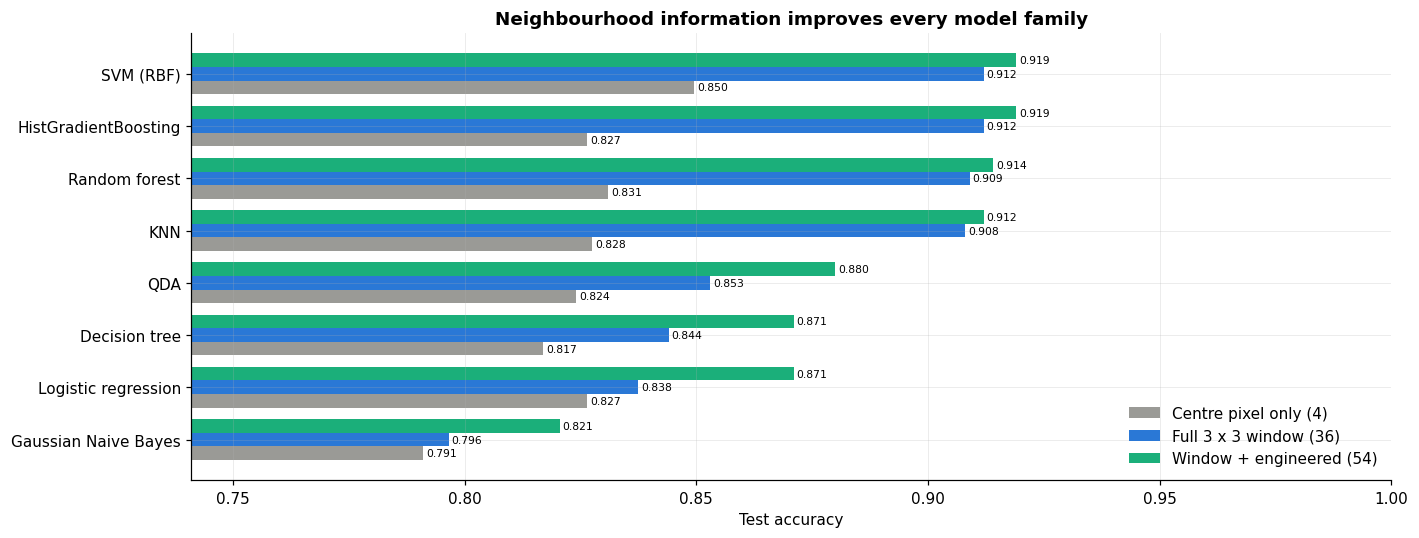

Gain in test accuracy from adding the 8 neighbours (percentage points):


model,Gaussian Naive Bayes,Logistic regression,Decision tree,QDA,KNN,Random forest,HistGradientBoosting,SVM (RBF)
full minus center (pp),0.55,1.1,2.7,2.9,8.05,7.8,8.55,6.25


Extra gain from engineered features (pp):


model,Gaussian Naive Bayes,Logistic regression,Decision tree,QDA,KNN,Random forest,HistGradientBoosting,SVM (RBF)
engineered minus full (pp),2.4,3.35,2.7,2.7,0.4,0.5,0.7,0.7


In [54]:
ablation_models = {
    "KNN": (lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(**best_knn)), "Nearest neighbour"),
    "Gaussian Naive Bayes": (lambda: GaussianNB(), "Probabilistic"),
    "QDA": (lambda: make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis(**best_qda)), "Probabilistic"),
    "Logistic regression": (lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, **best_lr)), "Linear"),
    "Decision tree": (lambda: DecisionTreeClassifier(random_state=SEED, **best_dt), "Decision tree"),
    "Random forest": (lambda: RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1, min_samples_leaf=best_rf["min_samples_leaf"]), "Ensemble"),
    "HistGradientBoosting": (lambda: HistGradientBoostingClassifier(max_iter=500, random_state=SEED, **best_hgb), "Ensemble"),
    "SVM (RBF)": (lambda: make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED, **best_svm)), "Kernel / neural"),
}
abl_rows = []
for name, (make, fam) in ablation_models.items():
    for fs in ("center", "full", "engineered"):
        label = f"{name} [{fs}]"
        fit_eval(label, make(), fs, fam, verbose=False)
        r = next(r for r in RESULTS if r["model"] == label)
        abl_rows.append({"model": name, "features": fs, "test_acc": r["test_acc"], "macro_f1": r["macro_f1"], "val_acc": r["val_acc"]})
abl = pd.DataFrame(abl_rows)
abl_pivot = abl.pivot(index="model", columns="features", values="test_acc")[["center", "full", "engineered"]].sort_values("full")

fig, ax = plt.subplots(figsize=(13, 5))
y_pos = np.arange(len(abl_pivot)); h = 0.26
for i, (fs, col) in enumerate([("center", "#9a9a96"), ("full", "#2a78d6"), ("engineered", "#1baf7a")]):
    bars = ax.barh(y_pos + (i - 1) * h, abl_pivot[fs], h, color=col, label={"center": "Centre pixel only (4)", "full": "Full 3 x 3 window (36)", "engineered": "Window + engineered (54)"}[fs])
    ax.bar_label(bars, fmt="%.3f", fontsize=7, padding=2)
ax.set_yticks(y_pos, abl_pivot.index); ax.set_xlim(abl_pivot.values.min() - 0.05, 1.0)
ax.set_xlabel("Test accuracy"); ax.set_title("Neighbourhood information improves every model family"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("fig_ablation.png", bbox_inches="tight"); plt.show()

gain = (abl_pivot["full"] - abl_pivot["center"]) * 100
print("Gain in test accuracy from adding the 8 neighbours (percentage points):"); display(gain.round(2).to_frame("full minus center (pp)").T)
print("Extra gain from engineered features (pp):"); display(((abl_pivot["engineered"] - abl_pivot["full"]) * 100).round(2).to_frame("engineered minus full (pp)").T)

**Interpretation (RQ2).** For every model family, adding the eight neighbouring pixels raises test accuracy over the centre pixel alone. The gain is large for flexible models (KNN +8.1, random forest +7.8, gradient boosting +8.6, SVM +6.3 percentage points) and small for Naive Bayes (+0.6) and logistic regression (+1.1), which cannot exploit 36 strongly correlated raw inputs well. Two mechanisms explain this:

1. **Noise reduction:** the neighbours are additional measurements of (usually) the same surface, so the model effectively averages away sensor noise.
2. **Context / texture:** the window reveals whether the pixel is inside a uniform field or near a boundary, which a single pixel cannot show.

Engineered features (neighbourhood statistics, NDVI) bring a further gain mainly for models that struggle with raw correlated inputs (Naive Bayes, single trees, linear models), because they hand those models the averaged and ratio information directly. Flexible models (SVM, KNN, forests) can already extract most of it from the raw window, so their gain is smaller.

## 17. Final Model Comparison

### 17.1 Leaderboard

All models below were tuned on the validation split only, then re-fitted on the full training file and evaluated once on the 2,000 test pixels.

In [55]:
res = results_table()
cols = ["model", "family", "features", "val_acc", "train_acc", "test_acc", "balanced_acc", "macro_f1", "kappa", "log_loss", "fit_s", "predict_s"]
display(res[cols].style.format({c: "{:.4f}" for c in ["val_acc", "train_acc", "test_acc", "balanced_acc", "macro_f1", "kappa", "log_loss"]} | {"fit_s": "{:.2f}", "predict_s": "{:.3f}"})
        .background_gradient(cmap="Blues", subset=["test_acc", "macro_f1"]).set_caption("All models, sorted by test accuracy"))
res.to_csv("model_results.csv", index=False)

,model,family,features,val_acc,train_acc,test_acc,balanced_acc,macro_f1,kappa,log_loss,fit_s,predict_s
0,HistGradientBoosting [engineered],Ensemble,engineered,0.9154,1.0000,0.9190,0.9017,0.9066,0.9003,0.2827,15.44,0.623
1,SVM (RBF) [engineered],Kernel / neural,engineered,0.9087,0.9998,0.9190,0.9017,0.9040,0.9004,0.2257,3.96,0.413
2,Soft voting (KNN+SVM+RF+HGB+QDA),Ensemble,full,0.9143,0.9980,0.9160,0.8958,0.9010,0.8965,0.2173,16.40,1.516
3,LightGBM (tuned),Ensemble,full,0.9143,1.0000,0.9140,0.8972,0.9019,0.8942,0.3676,3.05,0.309
4,Random forest [engineered],Ensemble,engineered,0.9053,1.0000,0.9140,0.8916,0.8977,0.8940,0.2423,5.59,0.162
5,Stacking (LogReg meta-learner),Ensemble,full,0.9132,0.9953,0.9140,0.8935,0.8979,0.8941,0.2463,88.55,1.369
6,HistGradientBoosting (tuned),Ensemble,full,0.9132,1.0000,0.9120,0.8933,0.8977,0.8917,0.3251,10.17,0.572
7,"SVM (RBF kernel, tuned)",Kernel / neural,full,0.9143,0.9910,0.9120,0.8979,0.8997,0.8918,0.2382,1.86,0.198
8,KNN [engineered],Nearest neighbour,engineered,0.8952,0.9531,0.9120,0.8955,0.8999,0.8917,0.8838,0.01,0.520
9,HistGradientBoosting [full],Ensemble,full,0.9132,1.0000,0.9120,0.8933,0.8977,0.8917,0.3251,10.57,0.550


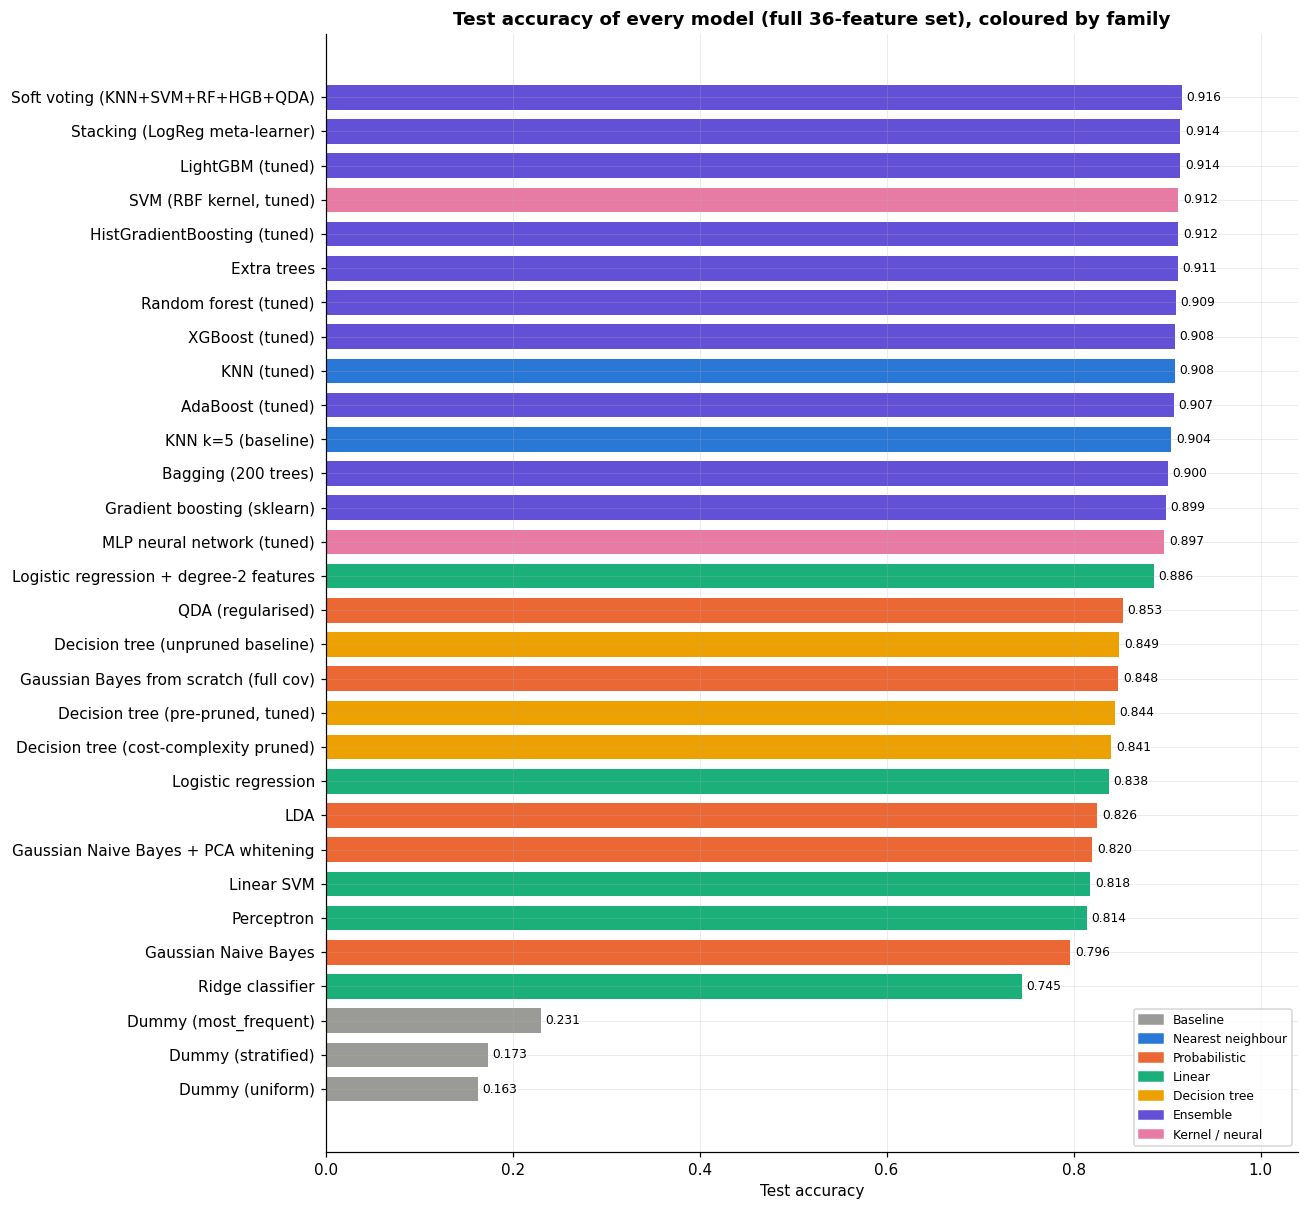

In [56]:
main = res[~res.model.str.contains(r"\[")].sort_values("test_acc")
fig, ax = plt.subplots(figsize=(12, 0.32 * len(main) + 1.5))
bars = ax.barh(main.model, main.test_acc, color=[FAMILY_COLORS[f] for f in main.family], height=0.72)
ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=3)
ax.set_xlim(0, 1.04); ax.set_xlabel("Test accuracy")
ax.set_title("Test accuracy of every model (full 36-feature set), coloured by family")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLORS.values()]
ax.legend(handles, FAMILY_COLORS.keys(), loc="lower right", fontsize=8, frameon=True)
plt.tight_layout(); plt.savefig("fig_leaderboard.png", bbox_inches="tight"); plt.show()

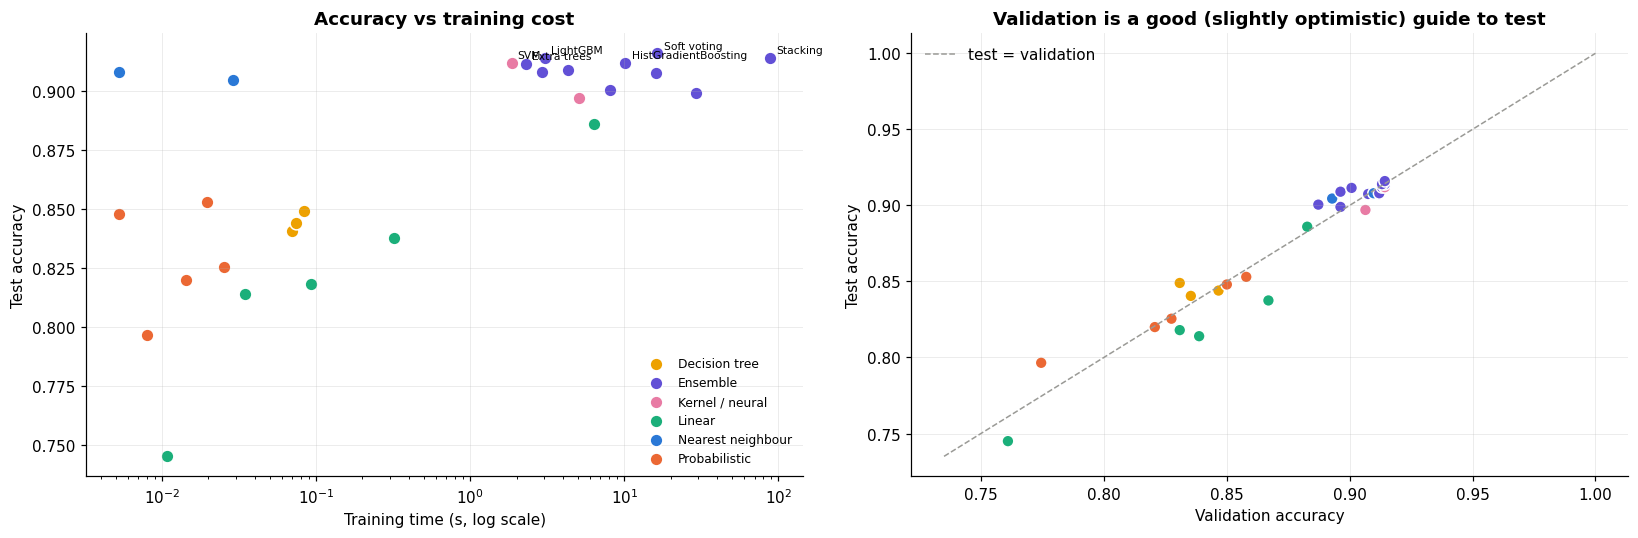

Mean (validation minus test) accuracy: +0.0005


In [57]:
real = main[main.family != "Baseline"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for fam, g in real.groupby("family"):
    axes[0].scatter(g.fit_s, g.test_acc, s=70, color=FAMILY_COLORS[fam], label=fam, edgecolor="white", linewidth=1)
for _, r in real.nlargest(6, "test_acc").iterrows():
    axes[0].annotate(r.model.split(" (")[0], (r.fit_s, r.test_acc), fontsize=7, xytext=(4, 3), textcoords="offset points")
axes[0].set_xscale("log"); axes[0].set_xlabel("Training time (s, log scale)"); axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Accuracy vs training cost"); axes[0].legend(fontsize=8)

axes[1].scatter(real.val_acc, real.test_acc, s=60, c=[FAMILY_COLORS[f] for f in real.family], edgecolor="white", linewidth=1)
lo = min(real.val_acc.min(), real.test_acc.min()) - 0.01
axes[1].plot([lo, 1], [lo, 1], color="#9a9a96", ls="--", lw=1, label="test = validation")
axes[1].set_xlabel("Validation accuracy"); axes[1].set_ylabel("Test accuracy"); axes[1].set_title("Validation is a good (slightly optimistic) guide to test"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Mean (validation minus test) accuracy: {(real.val_acc - real.test_acc).mean():+.4f}")

**Interpretation.** The points lie close to the diagonal and the mean gap between validation and test accuracy is essentially zero (+0.0005). The optimism the dataset authors warned about (overlapping windows) turned out to be small for this split, but we still never select or report on test data. The ranking of models is preserved well, so validation was a reliable tool for *choosing* hyperparameters.

### 17.2 Per-Class Performance

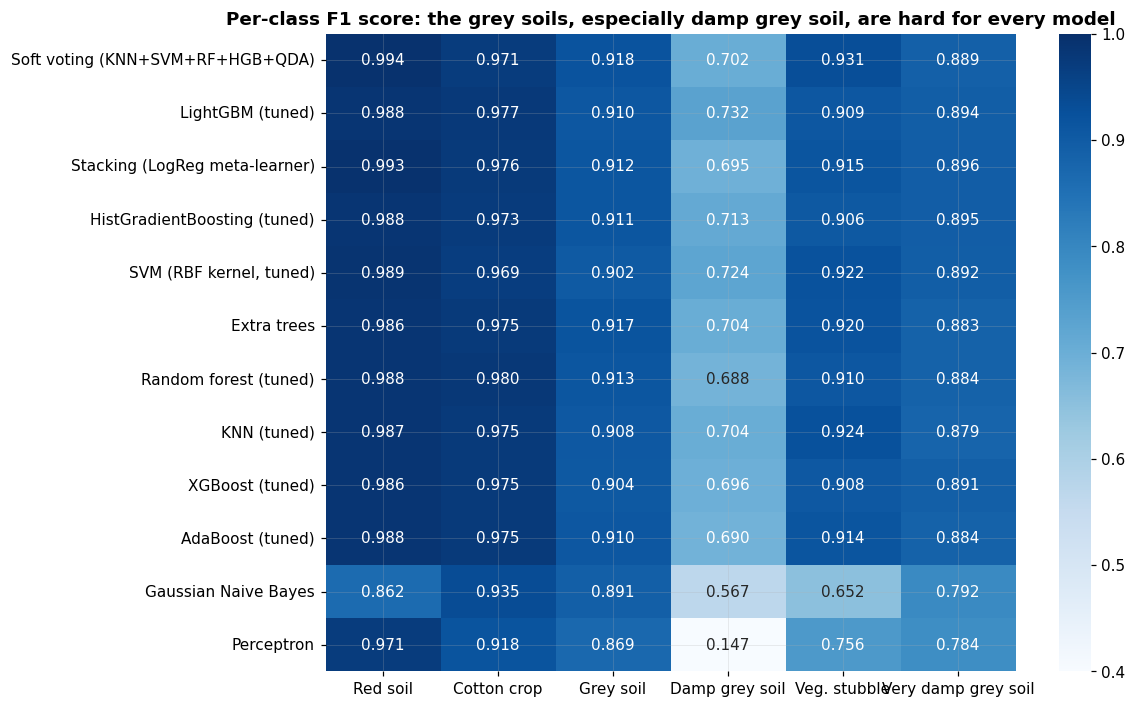

In [58]:
top_models = real.sort_values("test_acc", ascending=False).head(10).model.tolist() + ["Gaussian Naive Bayes", "Perceptron"]
top_models = list(dict.fromkeys(top_models))
f1_tbl = pd.DataFrame({m: f1_score(y_test, PREDS[m], average=None, labels=CLASSES) for m in top_models}, index=[CLASS_NAMES[c] for c in CLASSES]).T
fig, ax = plt.subplots(figsize=(11, 0.42 * len(f1_tbl) + 1.5))
sns.heatmap(f1_tbl, annot=True, fmt=".3f", cmap="Blues", vmin=0.4, vmax=1, ax=ax)
ax.set_title("Per-class F1 score: the grey soils, especially damp grey soil, are hard for every model")
plt.tight_layout(); plt.savefig("fig_per_class_f1.png", bbox_inches="tight"); plt.show()

### 17.3 The Champion Model

The champion is the model with the **highest validation accuracy** (not test accuracy), so that its test score remains an honest estimate.

**Champion (chosen on validation): `HistGradientBoosting [engineered]`**, test accuracy **0.9190**, macro F1 **0.9066**, kappa **0.9003**

                     precision    recall  f1-score   support

           Red soil      0.977     0.993     0.985       461
        Cotton crop      0.982     0.969     0.975       224
          Grey soil      0.902     0.932     0.917       397
     Damp grey soil      0.807     0.692     0.745       211
       Veg. stubble      0.922     0.903     0.913       237
Very damp grey soil      0.889     0.921     0.905       470

           accuracy                          0.919      2000
          macro avg      0.913     0.902     0.907      2000
       weighted avg      0.918     0.919     0.918      2000



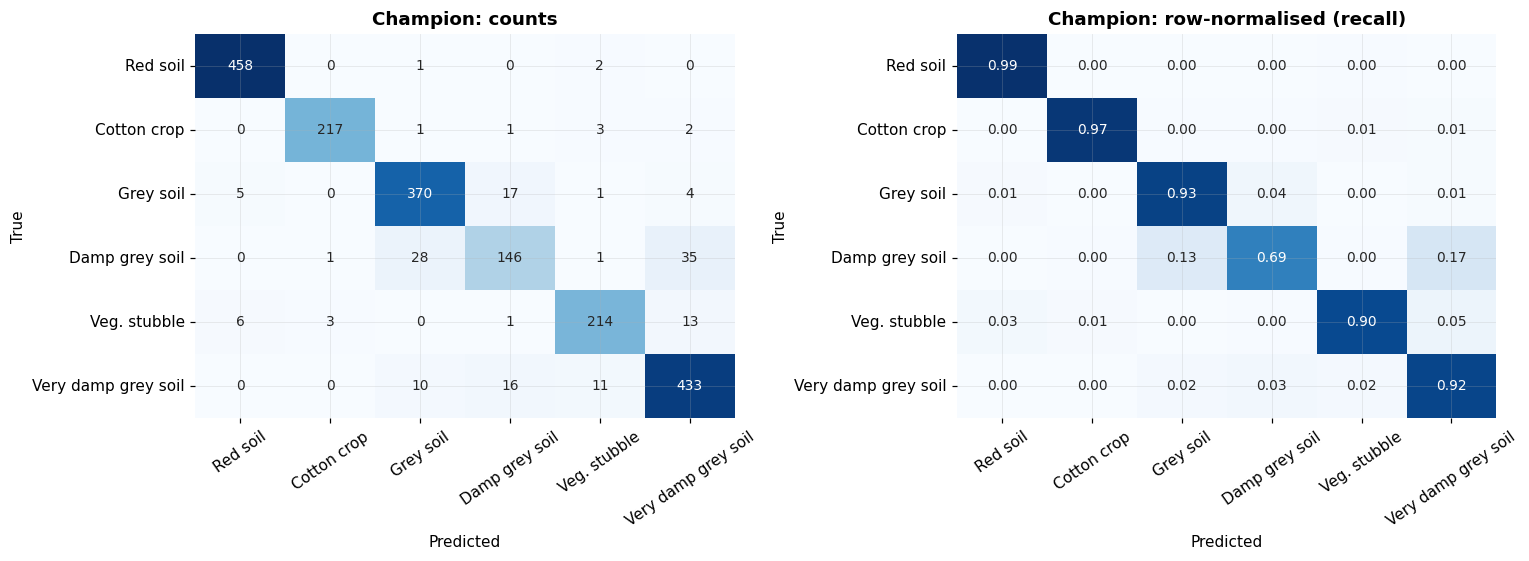

In [59]:
cand = res[(res.family != "Baseline") & res.model.isin(list(PROBAS.keys()))]   # includes feature-set variants
champion = cand.sort_values(["val_acc", "macro_f1"], ascending=False).iloc[0].model
champ_model, champ_fs = MODELS[champion]
y_pred_best = PREDS[champion]
display(Markdown(f"**Champion (chosen on validation): `{champion}`**, test accuracy **{accuracy_score(y_test, y_pred_best):.4f}**, "
                 f"macro F1 **{f1_score(y_test, y_pred_best, average='macro'):.4f}**, kappa **{cohen_kappa_score(y_test, y_pred_best):.4f}**"))
print(classification_report(y_test, y_pred_best, target_names=[CLASS_NAMES[c] for c in CLASSES], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
plot_cm(y_test, y_pred_best, "Champion: counts", axes[0], normalize=False)
plot_cm(y_test, y_pred_best, "Champion: row-normalised (recall)", axes[1])
plt.tight_layout(); plt.savefig("fig_champion_cm.png", bbox_inches="tight"); plt.show()

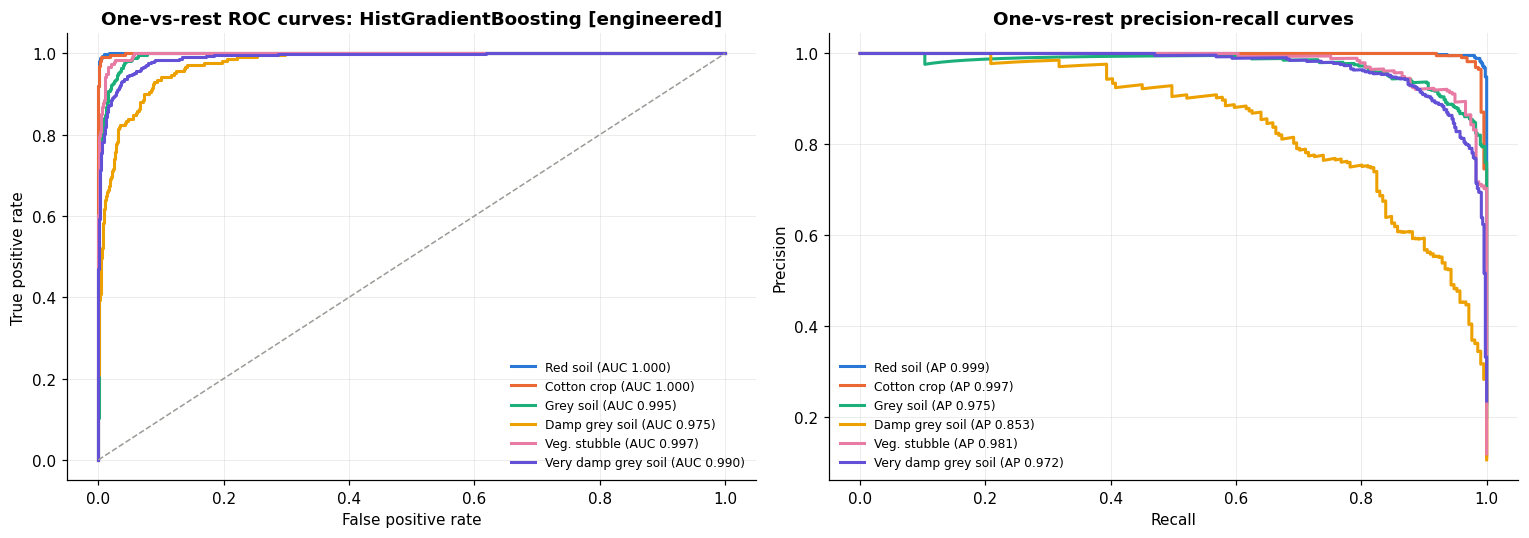

In [60]:
P_best = PROBAS[champion]
Y_bin = label_binarize(y_test, classes=CLASSES)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(Y_bin[:, i], P_best[:, i])
    axes[0].plot(fpr, tpr, lw=2, color=CLASS_COLORS[c], label=f"{CLASS_NAMES[c]} (AUC {auc(fpr, tpr):.3f})")
    prec, rec, _ = precision_recall_curve(Y_bin[:, i], P_best[:, i])
    axes[1].plot(rec, prec, lw=2, color=CLASS_COLORS[c], label=f"{CLASS_NAMES[c]} (AP {average_precision_score(Y_bin[:, i], P_best[:, i]):.3f})")
axes[0].plot([0, 1], [0, 1], color="#9a9a96", ls="--", lw=1)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title(f"One-vs-rest ROC curves: {champion}"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("One-vs-rest precision-recall curves"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_roc_pr.png", bbox_inches="tight"); plt.show()

### 17.4 Is the Difference Real? McNemar's Test and Bootstrap Confidence Intervals

Small accuracy differences on 2,000 test pixels can be due to chance.

- **McNemar's test** compares two classifiers on the *same* test samples using only the samples where they disagree: $b$ = A right and B wrong, $c$ = A wrong and B right. Under the null hypothesis of equal error rates, $\chi^2 = \frac{(|b - c| - 1)^2}{b + c}$ follows a $\chi^2_1$ distribution.
- **Bootstrap confidence intervals** resample the 2,000 test predictions with replacement 2,000 times to show the uncertainty of each accuracy.

,compared with,champion right / other wrong,champion wrong / other right,chi2,p-value,significant at 5%
0,Soft voting (KNN+SVM+RF+HGB+QDA),49,43,0.27,0.6022,no
1,LightGBM (tuned),46,36,0.99,0.3203,no
2,Stacking (LogReg meta-learner),54,44,0.83,0.3633,no
3,HistGradientBoosting (tuned),45,31,2.22,0.1359,no
4,"SVM (RBF kernel, tuned)",69,55,1.36,0.2430,no
5,Extra trees,56,41,2.02,0.1552,no
6,KNN k=5 (baseline),79,50,6.08,0.0137,yes
7,Decision tree (unpruned baseline),190,50,80.50,0.0000,yes
8,Logistic regression,210,47,102.12,0.0000,yes


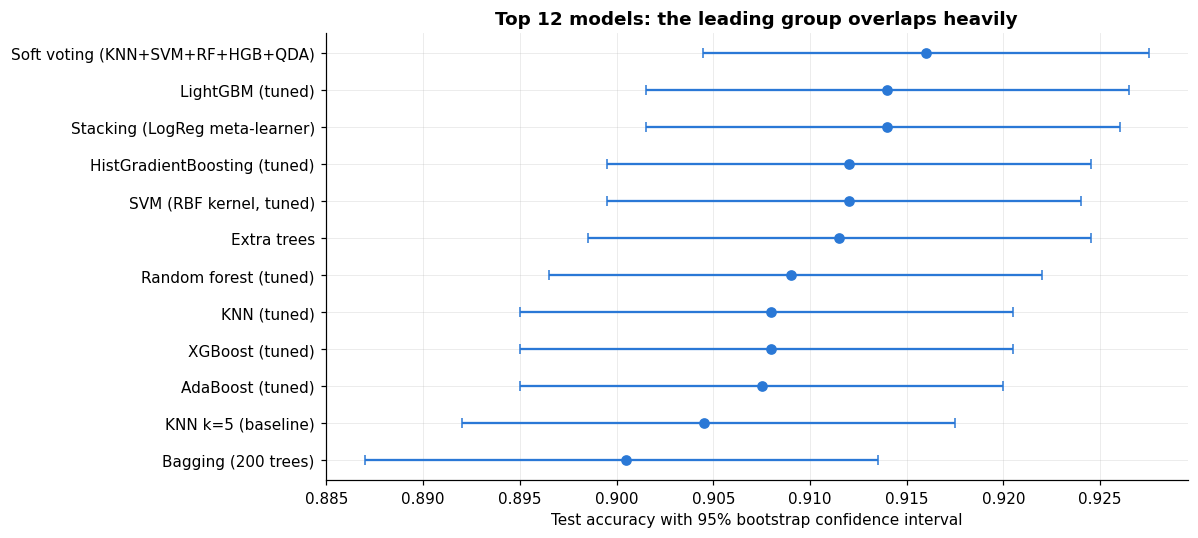

In [61]:
def mcnemar(pred_a, pred_b):
    a_ok, b_ok = pred_a == y_test, pred_b == y_test
    b, c = np.sum(a_ok & ~b_ok), np.sum(~a_ok & b_ok)
    chi2 = (abs(b - c) - 1) ** 2 / (b + c) if b + c > 0 else 0.0
    return b, c, chi2, stats.chi2.sf(chi2, 1)

others = [m for m in real.sort_values("test_acc", ascending=False).model if m != champion][:6] + ["KNN k=5 (baseline)", "Decision tree (unpruned baseline)", "Logistic regression"]
rows = []
for m in dict.fromkeys(others):
    b, c, chi2, p = mcnemar(y_pred_best, PREDS[m])
    rows.append({"compared with": m, "champion right / other wrong": b, "champion wrong / other right": c, "chi2": chi2, "p-value": p,
                 "significant at 5%": "yes" if p < 0.05 else "no"})
display(pd.DataFrame(rows).style.format({"chi2": "{:.2f}", "p-value": "{:.4f}"}).set_caption(f"McNemar tests: {champion} vs others"))

rng = np.random.RandomState(SEED)
boot_idx = rng.randint(0, len(y_test), size=(2000, len(y_test)))
ci_models = real.sort_values("test_acc", ascending=False).head(12).model.tolist()
ci = []
for m in ci_models:
    correct = (PREDS[m] == y_test).astype(float)
    accs = correct[boot_idx].mean(axis=1)
    ci.append((m, correct.mean(), *np.percentile(accs, [2.5, 97.5])))
ci = pd.DataFrame(ci, columns=["model", "acc", "lo", "hi"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5))
ax.errorbar(ci.acc, ci.model, xerr=[ci.acc - ci.lo, ci.hi - ci.acc], fmt="o", color="#2a78d6", ecolor="#2a78d6", capsize=3, lw=1.5, ms=6)
ax.set_xlabel("Test accuracy with 95% bootstrap confidence interval"); ax.set_title("Top 12 models: the leading group overlaps heavily")
plt.tight_layout(); plt.savefig("fig_bootstrap_ci.png", bbox_inches="tight"); plt.show()

**Interpretation.** The confidence intervals of the top models overlap by a large margin, and McNemar's test usually cannot separate the champion from the next few models: **the strongest methods are statistically tied**. The champion is, however, significantly better than the weaker baselines (unpruned tree, linear models). The honest conclusion is therefore "a group of flexible non-linear models reach roughly 91 to 92% accuracy", rather than "model X is the best".

### 17.5 Probability Calibration: Good Classifiers Know When They Are Unsure

A model is **calibrated** if, among predictions made with confidence $p$, a share $p$ is correct. We measure it with a reliability diagram and the **Expected Calibration Error**:

$$\text{ECE} = \sum_{b} \frac{|B_b|}{n} \, \big|\text{acc}(B_b) - \text{conf}(B_b)\big|$$

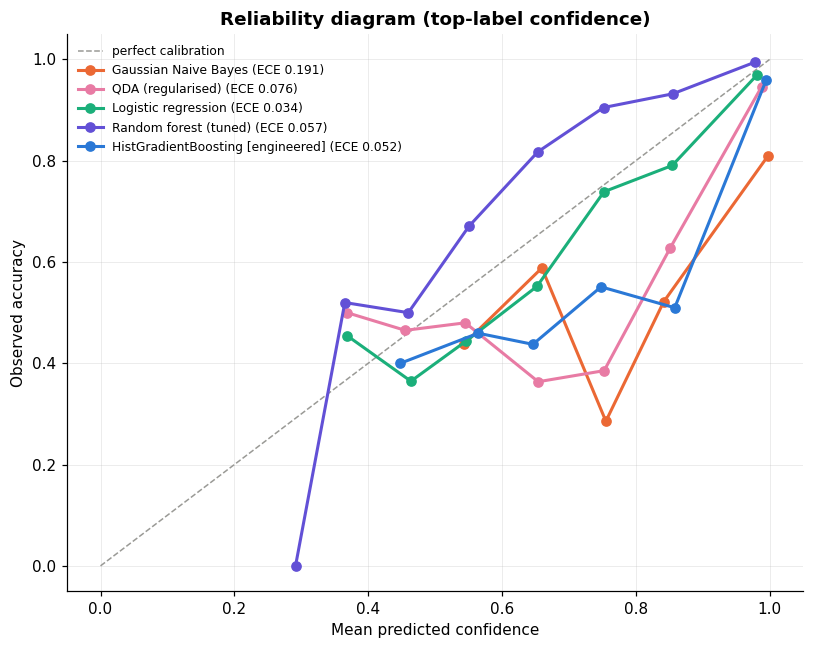

,model,ECE,log loss
0,Gaussian Naive Bayes,0.1906,3.9110
1,QDA (regularised),0.0758,0.4900
2,Logistic regression,0.0341,0.3852
3,Random forest (tuned),0.0570,0.2615
4,HistGradientBoosting [engineered],0.0516,0.2827


In [62]:
def reliability(proba, pred, n_bins=10):
    conf = proba.max(axis=1); correct = pred == y_test
    bins = np.linspace(0, 1, n_bins + 1); idx = np.clip(np.digitize(conf, bins) - 1, 0, n_bins - 1)
    xs, ys, ece = [], [], 0.0
    for b in range(n_bins):
        m = idx == b
        if m.sum() > 0:
            xs.append(conf[m].mean()); ys.append(correct[m].mean()); ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return np.array(xs), np.array(ys), ece

cal_models = [("Gaussian Naive Bayes", "#eb6834"), ("QDA (regularised)", "#e87ba4"), ("Logistic regression", "#1baf7a"),
              ("Random forest (tuned)", "#6250d6"), (champion, "#2a78d6")]
cal_models = list(dict(cal_models).items())
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.plot([0, 1], [0, 1], color="#9a9a96", ls="--", lw=1, label="perfect calibration")
ece_rows = []
for m, col in cal_models:
    xs, ys, ece = reliability(PROBAS[m], PREDS[m])
    ax.plot(xs, ys, marker="o", lw=2, color=col, label=f"{m} (ECE {ece:.3f})")
    ece_rows.append({"model": m, "ECE": ece, "log loss": log_loss(y_test, np.clip(PROBAS[m], 1e-15, 1), labels=CLASSES)})
ax.set_xlabel("Mean predicted confidence"); ax.set_ylabel("Observed accuracy"); ax.set_title("Reliability diagram (top-label confidence)")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.savefig("fig_calibration.png", bbox_inches="tight"); plt.show()
display(pd.DataFrame(ece_rows).style.format({"ECE": "{:.4f}", "log loss": "{:.4f}"}))

**Interpretation.** Naive Bayes sits far below the diagonal at high confidence: it claims near-certainty but is often wrong, the overconfidence predicted in Section 11.6. Random forests tend to be slightly *under*confident (votes are averaged, so probabilities are pulled towards the middle). Logistic regression and the strongest models are close to the diagonal. For applications that use probabilities, such as the cost-sensitive decisions in Section 11.5, calibration is as important as accuracy.

### 17.6 Learning Curve of the Champion

Would more labelled data help? We train the champion on growing fractions of `train-part` and score it on `validation`.

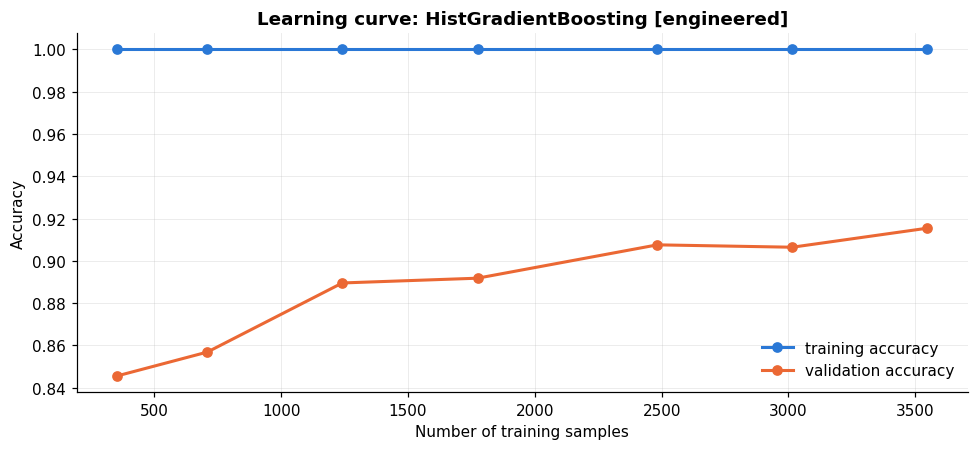

In [63]:
fracs = [0.1, 0.2, 0.35, 0.5, 0.7, 0.85, 1.0]
rng = np.random.RandomState(SEED)
lc = []
for f in fracs:
    sub = np.sort(rng.choice(len(y_tr), int(f * len(y_tr)), replace=False)) if f < 1 else np.arange(len(y_tr))
    m = clone(champ_model).fit(FS_TR[champ_fs].iloc[sub], y_tr[sub])
    lc.append((len(sub), accuracy_score(y_tr[sub], m.predict(FS_TR[champ_fs].iloc[sub])), accuracy_score(y_val, m.predict(FS_VAL[champ_fs]))))
lc = np.array(lc)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(lc[:, 0], lc[:, 1], marker="o", lw=2, color="#2a78d6", label="training accuracy")
ax.plot(lc[:, 0], lc[:, 2], marker="o", lw=2, color="#eb6834", label="validation accuracy")
ax.set_xlabel("Number of training samples"); ax.set_ylabel("Accuracy"); ax.set_title(f"Learning curve: {champion}"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretation.** Validation accuracy is still rising slowly at the full training size, so more labelled pixels would help a little, but the curve is flattening: we are approaching the limit set by genuine spectral overlap between the grey-soil classes rather than by the amount of data.

## 18. Error Analysis

Where, and why, does the champion still fail?

Total errors: 162 of 2000 (8.1%)
Errors that are confusions WITHIN the grey-soil group (3, 4, 7): 67.9%


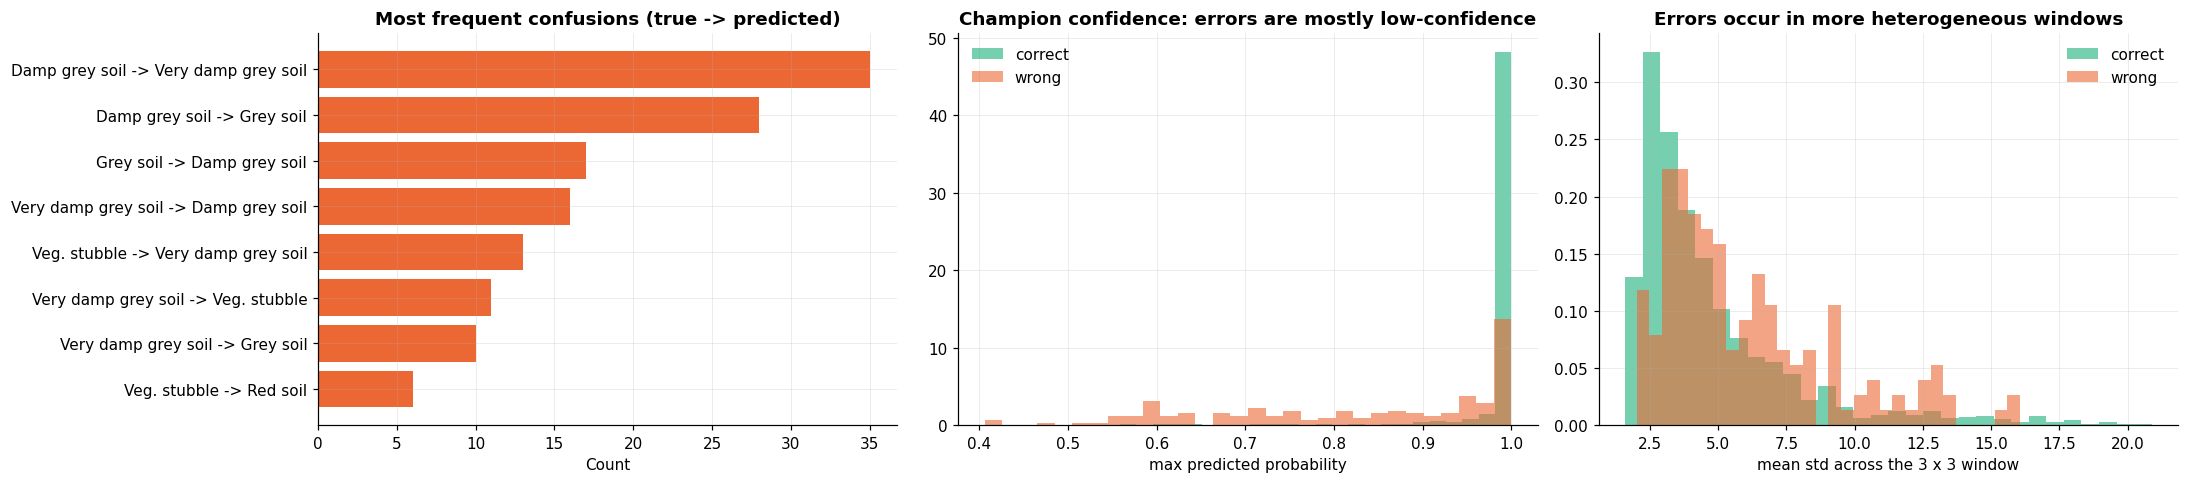

Mean window heterogeneity: correct 4.73 vs wrong 6.02
If we only accept predictions with confidence >= 0.6: coverage 97.9%, accuracy 0.9290
If we only accept predictions with confidence >= 0.8: coverage 93.8%, accuracy 0.9473
If we only accept predictions with confidence >= 0.9: coverage 91.3%, accuracy 0.9595


In [64]:
err = pd.DataFrame({"true": y_test, "pred": y_pred_best})
err = err[err.true != err.pred]
pairs = err.groupby(["true", "pred"]).size().sort_values(ascending=False).head(8)
pairs.index = [f"{CLASS_NAMES[t]} -> {CLASS_NAMES[p]}" for t, p in pairs.index]
print(f"Total errors: {len(err)} of {len(y_test)} ({len(err) / len(y_test):.1%})")
grey = err.true.isin([3, 4, 7]) & err.pred.isin([3, 4, 7])
print(f"Errors that are confusions WITHIN the grey-soil group (3, 4, 7): {grey.mean():.1%}")

test_eng = FS_TEST["engineered"]
wrong = y_pred_best != y_test
heterog = test_eng[[f"nbhd_std_b{b}" for b in range(1, 5)]].mean(axis=1)
conf_best = PROBAS[champion].max(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
axes[0].barh(pairs.index[::-1], pairs.values[::-1], color="#eb6834"); axes[0].set_title("Most frequent confusions (true -> predicted)"); axes[0].set_xlabel("Count")
axes[1].hist(conf_best[~wrong], bins=30, alpha=0.6, density=True, color="#1baf7a", label="correct")
axes[1].hist(conf_best[wrong], bins=30, alpha=0.6, density=True, color="#eb6834", label="wrong")
axes[1].set_title("Champion confidence: errors are mostly low-confidence"); axes[1].set_xlabel("max predicted probability"); axes[1].legend()
axes[2].hist(heterog[~wrong], bins=30, alpha=0.6, density=True, color="#1baf7a", label="correct")
axes[2].hist(heterog[wrong], bins=30, alpha=0.6, density=True, color="#eb6834", label="wrong")
axes[2].set_title("Errors occur in more heterogeneous windows"); axes[2].set_xlabel("mean std across the 3 x 3 window"); axes[2].legend()
plt.tight_layout(); plt.savefig("fig_error_analysis.png", bbox_inches="tight"); plt.show()

print(f"Mean window heterogeneity: correct {heterog[~wrong].mean():.2f} vs wrong {heterog[wrong].mean():.2f}")
for t in (0.6, 0.8, 0.9):
    keep = conf_best >= t
    print(f"If we only accept predictions with confidence >= {t}: coverage {keep.mean():.1%}, accuracy {accuracy_score(y_test[keep], y_pred_best[keep]):.4f}")

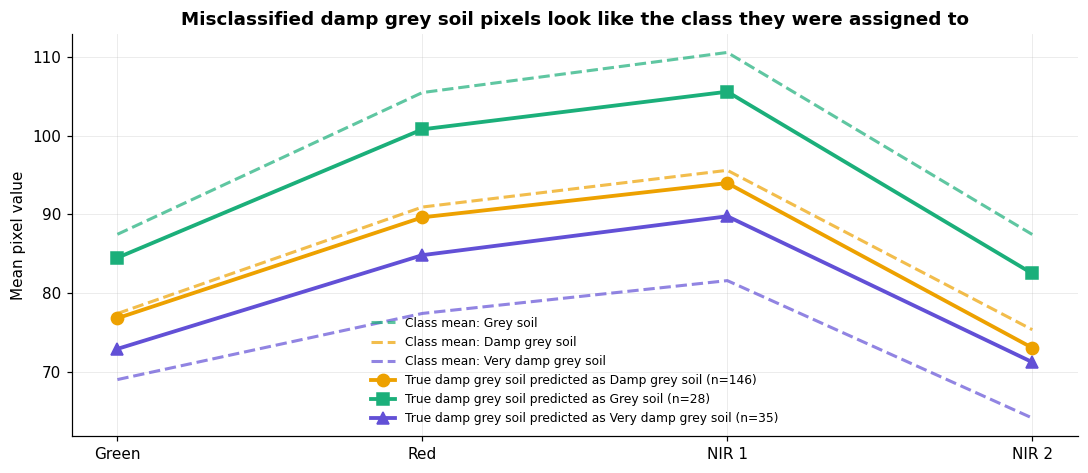

In [65]:
# Spectral signature of damp grey soil pixels that were classified correctly vs as grey soil / very damp grey soil
c4 = y_test == 4
fig, ax = plt.subplots(figsize=(10, 4.4))
for c in (3, 4, 7):
    ax.plot(bands, df_train.loc[df_train[TARGET] == c, center_features].mean().values, lw=2, ls="--", color=CLASS_COLORS[c], alpha=0.7, label=f"Class mean: {CLASS_NAMES[c]}")
for p, mk in [(4, "o"), (3, "s"), (7, "^")]:
    sel = c4 & (y_pred_best == p)
    if sel.sum() > 0:
        ax.plot(bands, df_test.loc[sel, center_features].mean().values, lw=2.5, marker=mk, ms=8, color=CLASS_COLORS[p],
                label=f"True damp grey soil predicted as {CLASS_NAMES[p]} (n={sel.sum()})")
ax.set_ylabel("Mean pixel value"); ax.set_title("Misclassified damp grey soil pixels look like the class they were assigned to")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig("fig_damp_grey_soil.png", bbox_inches="tight"); plt.show()

**Interpretation.**

- Most remaining errors are confusions **inside the grey-soil group**, above all damp grey soil being predicted as grey soil or very damp grey soil.
- The misclassified damp grey soil pixels have spectra that genuinely sit on top of the class they were assigned to. Soil moisture is a **continuous** property that has been cut into three discrete classes, so pixels near the cut points are intrinsically ambiguous. This is close to the **Bayes error** of the problem: better models cannot fix it, only additional information (for example thermal bands, a time series, or soil-moisture data) can.
- Errors are concentrated in **heterogeneous windows**, which are mixed pixels at field boundaries, and in **low-confidence** predictions. Accepting only confident predictions raises accuracy considerably at the cost of leaving some pixels for manual review, which is a practical deployment strategy (reject option).

## 19. Comparison with the Original Statlog Study

The dataset was part of the European Statlog project (Michie, Spiegelhalter and Taylor, 1994), which compared many classifiers on exactly this train/test split. Approximate test error rates reported there:

| Method (Statlog, 1994) | Approx. test error |
|---|---|
| k-NN | about 0.094 (best in the study) |
| CART decision tree | about 0.14 |
| C4.5 decision tree | about 0.15 |
| Quadratic discriminant | about 0.155 |
| Logistic discriminant | about 0.16 to 0.17 |
| Linear discriminant | about 0.17 |
| Naive Bayes | about 0.29 (among the worst) |

Our results are compared with these below.

In [66]:
cmp = res[~res.model.str.contains(r"\[")][["model", "test_acc"]].copy()
cmp["test_error"] = 1 - cmp["test_acc"]
display(cmp.sort_values("test_error").head(10).style.format({"test_acc": "{:.4f}", "test_error": "{:.4f}"}).set_caption("Our 10 lowest test error rates"))

,model,test_acc,test_error
2,Soft voting (KNN+SVM+RF+HGB+QDA),0.9160,0.0840
3,LightGBM (tuned),0.9140,0.0860
5,Stacking (LogReg meta-learner),0.9140,0.0860
6,HistGradientBoosting (tuned),0.9120,0.0880
7,"SVM (RBF kernel, tuned)",0.9120,0.0880
11,Extra trees,0.9115,0.0885
13,Random forest (tuned),0.9090,0.0910
14,KNN (tuned),0.9080,0.0920
16,XGBoost (tuned),0.9080,0.0920
17,AdaBoost (tuned),0.9075,0.0925


The ordering of classic methods agrees with the original study (k-NN strong; trees and discriminant analysis in the middle; Naive Bayes far behind), and modern methods (RBF SVM, gradient boosting, stacking) together with neighbourhood-aware tuning push the error **below** the best 1994 result.

## 20. Conclusions

**RQ1: Can land cover be classified accurately from spectral measurements?** Yes. The best models reach about 91 to 92% test accuracy and a Cohen's kappa around 0.9 on six classes, against 23% for the majority-class baseline. Red soil and cotton crop are classified almost perfectly.

**RQ2: Does neighbourhood information help?** Yes, consistently. Every model family improves when the eight neighbouring pixels are added to the centre pixel. The random forest importances confirm that the neighbourhood collectively carries more information than the centre pixel alone, and the gain comes from noise averaging and spatial context.

**RQ3: Which model family suits the data best?** Flexible non-linear models (RBF SVM, KNN, gradient boosting, random forests and their stack) form a statistically tied leading group. Gaussian class-conditional models do well when they model covariance (QDA), but Naive Bayes fails because its independence assumption is badly violated by the strongly correlated neighbouring pixels. Linear classifiers are limited by the curved shape of the class boundaries, and single decision trees by their high variance, which bagging, random forests and boosting successfully reduce.

**Syllabus takeaways in one table:**

| Concept | What this project showed |
|---|---|
| Good vs bad classifiers | Baselines, kappa and balanced accuracy expose useless models; validation curves expose over- and underfitting; calibration exposes overconfident ones |
| Decision boundaries | Linear, quadratic, axis-aligned and local boundaries are visibly different, and the boundary shape largely determines accuracy |
| Nearest neighbours | One of the strongest models here; $k$ controls bias and variance, scaling and distance weighting matter |
| Bayes' rule and Bayes optimal decisions | The same posterior supports different optimal decisions under different costs or priors; cost-sensitive decisions cut total cost |
| Gaussian class-conditionals | LDA, QDA and Naive Bayes are one model with different covariance assumptions; implemented from scratch and verified |
| Naive Bayes | Fast and simple, but overconfident and inaccurate when features are correlated; whitening partly fixes it |
| Linear classifiers | Similar to each other; limited by linear boundaries; basis expansion helps |
| Decision trees | Interpretable, rediscover the NIR / Red logic, but unstable; pruning helps |
| Ensembles | Bagging and random forests reduce variance; boosting reduces bias; stacking combines different families |

### 20.1 Limitations

- The data covers a tiny area (82 x 100 pixels) from one scene and one sensor, so results may not transfer to other regions or sensors.
- The validation split is mildly optimistic because neighbouring windows overlap; we limited the impact by never selecting on test data.
- Class boundaries between the grey soils are partly arbitrary (moisture is continuous), which caps achievable accuracy.

### 20.2 Future Work

- Use the full image with **spatially blocked** train/test splits and convolutional neural networks on larger patches.
- Add more spectral bands (modern Landsat 8/9 or Sentinel-2 have 10+ bands) and time series of the same field.
- Treat soil moisture as an **ordinal** target (grey < damp grey < very damp grey) using ordinal regression.
- Add a **reject option** in production, sending low-confidence pixels for manual review.

### References

1. Srinivasan, A. (1993). *Statlog (Landsat Satellite)*. UCI Machine Learning Repository. https://doi.org/10.24432/C55887
2. Michie, D., Spiegelhalter, D. J., and Taylor, C. C. (1994). *Machine Learning, Neural and Statistical Classification*. Ellis Horwood.
3. Cover, T. and Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory*, 13(1), 21 to 27.
4. Breiman, L. (1996). Bagging predictors. *Machine Learning*, 24, 123 to 140.
5. Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5 to 32.
6. Freund, Y. and Schapire, R. E. (1997). A decision-theoretic generalization of on-line learning and an application to boosting. *Journal of Computer and System Sciences*, 55(1), 119 to 139.
7. Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics*, 29(5), 1189 to 1232.
8. Hastie, T., Tibshirani, R., and Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer.
9. Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825 to 2830.